# Maternal Risk Predictor — Models and Evaluation

In this notebook I predict **recorded preterm birth (<37 completed weeks)** from information available before delivery, using the 2024 US natality records prepared in [notebook 01](01_data_preparation_and_eda.ipynb). I compare a majority-class baseline and four scikit-learn algorithms (Logistic Regression, Random Forest, HistGradientBoosting, SVM) with two TensorFlow/Keras networks (Sequential and Functional APIs, both fed by `tf.data`). Every model is scored with the same scikit-learn metrics, and I write those metrics into **TensorBoard** next to the Keras training curves, so both paradigms can be compared in one dashboard.

**Two ways to run it.** By default (review mode) I reload the predictions saved by my completed study and recompute every metric and figure from them; nothing is retrained and the test set is not touched again. With `RUN_TRAINING=True` (and `RUN_DEEP_LEARNING=True`) the notebook performs a new training run on the training/validation partitions, with live TensorBoard logging. A new run writes to its own folder and never overwrites the completed study. The full discussion is in the [report](../reports/REPORT.md).

## Setup — VS Code, Kaggle and Colab

Set input/output paths here. Optional Colab Drive mounting is disabled by default.

In [1]:
from pathlib import Path
import os, sys, random, json, time, hashlib
SEED = 42
INPUT_ROOT_OVERRIDE = None  # e.g. '/kaggle/input/maternal-risk-project/project'
OUTPUT_ROOT_OVERRIDE = None # e.g. '/kaggle/working/maternal-risk-results'
RUN_TRAINING = False        # additional training/validation experiments only
RUN_DEEP_LEARNING = False  # requires RUN_TRAINING and TensorFlow
RUN_RAW_AUDIT = False      # streams the raw file; does not modify it
RUN_INGESTION = False      # streams selected fields into a NEW experiment parquet
MOUNT_GOOGLE_DRIVE = False # Colab only; leave off for local/Kaggle
RECALL_TARGETS = (0.70, 0.80) # illustrative validation targets, not clinical standards
SHOW_TENSORBOARD = False   # True: open the TensorBoard dashboard inside the notebook (last section)
TUNING_ROWS, SVM_ROWS, CV_FOLDS, N_JOBS = 60000, 6000, 3, 2

# Colab: optionally mount your Drive before resolving the project location.
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
candidates = [Path.cwd(), Path.cwd().parent]
if Path('/kaggle/input').exists():
    candidates += list(Path('/kaggle/input').glob('*')) + list(Path('/kaggle/input').glob('*/*'))
candidates += [Path('/content/drive/MyDrive/Maternal_Risk_Pridictor_Model')]
if INPUT_ROOT_OVERRIDE:
    INPUT_ROOT = Path(INPUT_ROOT_OVERRIDE).expanduser().resolve()
else:
    available = sorted({p.resolve() for p in candidates if (p/'data/processed/modeling_sample.parquet').exists()},key=str)
    if len(available)!=1:
        raise FileNotFoundError(f'Set INPUT_ROOT_OVERRIDE explicitly; compatible projects found: {available}')
    INPUT_ROOT = available[0]
HOSTED = Path('/kaggle').exists() or Path('/content').exists()
OUTPUT_ROOT = Path(OUTPUT_ROOT_OVERRIDE) if OUTPUT_ROOT_OVERRIDE else (
    Path('/kaggle/working/maternal-risk-results') if Path('/kaggle').exists() else
    Path('/content/maternal-risk-results') if Path('/content').exists() else INPUT_ROOT)
def shown(path):
    """Show a path relative to the project folder, so printed output carries no personal folders."""
    path = Path(path)
    try:
        return str(path.resolve().relative_to(INPUT_ROOT))
    except ValueError:
        return str(path)

RAW = INPUT_ROOT/'Data/Nat2024PublicUS.c20250512.r20250708.txt'
GUIDE = INPUT_ROOT/'Data/UserGuide2024.pdf'
SAMPLE = INPUT_ROOT/'data/processed/modeling_sample.parquet'
STATE = INPUT_ROOT/'data/processed/state'
TABLES = INPUT_ROOT/'reports/tables'
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS','4')
os.environ.setdefault('TF_NUM_INTEROP_THREADS','2')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL','2')
sys.path.insert(0, str(INPUT_ROOT/'src'))  # compatibility for saved model objects

# Every execution gets its own log folder: runs/review/... or runs/live/... (TensorBoard reads both).
from live_logging import RunLog
run_log = RunLog(OUTPUT_ROOT, '02_models_and_evaluation', mode=('training' if RUN_TRAINING else 'review'), seed=SEED)
run_log.fingerprint([SAMPLE, STATE/'split_indices.npz', INPUT_ROOT/'requirements.txt'])
if RUN_TRAINING:
    # A new training run keeps its models, tables and figures together and never replaces the completed study.
    EXPERIMENTS = OUTPUT_ROOT/'experiments/core'/run_log.path.name
    RESULT_TABLES, FIGURES = EXPERIMENTS/'tables', EXPERIMENTS/'figures'
else:
    EXPERIMENTS = OUTPUT_ROOT/'experiments/core'
    RESULT_TABLES = OUTPUT_ROOT/'reports/tables/core'
    FIGURES = OUTPUT_ROOT/'reports/figures/notebook'
for p in (EXPERIMENTS, FIGURES, RESULT_TABLES): p.mkdir(parents=True, exist_ok=True)
print({'input': shown(INPUT_ROOT), 'outputs': shown(OUTPUT_ROOT), 'training': RUN_TRAINING, 'deep_learning': RUN_DEEP_LEARNING})
print('Execution and TensorBoard logs:', shown(run_log.path))


{'input': '.', 'outputs': '.', 'training': False, 'deep_learning': False}
Execution and TensorBoard logs: runs/review/20261020T200618Z_02_models_and_evaluation_d5e48f83


## Dependencies

Prefer the pinned local environment or the platform’s existing TensorFlow runtime.

In [2]:
# VS Code terminal:
# python3.13 -m venv .venv
# .venv/bin/python -m pip install -r requirements.txt
# Kaggle/Colab: use the platform TensorFlow runtime. Only if packages are missing:
# %pip install "scikit-learn>=1.6,<2" pandas pyarrow matplotlib joblib
# %pip install tensorflow  # only if your hosted runtime does not already provide it

## Imports

Shared tools and figure export.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown, Image
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold,
    RandomizedSearchCV, cross_validate, learning_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, fbeta_score, accuracy_score, brier_score_loss,
    balanced_accuracy_score, matthews_corrcoef, log_loss, confusion_matrix,
    classification_report, precision_recall_curve, RocCurveDisplay,
    PrecisionRecallDisplay, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.figsize': (8,4), 'savefig.dpi':300,
                     'axes.spines.top':False, 'axes.spines.right':False})
print('Python:',sys.version.split()[0], '| pandas:',pd.__version__)
def show_table(filename):
    frame = pd.read_csv(TABLES/filename)
    display(frame)
    return frame

def save_figure(name):
    plt.tight_layout()
    destination=FIGURES/f'{name}.png'
    plt.savefig(destination, dpi=300, bbox_inches='tight')
    display(Image(filename=str(destination),width=1000))
    plt.close()

Python: 3.13.15 | pandas: 3.0.6


## Verified dictionary and raw audit

In [4]:
dictionary = pd.read_csv(TABLES/'stage1_data_dictionary.csv')
layout = pd.read_csv(TABLES/'stage1_corrected_variable_layout.csv')
audit = json.loads((TABLES/'stage1_audit_summary.json').read_text())
final_ingestion = json.loads((TABLES/'stage1_final_summary.json').read_text())
print('Saved streaming audit — raw rows:', f"{audit['raw_rows']:,}")
print('Record lengths:', audit['record_length_counts'])
print('Selected source columns:', len(dictionary))
print('User guide present:', GUIDE.exists())
display(dictionary[['field','description','start_1based','end_1based','role']].head())

Saved streaming audit — raw rows: 3,638,436
Record lengths: {'1345': 3638436}
Selected source columns: 118
User guide present: True


,field,description,start_1based,end_1based,role
0,F_BFACIL,Reporting Flag for Birth Place,33,33,REPORTING_FLAG
1,MAGER,Mother’s Single Years of Age,75,76,KEEP_candidate
2,F_MHISP,Reporting Flag for Mother’s Origin,116,116,REPORTING_FLAG
3,MRACEHISP,Mother’s Race/Hispanic Origin,117,117,KEEP_candidate
4,DMAR,Marital Status,120,120,KEEP_candidate


## Load the real cleaned sample

Reuse the existing split; test features stay outside exploration.

In [5]:
data = pd.read_parquet(SAMPLE)
split_ids = np.load(STATE/'split_indices.npz')
train_ids, validation_ids, test_ids = [split_ids[k] for k in ('train','validation','test')]
joined = np.concatenate([train_ids, validation_ids, test_ids])
assert len(np.unique(joined)) == len(data) == len(joined)
assert joined.min() == 0 and joined.max() == len(data)-1
assert data.row_id.is_unique
train = data.iloc[train_ids].copy()
validation = data.iloc[validation_ids].copy()
# I retain test indices only; test features are not explored or predicted below.
print('Sample shape:', data.shape)
print({'training':len(train),'validation':len(validation),'test_locked':len(test_ids)})
# Match the rows behind the saved predictions, not merely the split sizes.
split_manifest=pd.read_csv(TABLES/'stage4_split_manifest.csv').set_index('split')
for label,ids in [('train',train_ids),('validation',validation_ids),('test_locked',test_ids)]:
    observed=hashlib.sha256(data.row_id.iloc[ids].to_numpy().tobytes()).hexdigest()
    assert observed==split_manifest.loc[label,'row_id_sha256'], 'Sample/split identity mismatch'


Sample shape: (300000, 120)
{'training': 210000, 'validation': 45000, 'test_locked': 45000}


## Readable column names

In [6]:
column_names = {'MAGER': 'maternal_age_years',
 'FAGECOMB': 'paternal_age_years',
 'PRIORLIVE': 'previous_births_now_living',
 'PRIORDEAD': 'previous_births_now_deceased',
 'PRIORTERM': 'previous_other_pregnancy_terminations',
 'CIG_0': 'daily_cigarettes_before_pregnancy',
 'M_Ht_In': 'maternal_height_inches',
 'BMI': 'prepregnancy_body_mass_index',
 'PWgt_R': 'prepregnancy_weight_pounds',
 'RF_CESARN': 'previous_cesarean_count',
 'MRACEHISP': 'maternal_race_ethnicity',
 'DMAR': 'maternal_marital_status',
 'MEDUC': 'maternal_education',
 'LBO_REC': 'live_birth_order_category',
 'TBO_REC': 'total_birth_order_category',
 'RF_PDIAB': 'prepregnancy_diabetes',
 'RF_PHYPE': 'prepregnancy_hypertension',
 'RF_PPTERM': 'previous_preterm_birth',
 'RF_INFTR': 'infertility_treatment',
 'RF_FEDRG': 'fertility_enhancing_drugs',
 'RF_ARTEC': 'assisted_reproductive_technology',
 'RF_CESAR': 'previous_cesarean',
 'DPLURAL': 'pregnancy_plurality',
 'advanced_age': 'maternal_age_at_least_35',
 'teen': 'maternal_age_under_20',
 'prior_preterm': 'previous_preterm_birth_indicator',
 'prior_pregnancy_none': 'no_previous_pregnancy_indicator',
 'risk_count': 'recorded_history_risk_count',
 'age_x_chronic_hypertension': 'advanced_age_with_chronic_hypertension',
 'plurality_x_prior_preterm': 'plurality_times_previous_preterm_indicator',
 'age_band': 'maternal_age_group',
 'bmi_category': 'prepregnancy_bmi_category',
 'PREVIS': 'total_prenatal_visits',
 'PREVIS_REC': 'prenatal_visit_count_category',
 'CIG_1': 'daily_cigarettes_first_trimester',
 'CIG_2': 'daily_cigarettes_second_trimester',
 'CIG_3': 'daily_cigarettes_third_trimester',
 'WTGAIN': 'pregnancy_weight_gain_pounds',
 'WTGAIN_REC': 'pregnancy_weight_gain_category',
 'RF_GDIAB': 'gestational_diabetes',
 'RF_GHYPE': 'gestational_hypertension',
 'RF_EHYPE': 'pregnancy_eclampsia',
 'WIC': 'wic_receipt_recorded',
 'IP_GON': 'gonorrhea_recorded',
 'IP_SYPH': 'syphilis_recorded',
 'IP_CHLAM': 'chlamydia_recorded',
 'IP_HEPB': 'hepatitis_b_recorded',
 'IP_HEPC': 'hepatitis_c_recorded',
 'OEGest_R3': 'obstetric_gestation_three_category',
 'GESTREC3': 'alternative_gestation_three_category',
 'OEGest_Comb': 'obstetric_gestation_weeks',
 'COMBGEST': 'alternative_gestation_weeks',
 'ILP_R': 'recorded_interval_since_previous_pregnancy',
 'PAY_REC': 'delivery_payment_category',
 'SEX': 'recorded_infant_sex',
 'target': 'preterm_birth',
 'row_id': 'source_record_id'}
readable_train = train.rename(columns=column_names)
display(pd.DataFrame({'CDC_code': list(column_names), 'meaningful_name':list(column_names.values())}))

,CDC_code,meaningful_name
0,MAGER,maternal_age_years
1,FAGECOMB,paternal_age_years
2,PRIORLIVE,previous_births_now_living
3,PRIORDEAD,previous_births_now_deceased
4,PRIORTERM,previous_other_pregnancy_terminations
5,CIG_0,daily_cigarettes_before_pregnancy
6,M_Ht_In,maternal_height_inches
7,BMI,prepregnancy_body_mass_index
8,PWgt_R,prepregnancy_weight_pounds
9,RF_CESARN,previous_cesarean_count


## See the dataset before modeling

Preview training rows only.

In [7]:
def preview_dataset(frame, rows=5):
    """Small real-data preview; pass training rows, never locked test rows."""
    print('Rows:',len(frame),'| Columns:',frame.shape[1])
    display(frame.head(rows))
    display(frame.tail(rows))
    display(pd.DataFrame({'dtype':frame.dtypes.astype(str),
        'missing_pct':frame.isna().mean().mul(100)}))

preview_columns=['maternal_age_years','prepregnancy_body_mass_index',
    'previous_preterm_birth','pregnancy_plurality','preterm_birth']
preview_dataset(readable_train[preview_columns])

Rows: 210000 | Columns: 5


,maternal_age_years,prepregnancy_body_mass_index,previous_preterm_birth,pregnancy_plurality,preterm_birth
119417,28.0,18.7,N,1.0,0
236533,21.0,32.4,N,1.0,0
71405,28.0,29.1,N,1.0,0
219998,30.0,17.8,N,1.0,0
157382,26.0,27.1,N,1.0,0


,maternal_age_years,prepregnancy_body_mass_index,previous_preterm_birth,pregnancy_plurality,preterm_birth
139343,24.0,26.6,N,1.0,0
280484,42.0,26.1,N,1.0,0
155569,30.0,61.3,N,1.0,1
129217,35.0,26.3,N,1.0,0
206212,20.0,36.6,N,1.0,0


,dtype,missing_pct
maternal_age_years,float64,0.000000
prepregnancy_body_mass_index,float64,2.644286
previous_preterm_birth,string,0.389524
pregnancy_plurality,float64,0.000000
preterm_birth,int8,0.000000


## Select the approved core inputs

In [8]:
core_numeric_codes = ['MAGER','FAGECOMB','PRIORLIVE','PRIORDEAD','PRIORTERM','CIG_0',
                      'M_Ht_In','BMI','PWgt_R','RF_CESARN']
core_categorical_codes = ['MRACEHISP','DMAR','MEDUC','LBO_REC','TBO_REC','RF_PDIAB',
    'RF_PHYPE','RF_PPTERM','RF_INFTR','RF_FEDRG','RF_ARTEC','RF_CESAR','DPLURAL']
core_numeric = [column_names[f] for f in core_numeric_codes]
core_categorical = [column_names[f] for f in core_categorical_codes]
core_fields = core_numeric_codes + core_categorical_codes
assert not any(layout.set_index('field').loc[f,'role']=='EXCLUDE_leakage' for f in core_fields)
feature_catalog = pd.read_csv(TABLES/'stage3_leakage_audit.csv')
display(feature_catalog)
print('Core source predictors:', len(core_fields))
print('Additional auxiliary input: ILP_R, only to derive the no-previous-pregnancy indicator.')
display(pd.DataFrame({'stage':['Audited source columns','Core source predictors','Engineered inputs','Total model inputs'],
    'columns':[len(dictionary),len(core_fields),9,len(core_fields)+9]}))

,field,input_role,decision,reason
0,DOB_YY,EXCLUDE_leakage,EXCLUDE,birth date outcome-dependent
1,DOB_MM,EXCLUDE_leakage,EXCLUDE,birth month shifts with gestation
2,DOB_TT,EXCLUDE_leakage,EXCLUDE,delivery time
3,DOB_WK,EXCLUDE_leakage,EXCLUDE,delivery weekday
4,BFACIL,EXCLUDE_leakage,EXCLUDE,place of delivery
...,...,...,...,...
214,NO_CONGEN,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
215,ITRAN,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
216,ILIVE,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...
217,BFED,EXCLUDE_leakage,EXCLUDE,labor/delivery/newborn/maternal-morbidity vari...


Core source predictors: 23
Additional auxiliary input: ILP_R, only to derive the no-previous-pregnancy indicator.


,stage,columns
0,Audited source columns,118
1,Core source predictors,23
2,Engineered inputs,9
3,Total model inputs,32


## Binary codes

Unknown is missing; fertility X remains a valid category.

In [9]:
yes_no_codes = ['RF_PDIAB','RF_PHYPE','RF_PPTERM','RF_INFTR','RF_CESAR']
display(pd.DataFrame({column_names[f]: train[f].value_counts(dropna=False) for f in yes_no_codes}).fillna(0))
yes_no_map = {'Y':1.0,'N':0.0}
binary_training = pd.DataFrame({column_names[f]:train[f].map(yes_no_map) for f in yes_no_codes})
display(binary_training.head())
print('Fertility-drug categories:', train.RF_FEDRG.value_counts(dropna=False).to_dict())

,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,previous_cesarean
N,206411,202233,200791,189783,176728
Y,2771,6949,8391,5178,32454
<NA>,818,818,818,15039,818


,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,previous_cesarean
119417,0.0,0.0,0.0,0.0,0.0
236533,0.0,0.0,0.0,0.0,1.0
71405,0.0,0.0,0.0,0.0,0.0
219998,0.0,0.0,0.0,0.0,1.0
157382,0.0,0.0,0.0,NaN,0.0


Fertility-drug categories: {'X': 189783, <NA>: 15172, 'N': 3472, 'Y': 1573}


## Feature engineering

Age/BMI groups, history indicators, risk count and interactions.

In [10]:
def engineer_features(frame, engineered=True, time_dependent=False):
    x = frame.rename(columns=column_names).copy()
    numeric, categorical = core_numeric.copy(), core_categorical.copy()
    if engineered:
        age, bmi = x.maternal_age_years, x.prepregnancy_body_mass_index
        x['maternal_age_at_least_35'] = age.ge(35).astype(float).mask(age.isna())
        x['maternal_age_under_20'] = age.lt(20).astype(float).mask(age.isna())
        x['previous_preterm_birth_indicator'] = x.previous_preterm_birth.map(yes_no_map)
        interval = x.recorded_interval_since_previous_pregnancy
        x['no_previous_pregnancy_indicator'] = interval.eq(888).astype(float).mask(interval.isna())
        risk_fields = [column_names[f] for f in yes_no_codes]
        risks = pd.DataFrame({f:x[f].map(yes_no_map) for f in risk_fields})
        x['recorded_history_risk_count'] = risks.sum(axis=1,min_count=len(risk_fields))
        x['advanced_age_with_chronic_hypertension'] = x.maternal_age_at_least_35*x.prepregnancy_hypertension.map(yes_no_map)
        x['plurality_times_previous_preterm_indicator'] = x.pregnancy_plurality*x.previous_preterm_birth_indicator
        x['maternal_age_group'] = pd.cut(age,[-np.inf,19,24,29,34,39,np.inf],
            labels=['<20','20–24','25–29','30–34','35–39','40+']).astype('string')
        x['prepregnancy_bmi_category'] = pd.cut(bmi,[-np.inf,18.5,25,30,35,40,np.inf],right=False,
            labels=['underweight','normal','overweight','obesity_I','obesity_II','obesity_III']).astype('string')
        numeric += ['maternal_age_at_least_35','maternal_age_under_20','previous_preterm_birth_indicator',
            'no_previous_pregnancy_indicator','recorded_history_risk_count',
            'advanced_age_with_chronic_hypertension','plurality_times_previous_preterm_indicator']
        categorical += ['maternal_age_group','prepregnancy_bmi_category']
    if time_dependent:
        numeric += [column_names[f] for f in ['PREVIS','CIG_1','CIG_2','CIG_3','WTGAIN']]
        categorical += [column_names[f] for f in ['PREVIS_REC','WTGAIN_REC','RF_GDIAB','RF_GHYPE',
            'RF_EHYPE','WIC','IP_GON','IP_SYPH','IP_CHLAM','IP_HEPB','IP_HEPC']]
    x = x[numeric+categorical].copy()
    for f in numeric: x[f] = pd.to_numeric(x[f],errors='raise').astype(float)
    for f in categorical: x[f] = x[f].astype('string').fillna('__MISSING__').astype(object)
    return x, numeric, categorical

X_train, numeric_features, categorical_features = engineer_features(train)
X_validation, _, _ = engineer_features(validation)
y_train, y_validation = train.target.astype(int), validation.target.astype(int)
assert 'preterm_birth' not in X_train and 'obstetric_gestation_three_category' not in X_train
print({'source_predictors':len(core_fields),'engineered_predictors':9,
       'final_model_inputs':X_train.shape[1], 'numeric':len(numeric_features),
       'categorical':len(categorical_features)})
display(X_train.head(5)); display(X_train.tail(5))

{'source_predictors': 23, 'engineered_predictors': 9, 'final_model_inputs': 32, 'numeric': 17, 'categorical': 15}


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_births_now_deceased,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,prepregnancy_weight_pounds,previous_cesarean_count,maternal_age_at_least_35,maternal_age_under_20,previous_preterm_birth_indicator,no_previous_pregnancy_indicator,recorded_history_risk_count,advanced_age_with_chronic_hypertension,plurality_times_previous_preterm_indicator,maternal_race_ethnicity,maternal_marital_status,maternal_education,live_birth_order_category,total_birth_order_category,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,fertility_enhancing_drugs,assisted_reproductive_technology,previous_cesarean,pregnancy_plurality,maternal_age_group,prepregnancy_bmi_category
119417,28.0,31.0,2.0,0.0,0.0,0.0,66.0,18.7,116.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,3.0,3.0,3.0,N,N,N,N,X,X,N,1.0,25–29,normal
236533,21.0,NaN,1.0,0.0,0.0,0.0,63.0,32.4,183.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,7.0,2.0,3.0,2.0,2.0,N,N,N,N,X,X,Y,1.0,20–24,obesity_I
71405,28.0,35.0,0.0,0.0,0.0,0.0,65.0,29.1,175.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,7.0,1.0,3.0,1.0,1.0,N,N,N,N,X,X,N,1.0,25–29,overweight
219998,30.0,27.0,1.0,0.0,0.0,0.0,66.0,17.8,110.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,3.0,2.0,2.0,N,N,N,N,X,X,Y,1.0,30–34,underweight
157382,26.0,34.0,2.0,0.0,0.0,0.0,67.0,27.1,173.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,1.0,1.0,4.0,3.0,3.0,N,N,N,__MISSING__,__MISSING__,__MISSING__,N,1.0,25–29,overweight


,maternal_age_years,paternal_age_years,previous_births_now_living,previous_births_now_deceased,previous_other_pregnancy_terminations,daily_cigarettes_before_pregnancy,maternal_height_inches,prepregnancy_body_mass_index,prepregnancy_weight_pounds,previous_cesarean_count,maternal_age_at_least_35,maternal_age_under_20,previous_preterm_birth_indicator,no_previous_pregnancy_indicator,recorded_history_risk_count,advanced_age_with_chronic_hypertension,plurality_times_previous_preterm_indicator,maternal_race_ethnicity,maternal_marital_status,maternal_education,live_birth_order_category,total_birth_order_category,prepregnancy_diabetes,prepregnancy_hypertension,previous_preterm_birth,infertility_treatment,fertility_enhancing_drugs,assisted_reproductive_technology,previous_cesarean,pregnancy_plurality,maternal_age_group,prepregnancy_bmi_category
139343,24.0,33.0,2.0,0.0,0.0,0.0,63.0,26.6,150.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,3.0,3.0,3.0,N,N,N,N,X,X,N,1.0,20–24,overweight
280484,42.0,41.0,1.0,0.0,0.0,0.0,61.0,26.1,138.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,1.0,8.0,2.0,2.0,N,N,N,N,X,X,Y,1.0,40+,overweight
155569,30.0,NaN,3.0,0.0,0.0,0.0,64.0,61.3,357.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,2.0,2.0,3.0,4.0,4.0,N,N,N,__MISSING__,__MISSING__,__MISSING__,N,1.0,30–34,obesity_III
129217,35.0,34.0,3.0,0.0,0.0,0.0,68.0,26.3,173.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,8.0,4.0,4.0,N,N,N,N,X,X,N,1.0,35–39,overweight
206212,20.0,22.0,0.0,NaN,0.0,0.0,62.0,36.6,200.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7.0,1.0,3.0,__MISSING__,__MISSING__,N,N,N,N,X,X,N,1.0,20–24,obesity_II


## Stratified split and cross-validation

Reuse 70/15/15 split; tuning and SVM subsamples come from training only.

In [11]:
display(pd.read_csv(TABLES/'stage4_split_manifest.csv'))
assert not set(train.row_id) & set(validation.row_id)
assert len(train_ids)+len(validation_ids)+len(test_ids) == len(data)
cv = StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED)
tuning_ids = train_test_split(np.arange(len(y_train)),train_size=min(TUNING_ROWS,len(y_train)-1),
                             stratify=y_train,random_state=SEED)[0]
svm_ids = train_test_split(np.arange(len(y_train)),train_size=min(SVM_ROWS,len(y_train)-1),
                          stratify=y_train,random_state=SEED)[0]
print({'training_tuning_rows':len(tuning_ids),'svm_rows':len(svm_ids),
       'svm_positives':int(y_train.iloc[svm_ids].sum()),'folds':CV_FOLDS})

,split,rows,row_id_sha256
0,train,210000,a2122b17b7fa70c91b04d73fd281aa56e01c48a1867125...
1,validation,45000,e0d3e5c8a8bb717f9a4cbcda97f83846a3c11bcb5daabd...
2,test_locked,45000,de1fde0c051f6862e59ccd67afb98ea5897a10721f0e33...


{'training_tuning_rows': 60000, 'svm_rows': 6000, 'svm_positives': 624, 'folds': 3}


## Imputation, scaling and encoding

Fit transformations on training data only.

In [12]:
def make_preprocessor(numeric=None, categorical=None, dense=True):
    numeric = numeric_features if numeric is None else numeric
    categorical = categorical_features if categorical is None else categorical
    numeric_pipeline = Pipeline([
        ('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scale',StandardScaler())])
    categorical_pipeline = Pipeline([
        ('impute',SimpleImputer(strategy='constant',fill_value='__MISSING__',keep_empty_features=True)),
        ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=not dense))])
    return ColumnTransformer([('numeric',numeric_pipeline,numeric),
                              ('categorical',categorical_pipeline,categorical)],sparse_threshold=0)

preprocessor = make_preprocessor()
preprocessor.fit(X_train)  # training only
training_probe = preprocessor.transform(X_train.head(5))
validation_probe = preprocessor.transform(X_validation.head(5))  # transform, never fit
assert np.isfinite(training_probe).all() and np.isfinite(validation_probe).all()
print('Transformed columns:',training_probe.shape[1])
display(preprocessor)
imputer = preprocessor.named_transformers_['numeric'].named_steps['impute']
display(pd.DataFrame({'feature':numeric_features,'training_median':imputer.statistics_}))
display(pd.read_csv(TABLES/'stage4_fit_provenance.json') if False else
        pd.Series(json.loads((TABLES/'stage4_fit_provenance.json').read_text())))

Transformed columns: 109


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feat

,feature,training_median
0,maternal_age_years,30.0
1,paternal_age_years,32.0
2,previous_births_now_living,1.0
3,previous_births_now_deceased,0.0
4,previous_other_pregnancy_terminations,0.0
5,daily_cigarettes_before_pregnancy,0.0
6,maternal_height_inches,64.0
7,prepregnancy_body_mass_index,26.6
8,prepregnancy_weight_pounds,155.0
9,previous_cesarean_count,0.0


fit_split                                                            train
fit_rows                                                            210000
validation_fit_rows                                                      0
test_fit_rows                                                            0
stateless_engineering                                                 True
numeric                  [MAGER, FAGECOMB, PRIORLIVE, PRIORDEAD, PRIORT...
categorical              [MRACEHISP, DMAR, MEDUC, LBO_REC, TBO_REC, RF_...
transformed_dimension                                                  109
missing_indicators       Numeric SimpleImputer(add_indicator=True); cat...
experiments              [Baseline versus engineered, With versus witho...
dtype: object

## Consistent binary evaluation

I evaluate every model with the same scikit-learn functions: ROC-AUC and average precision (threshold-free ranking), precision, recall, F1/F2, specificity, MCC, Brier score and log loss (probability quality), and the confusion counts. For each learned model I choose the decision threshold that maximises **validation F1**; this is the same rule my completed study used before its test evaluation, so new and saved results are comparable. Recall-focused alternatives are analysed separately in the screening-threshold section.

`log_experiment` also sends the scikit-learn results to TensorBoard (`run_log.evaluation`): scalars, a PR curve, confusion-matrix and ROC/PR/calibration images, the classification report, a threshold sweep and HParams for side-by-side ranking.

In [13]:
"""Validation-only operating-point comparisons; no fitted models or test access."""
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve,confusion_matrix,precision_score,recall_score,fbeta_score

def operating_points(y,p,recorded_threshold,recall_targets=(.70,.80)):
    y,p=np.asarray(y),np.asarray(p)
    if y.ndim!=1 or p.shape!=y.shape or set(np.unique(y))!={0,1}:
        raise ValueError('Require aligned binary labels with both classes and one score per row.')
    if not np.isfinite(p).all() or np.any((p<0)|(p>1)):
        raise ValueError('Scores must be finite probabilities between zero and one.')
    precision,recall,thresholds=precision_recall_curve(y,p)
    f2=5*precision[:-1]*recall[:-1]/np.maximum(4*precision[:-1]+recall[:-1],1e-15)
    best=np.flatnonzero(np.isclose(f2,f2.max(),rtol=0,atol=1e-14))[-1]
    policies=[('Recorded validation-F1 threshold',float(recorded_threshold)),
              ('Exploratory maximum validation F2',float(thresholds[best]))]
    for goal in recall_targets:
        if not 0<goal<=1:raise ValueError('Recall target must be in (0,1].')
        eligible=np.flatnonzero(recall[:-1]>=goal)
        # Highest threshold satisfying the empirical recall goal minimizes alert volume.
        policies.append((f'Exploratory recall at least {goal:.0%}',float(thresholds[eligible[-1]])))
    rows=[]
    for policy,threshold in policies:
        pred=p>=threshold
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        rows.append(dict(policy=policy,threshold=threshold,precision=precision_score(y,pred,zero_division=0),
            recall=recall_score(y,pred),f2=fbeta_score(y,pred,beta=2,zero_division=0),
            specificity=tn/(tn+fp),negative_predictive_value=tn/max(1,tn+fn),
            detected_preterm=int(tp),missed_preterm=int(fn),false_alerts=int(fp),true_negatives=int(tn),
            alert_fraction=float(pred.mean()),alerts_per_1000=float(pred.mean()*1000),
            missed_preterm_per_1000=float(fn/len(y)*1000),false_alerts_per_1000=float(fp/len(y)*1000)))
    return pd.DataFrame(rows)

recorded_classical = pd.read_csv(TABLES/'stage5_validation_models.csv')
recorded_deep = pd.read_csv(TABLES/'stage6_validation_models.csv')
recorded_predictions = np.load(STATE/'traditional_validation_predictions.npz')
recorded_dl_predictions = np.load(STATE/'deep_validation_predictions.npz')
assert np.array_equal(recorded_predictions['y'],y_validation)
assert np.array_equal(recorded_dl_predictions['y'],y_validation)
experiment_rows, fitted_experiments, development_predictions = [], {}, {}
recorded_comparison=pd.concat([recorded_classical,recorded_deep],ignore_index=True)

def best_f1_threshold(y,p):
    precision,recall,thresholds = precision_recall_curve(y,p)
    scores = 2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    return float(thresholds[np.argmax(scores)])

def score_binary(y,p,threshold):
    labels = np.asarray(p)>=threshold
    tn,fp,fn,tp = confusion_matrix(y,labels,labels=[0,1]).ravel()
    return dict(roc_auc=roc_auc_score(y,p),average_precision=average_precision_score(y,p),
        precision=precision_score(y,labels,zero_division=0),recall=recall_score(y,labels,zero_division=0),
        f1=f1_score(y,labels,zero_division=0),f2=fbeta_score(y,labels,beta=2,zero_division=0),
        accuracy=accuracy_score(y,labels),balanced_accuracy=balanced_accuracy_score(y,labels),
        specificity=tn/max(1,tn+fp),negative_predictive_value=tn/max(1,tn+fn),
        mcc=matthews_corrcoef(y,labels),brier=brier_score_loss(y,p),
        log_loss=log_loss(y,p,labels=[0,1]),alert_fraction=float(labels.mean()),
        threshold=float(threshold),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))

def plot_binary(y,p,threshold,title):
    fig,axes=plt.subplots(1,3,figsize=(14,4))
    ConfusionMatrixDisplay.from_predictions(y,np.asarray(p)>=threshold,ax=axes[0],colorbar=False)
    RocCurveDisplay.from_predictions(y,p,ax=axes[1])
    PrecisionRecallDisplay.from_predictions(y,p,ax=axes[2])
    axes[2].axhline(np.mean(y),linestyle='--',color='grey',label='Prevalence')
    axes[2].legend(); fig.suptitle(title)
    save_figure(title.lower().replace(' ','_'))

def log_experiment(name,estimator=None,cached_name=None,fit_indices=None,deep=False):
    if RUN_TRAINING and estimator is not None:
        ids = np.arange(len(y_train)) if fit_indices is None else fit_indices
        started=time.perf_counter()
        with run_log.operation(name, parameters=estimator.get_params(deep=True)), threadpool_limits(limits=4):
            estimator.fit(X_train.iloc[ids],y_train.iloc[ids])
        p=estimator.predict_proba(X_validation)[:,1]
        seconds=time.perf_counter()-started
        threshold=.5 if isinstance(estimator.named_steps.get('model'),DummyClassifier) else best_f1_threshold(y_validation,p)
        source='new_development_validation_only'
        settings={k.split('__')[-1]:v for k,v in estimator.get_params().items()
                  if k.startswith('model__') and isinstance(v,(int,float,str,bool,type(None)))}
        fitted_experiments[name]=estimator
    elif cached_name is not None:
        table=recorded_deep if deep else recorded_classical
        cache=recorded_dl_predictions if deep else recorded_predictions
        record=table.loc[table.model.eq(cached_name)].iloc[0]
        p=cache[cached_name]; threshold=float(record.threshold)
        seconds=float(record.get('training_seconds',record.get('refit_seconds',np.nan)))
        source='saved_completed_validation_predictions'
        settings=json.loads(record.best_parameters) if isinstance(record.get('best_parameters'),str) else {}
    else:
        print(name,': not executed; enable its experiment switch to obtain measured results.')
        return None
    row=dict(model=name,cache_key=cached_name,evidence=source,training_seconds=seconds,**score_binary(y_validation,p,threshold))
    if row['roc_auc']>.85: raise RuntimeError('Core AUC exceeds leakage review trigger')
    run_log.result(name,row,source=source)
    run_log.evaluation(name,y_validation,p,threshold,source=source,
        params={'model':name,'paradigm':'deep_learning' if deep else 'scikit-learn','evidence':source,**settings})
    experiment_rows.append(row); development_predictions[name]=p
    display(pd.DataFrame([row]))
    plot_binary(y_validation,p,threshold,name)
    return row

## Baseline — majority class

I start with a model that always predicts "term". Because only about 10.4% of births are preterm, it reaches roughly 90% accuracy while detecting no preterm births at all. It sets the floor every learned model must beat, and it shows why I never select models by accuracy.

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,Majority class,dummy,saved_completed_validation_predictions,1.811282,0.5,0.104,0.0,0.0,0.0,0.0,0.896,0.5,1.0,0.896,0.0,0.104,3.74854,0.0,0.5,40320,0,4680,0


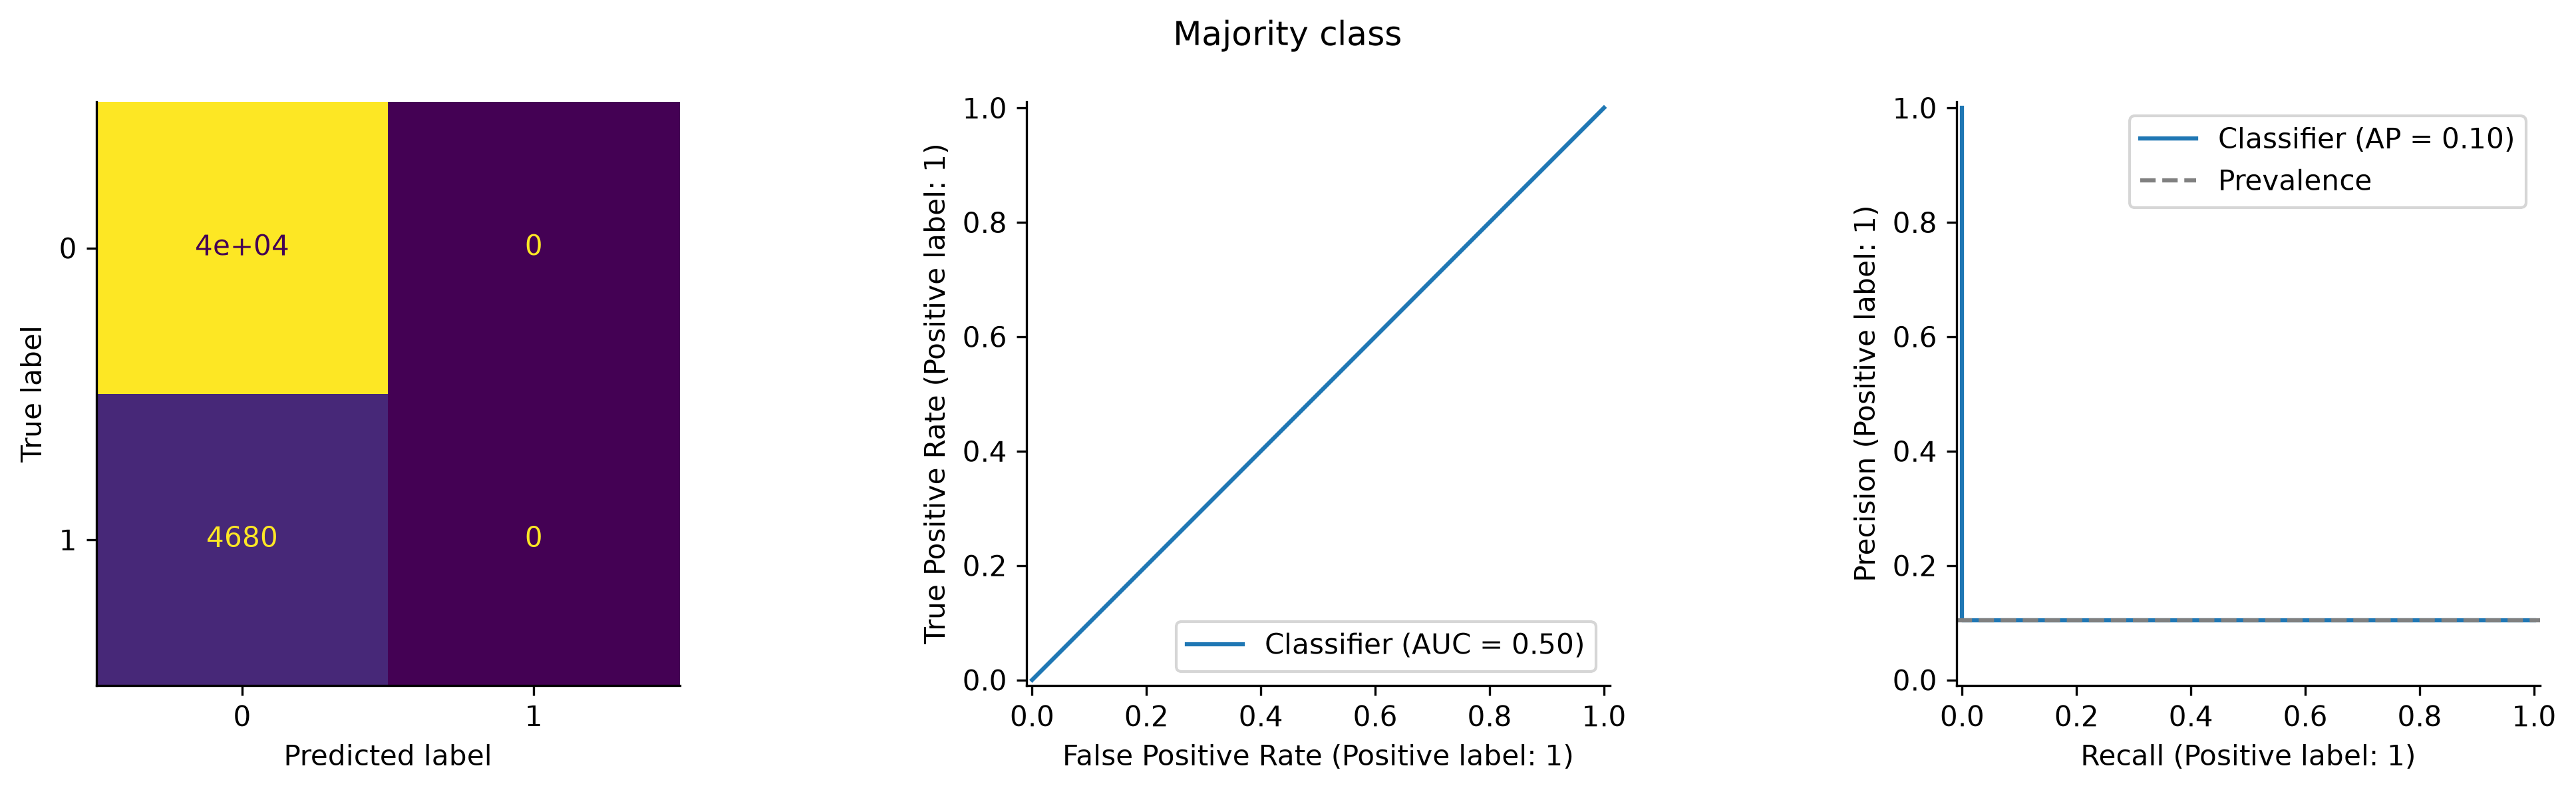

In [14]:
dummy_pipeline = Pipeline([('preprocessing',make_preprocessor()),
                          ('model',DummyClassifier(strategy='most_frequent'))])
dummy_result = log_experiment('Majority class',dummy_pipeline,cached_name='dummy')

## Baseline — plain Logistic Regression

My first learned baseline is an untuned logistic regression (C=1) on the same preprocessing pipeline. It is fast, interpretable and a strong reference for tabular clinical data.

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,Plain logistic regression,plain_logistic,saved_completed_validation_predictions,5.815629,0.708295,0.335889,0.391513,0.331197,0.358838,0.341726,0.876911,0.635725,0.940253,0.923735,0.29253,0.081307,0.293222,0.087978,0.167787,37911,2409,3130,1550


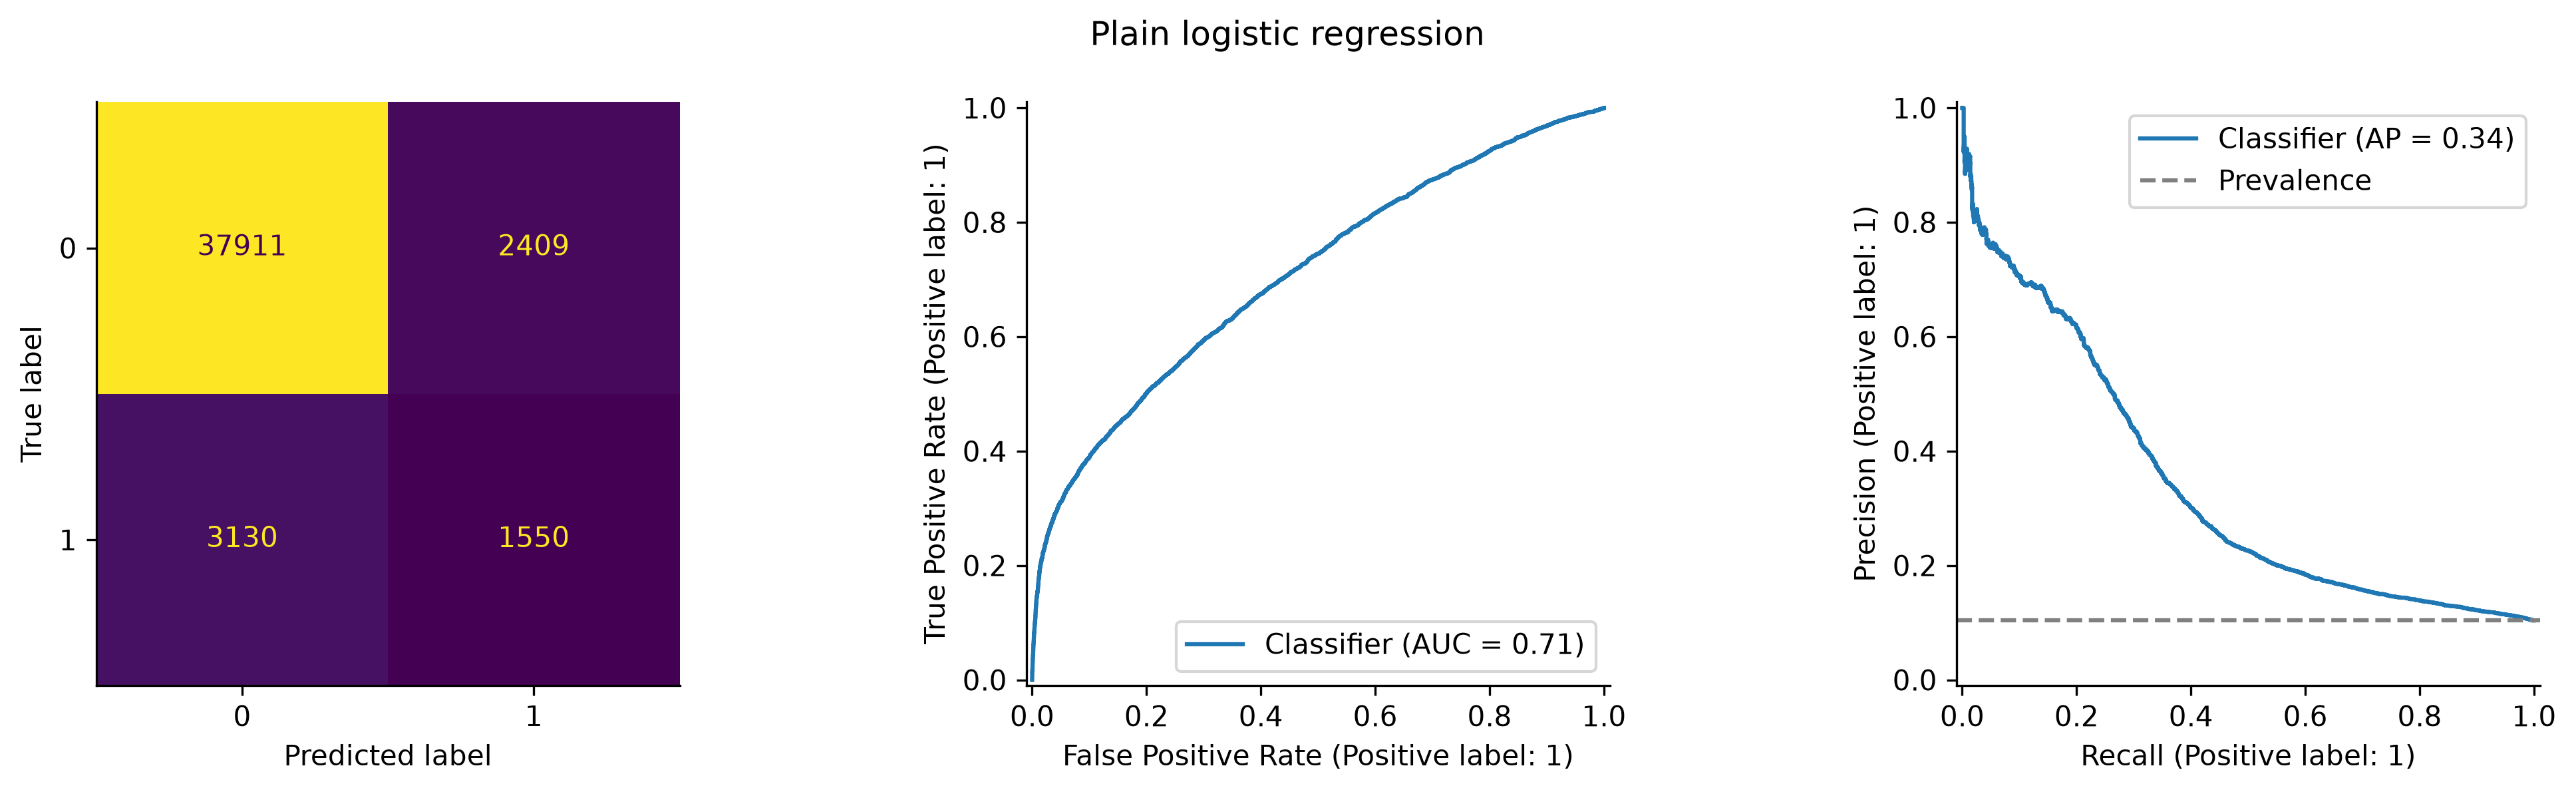

In [15]:
logistic_baseline = Pipeline([('preprocessing',make_preprocessor()),
    ('model',LogisticRegression(C=1.0,max_iter=700,random_state=SEED))])
logistic_result = log_experiment('Plain logistic regression',logistic_baseline,cached_name='plain_logistic')

**Interpretation.** The majority-class model has recall 0 despite ~0.90 accuracy. Plain logistic regression already reaches a validation ROC-AUC of about 0.71 and average precision (AP) of about 0.34, more than three times the 0.104 prevalence that a random ranking would give. Its confusion matrix shows the real difficulty: at the F1-optimal threshold it still misses about two thirds of preterm births.

## Tune all four classical algorithms

I tune each family with `RandomizedSearchCV` using 3-fold stratified cross-validation on a 60,000-row stratified subset of the training partition (6,000 rows for the RBF SVM, whose fit time grows roughly quadratically). The objective is average precision, which suits a 10% minority class. Class weighting (`None` vs `balanced`) is one of the tuned hyperparameters, so I test imbalance handling inside the training folds rather than resampling the data. Each search is also written to TensorBoard (`sklearn_search/`), one step per candidate.

In [16]:
search_spaces={
 'logistic':{'model__C':[.1,1.,10.],'model__class_weight':[None,'balanced']},
 'random_forest':{'model__min_samples_leaf':[10,30],'model__max_features':['sqrt',.5],
                  'model__class_weight':[None,'balanced_subsample']},
 'hist_gradient_boosting':{'model__learning_rate':[.05,.1],'model__max_leaf_nodes':[15,31],
                          'model__l2_regularization':[1.,10.],'model__class_weight':[None,'balanced']},
 'svm':{'model__C':[.5,2.],'model__gamma':['scale',.01],'model__class_weight':[None,'balanced']}}
search_models={
 'logistic':LogisticRegression(max_iter=700,random_state=SEED),
 'random_forest':RandomForestClassifier(n_estimators=120,max_depth=14,n_jobs=1,random_state=SEED),
 'hist_gradient_boosting':HistGradientBoostingClassifier(max_iter=160,early_stopping=True,random_state=SEED),
 'svm':SVC(probability=False,cache_size=256,random_state=SEED)}
searched_estimators={}
display(pd.Series(search_spaces,name='search_space'))
for family,base in search_models.items():
    if RUN_TRAINING:
        ids=svm_ids if family=='svm' else tuning_ids
        estimator=Pipeline([('preprocessing',make_preprocessor()),('model',base)])
        search=RandomizedSearchCV(estimator,search_spaces[family],n_iter=3 if family=='svm' else 4,
            scoring='average_precision',cv=cv,n_jobs=N_JOBS,random_state=SEED,
            refit=False,return_train_score=True,error_score='raise')
        with run_log.operation('search_'+family, search_space=search_spaces[family]), threadpool_limits(limits=4):
            search.fit(X_train.iloc[ids],y_train.iloc[ids])
        results=pd.DataFrame(search.cv_results_)
        run_log.table('cv_'+family,results)
        results.to_csv(EXPERIMENTS/f'cv_{family}.csv',index=False)
        selected=clone(estimator).set_params(**search.best_params_)
        if family=='svm':selected=Pipeline([('model',CalibratedClassifierCV(selected,method='sigmoid',cv=cv,n_jobs=N_JOBS))])
        if family=='random_forest':selected.set_params(model__n_jobs=N_JOBS)
        searched_estimators[family]=selected
        print(family,'selected parameters:',search.best_params_)
    else:
        results=pd.read_csv(TABLES/f'stage5_cv_{family}.csv')
    run_log.cv_results(family,results,'new training-fold search' if RUN_TRAINING else f'saved stage5_cv_{family}.csv')
    display(results[[c for c in ['params','mean_test_score','std_test_score','rank_test_score'] if c in results]])
print('Average precision evaluates ranking across thresholds; threshold policy is assessed separately for sensitivity.')

logistic                  {'model__C': [0.1, 1.0, 10.0], 'model__class_w...
random_forest             {'model__min_samples_leaf': [10, 30], 'model__...
hist_gradient_boosting    {'model__learning_rate': [0.05, 0.1], 'model__...
svm                       {'model__C': [0.5, 2.0], 'model__gamma': ['sca...
Name: search_space, dtype: object

,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__class_weight': None, 'model__C': 0.1}",0.315749,0.002686,3
1,"{'model__class_weight': 'balanced', 'model__C'...",0.313752,0.002813,4
2,"{'model__class_weight': 'balanced', 'model__C'...",0.318749,0.001136,2
3,"{'model__class_weight': None, 'model__C': 1}",0.319541,0.001407,1


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__min_samples_leaf': 30, 'model__max_fe...",0.312917,0.002905,2
1,"{'model__min_samples_leaf': 30, 'model__max_fe...",0.310015,0.004579,4
2,"{'model__min_samples_leaf': 10, 'model__max_fe...",0.319339,0.001148,1
3,"{'model__min_samples_leaf': 30, 'model__max_fe...",0.311816,0.000828,3


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__max_leaf_nodes': 15, 'model__learning...",0.324673,0.004866,1
1,"{'model__max_leaf_nodes': 31, 'model__learning...",0.322666,0.003379,2
2,"{'model__max_leaf_nodes': 31, 'model__learning...",0.321371,0.004088,3
3,"{'model__max_leaf_nodes': 15, 'model__learning...",0.316109,0.002106,4


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__gamma': 0.01, 'model__class_weight': ...",0.299492,0.029224,2
1,"{'model__gamma': 0.01, 'model__class_weight': ...",0.295024,0.032396,3
2,"{'model__gamma': 'scale', 'model__class_weight...",0.303576,0.028623,1


Average precision evaluates ranking across thresholds; threshold policy is assessed separately for sensitivity.


## Tuned Logistic Regression

The search selected C=1 without class weighting, which is the plain baseline configuration, so the two logistic results coincide. That tells me regularisation strength and weighting matter little here.

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,Tuned logistic regression,logistic,saved_completed_validation_predictions,20.122348,0.708295,0.335889,0.391513,0.331197,0.358838,0.341726,0.876911,0.635725,0.940253,0.923735,0.29253,0.081307,0.293222,0.087978,0.167787,37911,2409,3130,1550


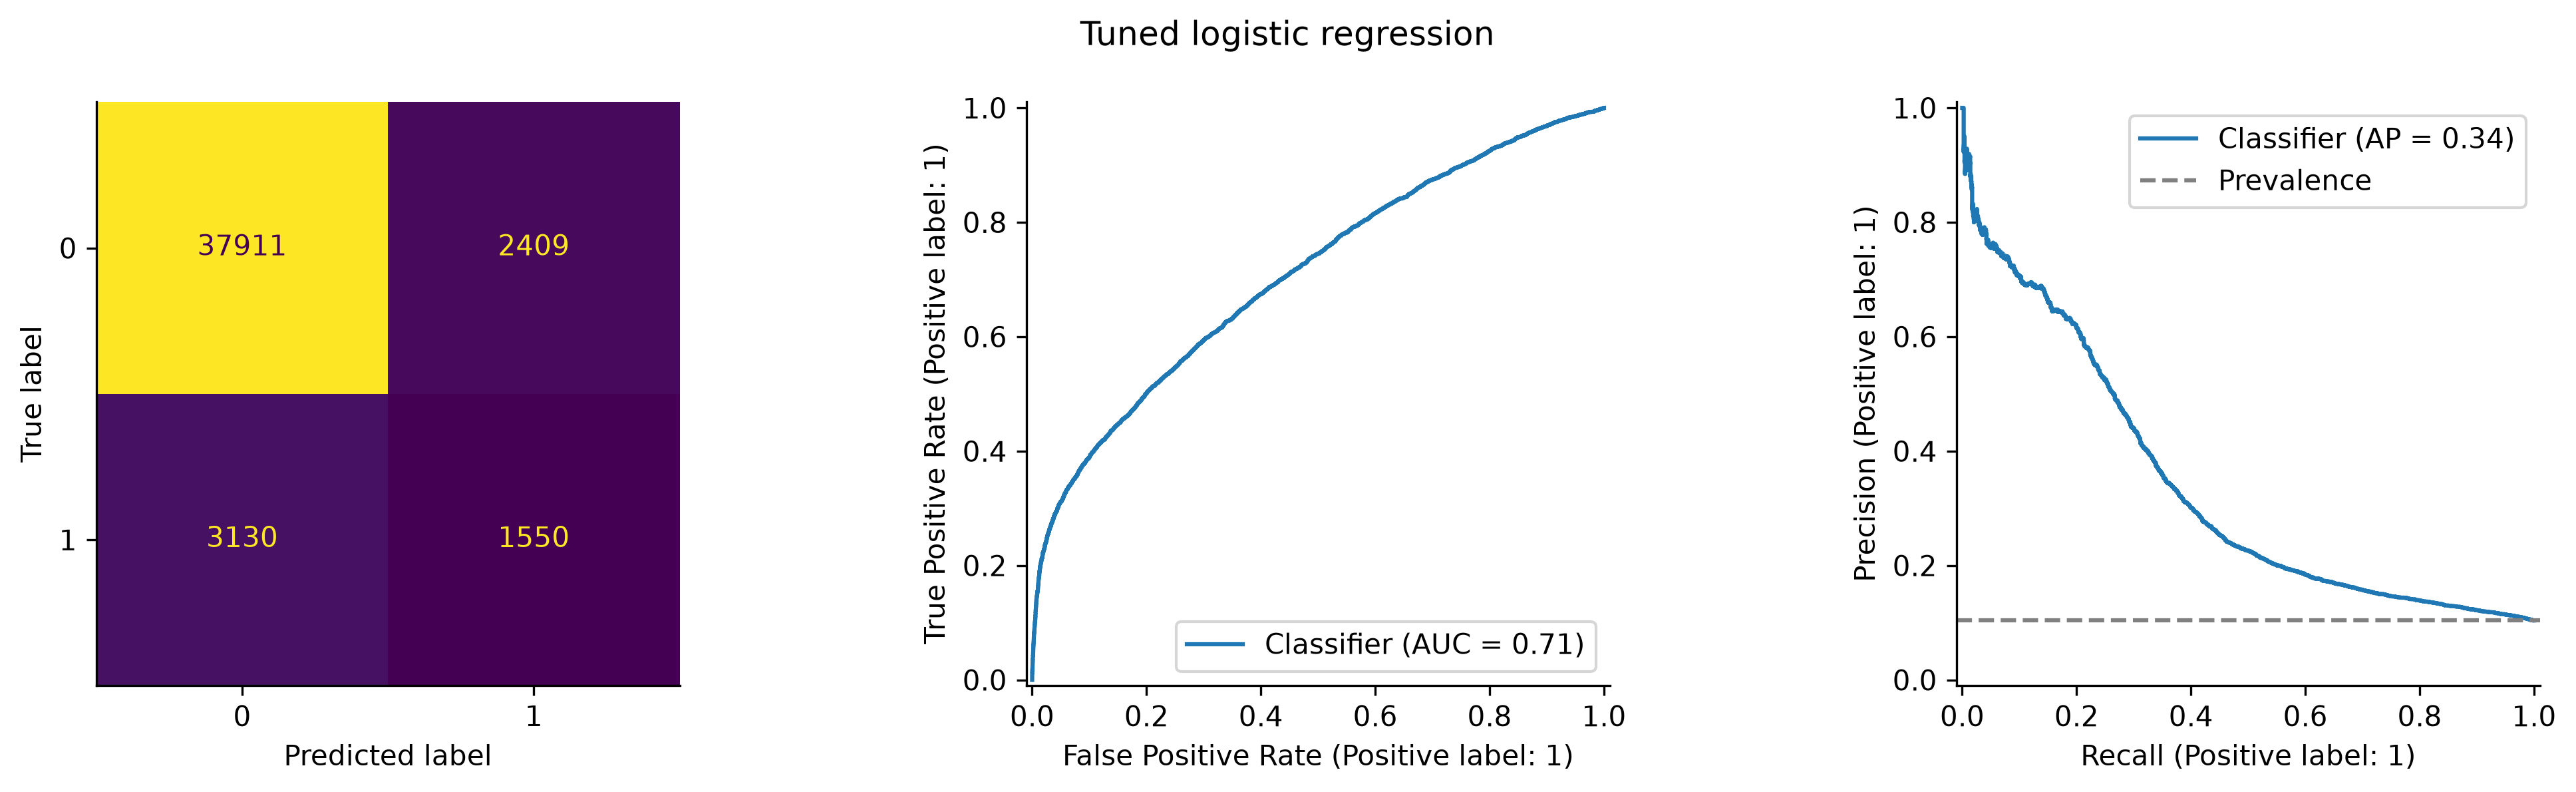

{'model': 'Tuned logistic regression',
 'cache_key': 'logistic',
 'evidence': 'saved_completed_validation_predictions',
 'training_seconds': 20.12234797899873,
 'roc_auc': 0.7082948908730158,
 'average_precision': 0.3358889959721765,
 'precision': 0.39151300833543823,
 'recall': 0.3311965811965812,
 'f1': 0.35883782845236717,
 'f2': 0.3417258256536884,
 'accuracy': 0.8769111111111111,
 'balanced_accuracy': 0.6357247786935287,
 'specificity': np.float64(0.9402529761904762),
 'negative_predictive_value': np.float64(0.9237348017835822),
 'mcc': 0.29253013267704103,
 'brier': 0.08130740301938409,
 'log_loss': 0.2932222081820604,
 'alert_fraction': 0.08797777777777778,
 'threshold': 0.1677869451686137,
 'tn': 37911,
 'fp': 2409,
 'fn': 3130,
 'tp': 1550}

In [17]:
tuned_logistic=searched_estimators.get('logistic',clone(logistic_baseline))
log_experiment('Tuned logistic regression',tuned_logistic,cached_name='logistic')

## Random Forest

120 trees with maximum depth 14; the search chose `min_samples_leaf`, `max_features` and class weighting. I refit the selected configuration on all 210,000 training rows.

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,Random Forest,random_forest,saved_completed_validation_predictions,95.349028,0.710725,0.335309,0.39432,0.335256,0.362398,0.34561,0.877311,0.637742,0.940228,0.924161,0.296204,0.081361,0.293282,0.088422,0.176575,37910,2410,3111,1569


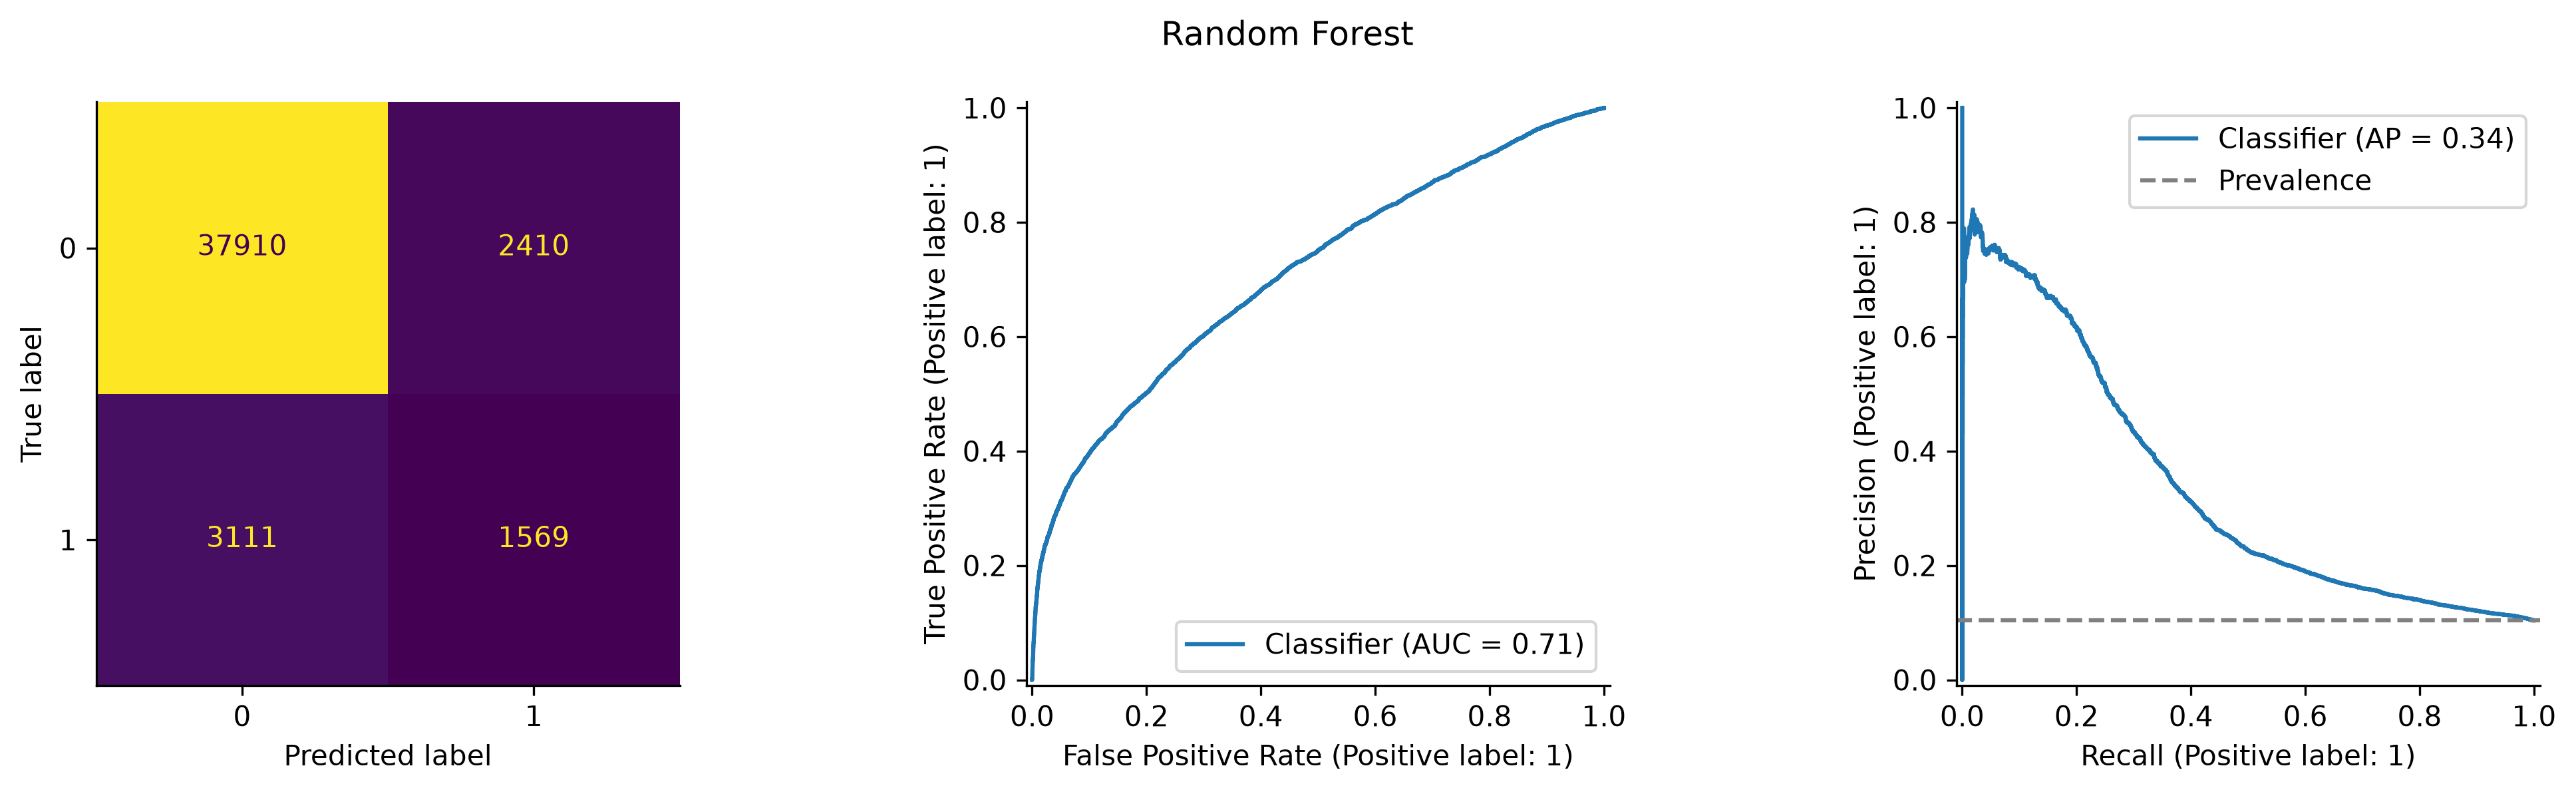

In [18]:
forest_pipeline=Pipeline([('preprocessing',make_preprocessor()),
    ('model',RandomForestClassifier(n_estimators=120,max_depth=14,min_samples_leaf=10,
            max_features='sqrt',class_weight=None,n_jobs=N_JOBS,random_state=SEED))])
forest_pipeline=searched_estimators.get('random_forest',forest_pipeline)
forest_result=log_experiment('Random Forest',forest_pipeline,cached_name='random_forest')

## HistGradientBoosting

Histogram-based gradient boosting with internal early stopping; the search chose learning rate, number of leaves, L2 regularisation and class weighting. I refit the selected configuration on all training rows.

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,HistGradientBoosting,hist_gradient_boosting,saved_completed_validation_predictions,24.496821,0.712484,0.341159,0.418177,0.315598,0.359717,0.33188,0.883156,0.632316,0.949033,0.92276,0.30037,0.081128,0.292292,0.078489,0.200678,38265,2055,3203,1477


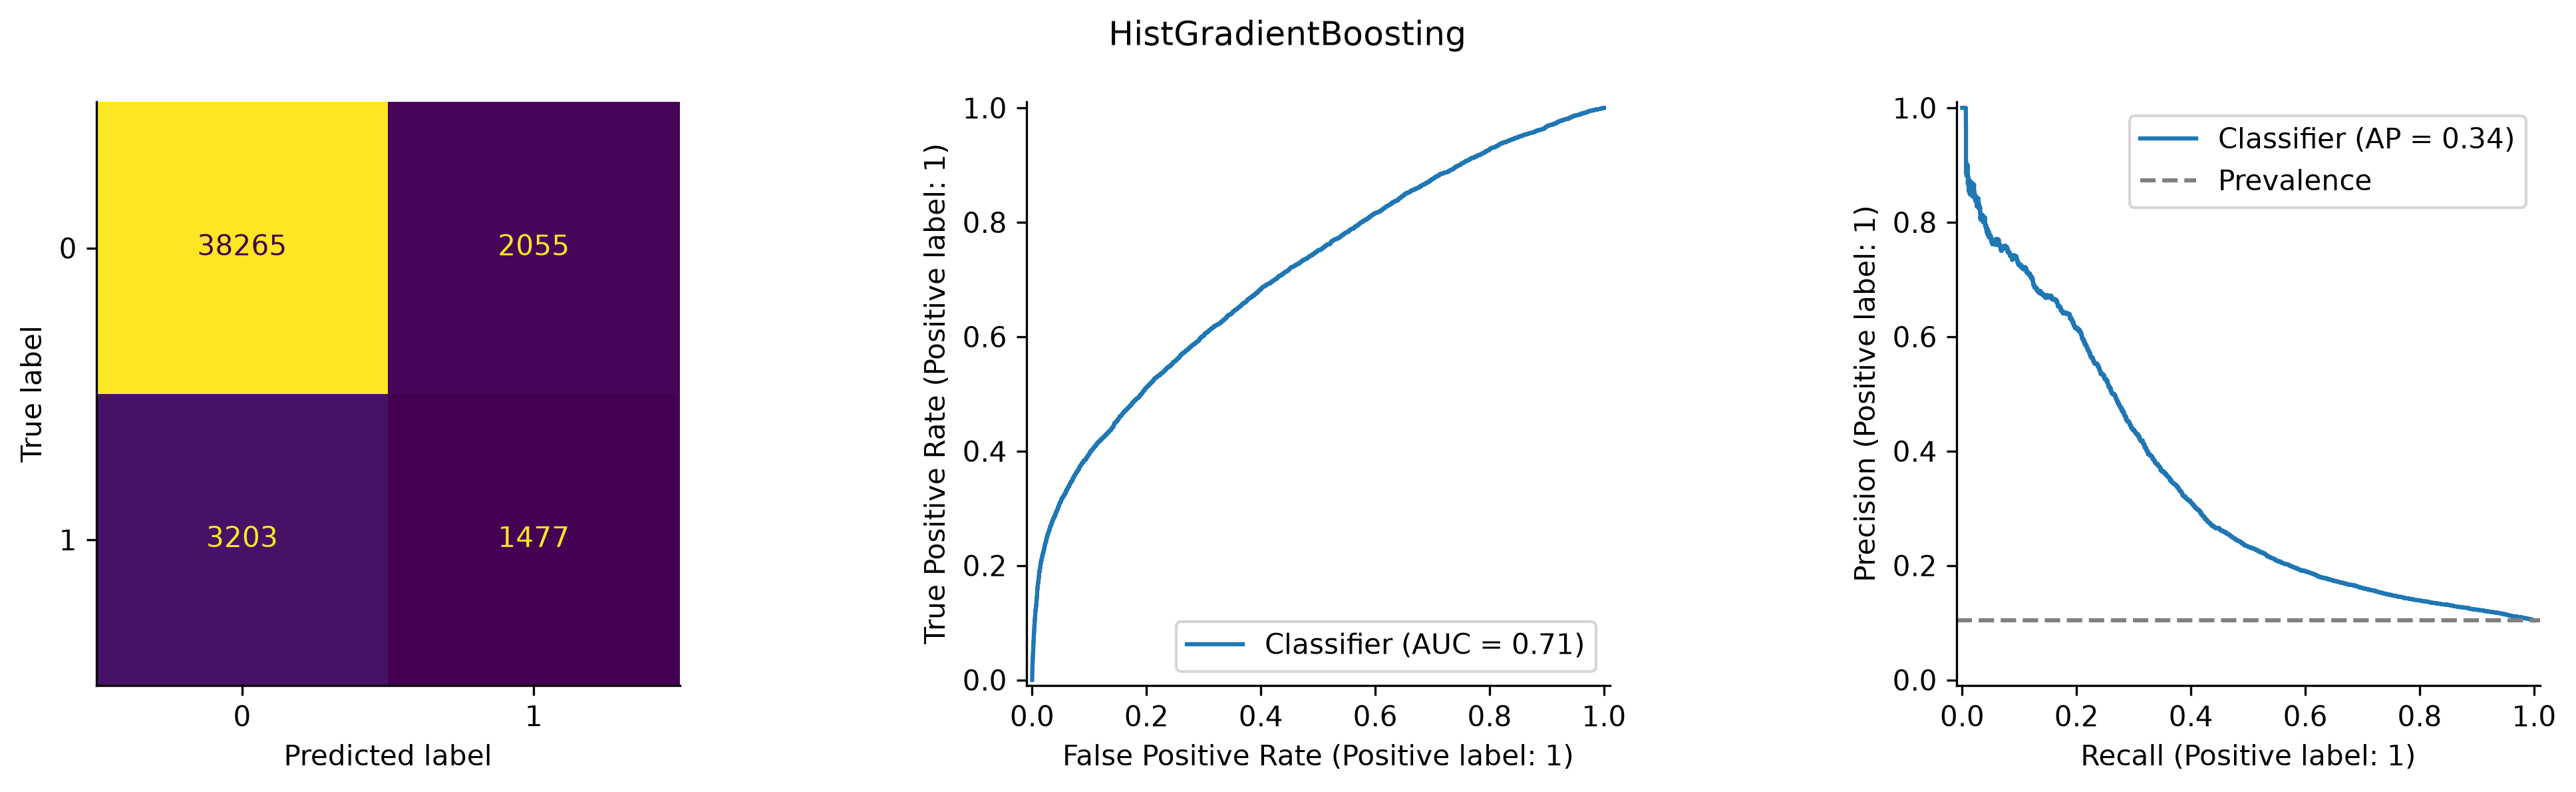

In [19]:
hgb_pipeline=Pipeline([('preprocessing',make_preprocessor()),
    ('model',HistGradientBoostingClassifier(max_iter=160,learning_rate=.05,max_leaf_nodes=15,
        l2_regularization=1.,class_weight=None,early_stopping=True,random_state=SEED))])
hgb_pipeline=searched_estimators.get('hist_gradient_boosting',hgb_pipeline)
hgb_result=log_experiment('HistGradientBoosting',hgb_pipeline,cached_name='hist_gradient_boosting')

## SVM — stratified subsample

An RBF-kernel SVM does not scale to 210,000 rows on my CPU, so I train it on a 6,000-row stratified training subsample and convert its decision function to probabilities with sigmoid (Platt) calibration fitted inside training folds. Its result is therefore a reduced-data comparison, not a like-for-like one.

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,Calibrated SVM,svm,saved_completed_validation_predictions,11.267252,0.644714,0.28595,0.409148,0.27906,0.331809,0.29801,0.883111,0.616142,0.953224,0.919298,0.276211,0.084969,0.306824,0.070933,0.12092,38434,1886,3374,1306


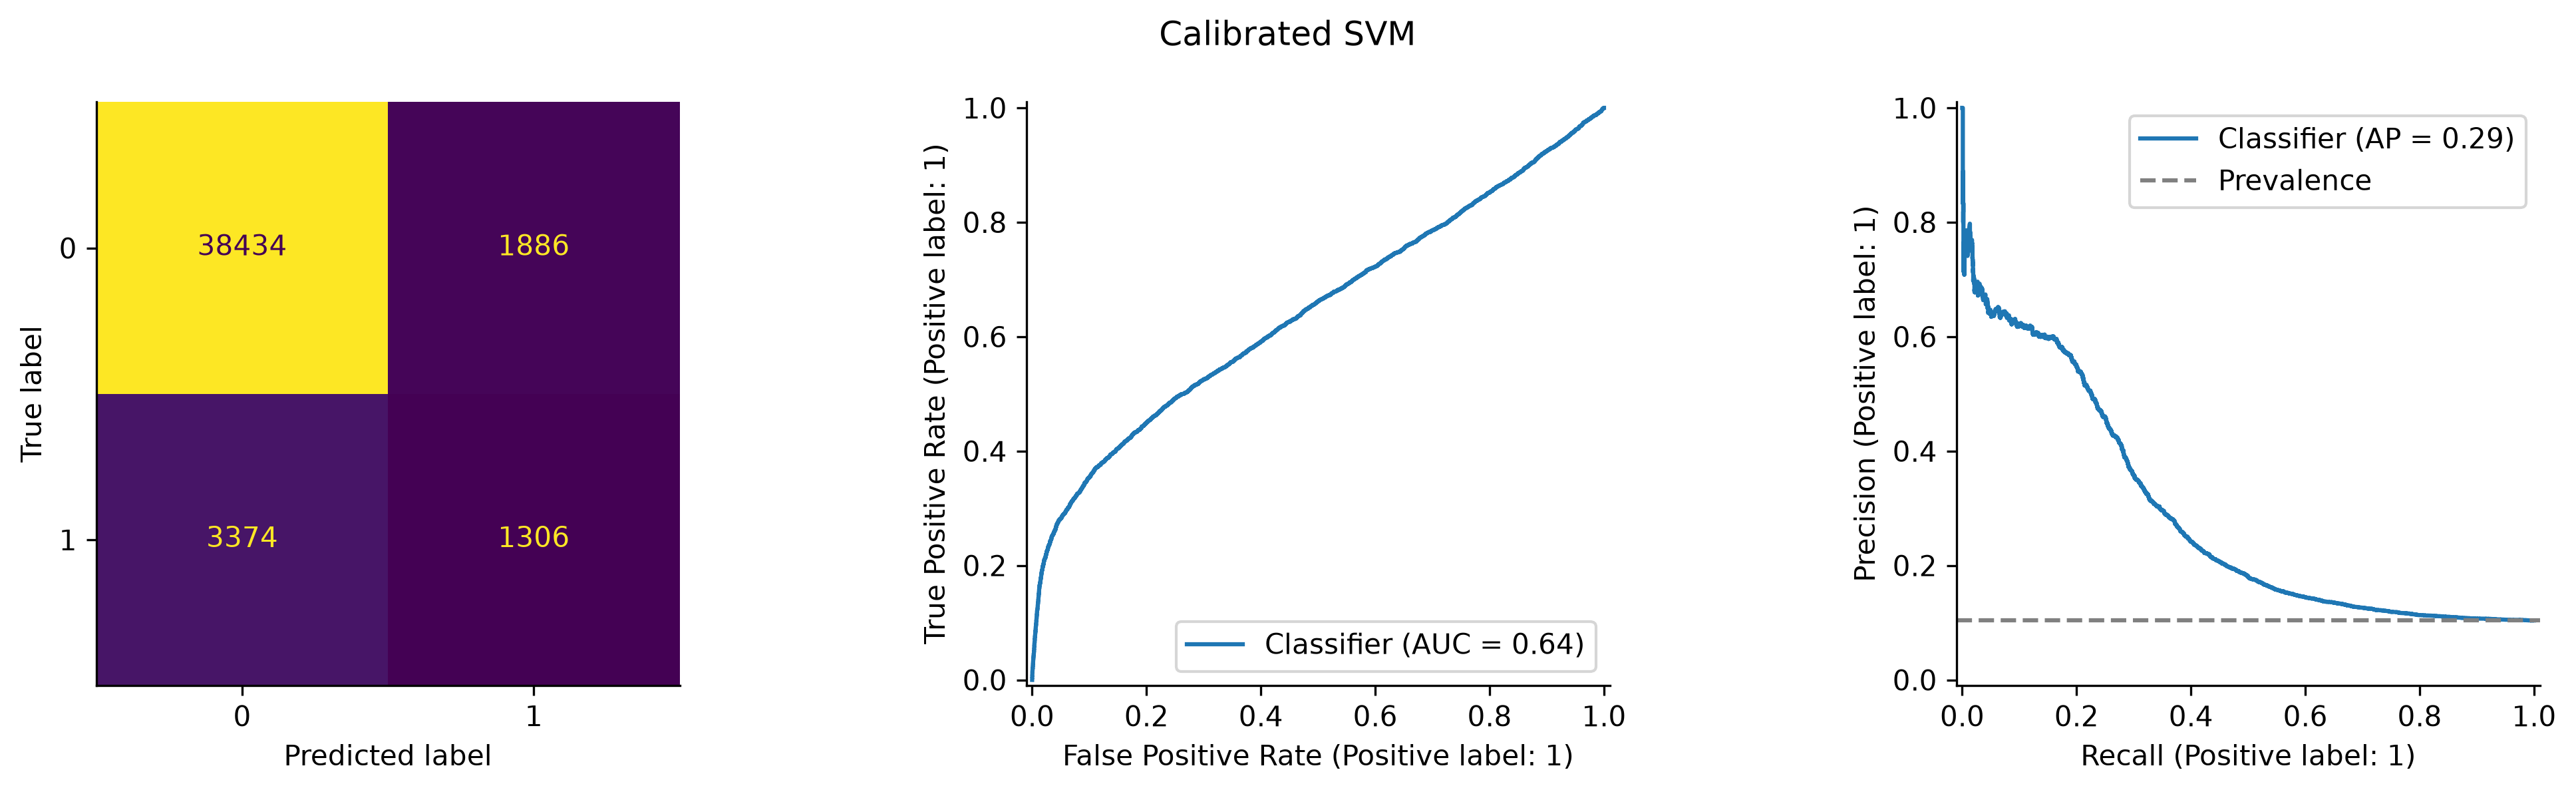

In [20]:
svm_pipeline=Pipeline([('preprocessing',make_preprocessor()),
    ('model',SVC(C=.5,gamma='scale',probability=False,cache_size=256,random_state=SEED))])
svm_calibrated=CalibratedClassifierCV(svm_pipeline,method='sigmoid',cv=cv,n_jobs=N_JOBS)
# Wrap to retain a common explicit pipeline interface for the evaluator.
svm_evaluation_pipeline=Pipeline([('model',svm_calibrated)])
svm_evaluation_pipeline=searched_estimators.get('svm',svm_evaluation_pipeline)
svm_result=log_experiment('Calibrated SVM',svm_evaluation_pipeline,cached_name='svm',fit_indices=svm_ids)

**Interpretation.** Random Forest and HistGradientBoosting finish within about 0.005 AUC of logistic regression, and HistGradientBoosting has the highest validation AP (≈0.341), so it is my classical finalist. The SVM is clearly weaker (AUC ≈0.645), which I attribute mainly to its 35× smaller training sample. Such close results across very different model families suggest that performance is limited by the information in the features rather than by model capacity.

## Class-weight experiments

Mean cross-validated AP for the unweighted and `balanced` candidates of each family. In my completed search the best unweighted candidate beat the best balanced candidate for logistic regression, Random Forest and HistGradientBoosting (the SVM search happened to sample only unweighted settings). Weighting moves the decision boundary, but it does not improve the ranking that AP measures, and I get the same effect by moving the threshold.

In [21]:
display(pd.read_csv(TABLES/'stage5_imbalance_strategies.csv'))

,model,params,mean_test_score,std_test_score
0,logistic,"{'model__class_weight': None, 'model__C': 0.1}",0.315749,0.002686
1,logistic,"{'model__class_weight': 'balanced', 'model__C'...",0.313752,0.002813
2,logistic,"{'model__class_weight': 'balanced', 'model__C'...",0.318749,0.001136
3,logistic,"{'model__class_weight': None, 'model__C': 1}",0.319541,0.001407
4,random_forest,"{'model__min_samples_leaf': 30, 'model__max_fe...",0.312917,0.002905
5,random_forest,"{'model__min_samples_leaf': 30, 'model__max_fe...",0.310015,0.004579
6,random_forest,"{'model__min_samples_leaf': 10, 'model__max_fe...",0.319339,0.001148
7,random_forest,"{'model__min_samples_leaf': 30, 'model__max_fe...",0.311816,0.000828
8,hist_gradient_boosting,"{'model__max_leaf_nodes': 15, 'model__learning...",0.324673,0.004866
9,hist_gradient_boosting,"{'model__max_leaf_nodes': 31, 'model__learning...",0.322666,0.003379


## Classical learning curves

I compute learning curves with training-fold cross-validation only (sizes 10%, 40% and 100% of the 60,000-row tuning subset, i.e. 4,000 → 40,000 records in each training fold). A large gap between training and CV ROC-AUC indicates variance; low and converging curves indicate bias or limited information. The curves are also written to TensorBoard (`learning_curves/`, step = training records).

,model,training_rows,train_auc_mean,train_auc_std,cv_auc_mean,cv_auc_std
0,hist_gradient_boosting,4000,0.827809,0.005287,0.677933,0.008038
1,hist_gradient_boosting,16000,0.762559,0.012467,0.696827,0.004091
2,hist_gradient_boosting,40000,0.739947,0.003813,0.701276,0.002425
3,plain_logistic,4000,0.747369,0.004653,0.678075,0.002960
4,plain_logistic,16000,0.720322,0.006074,0.694676,0.002806
5,plain_logistic,40000,0.711049,0.000288,0.700134,0.002899


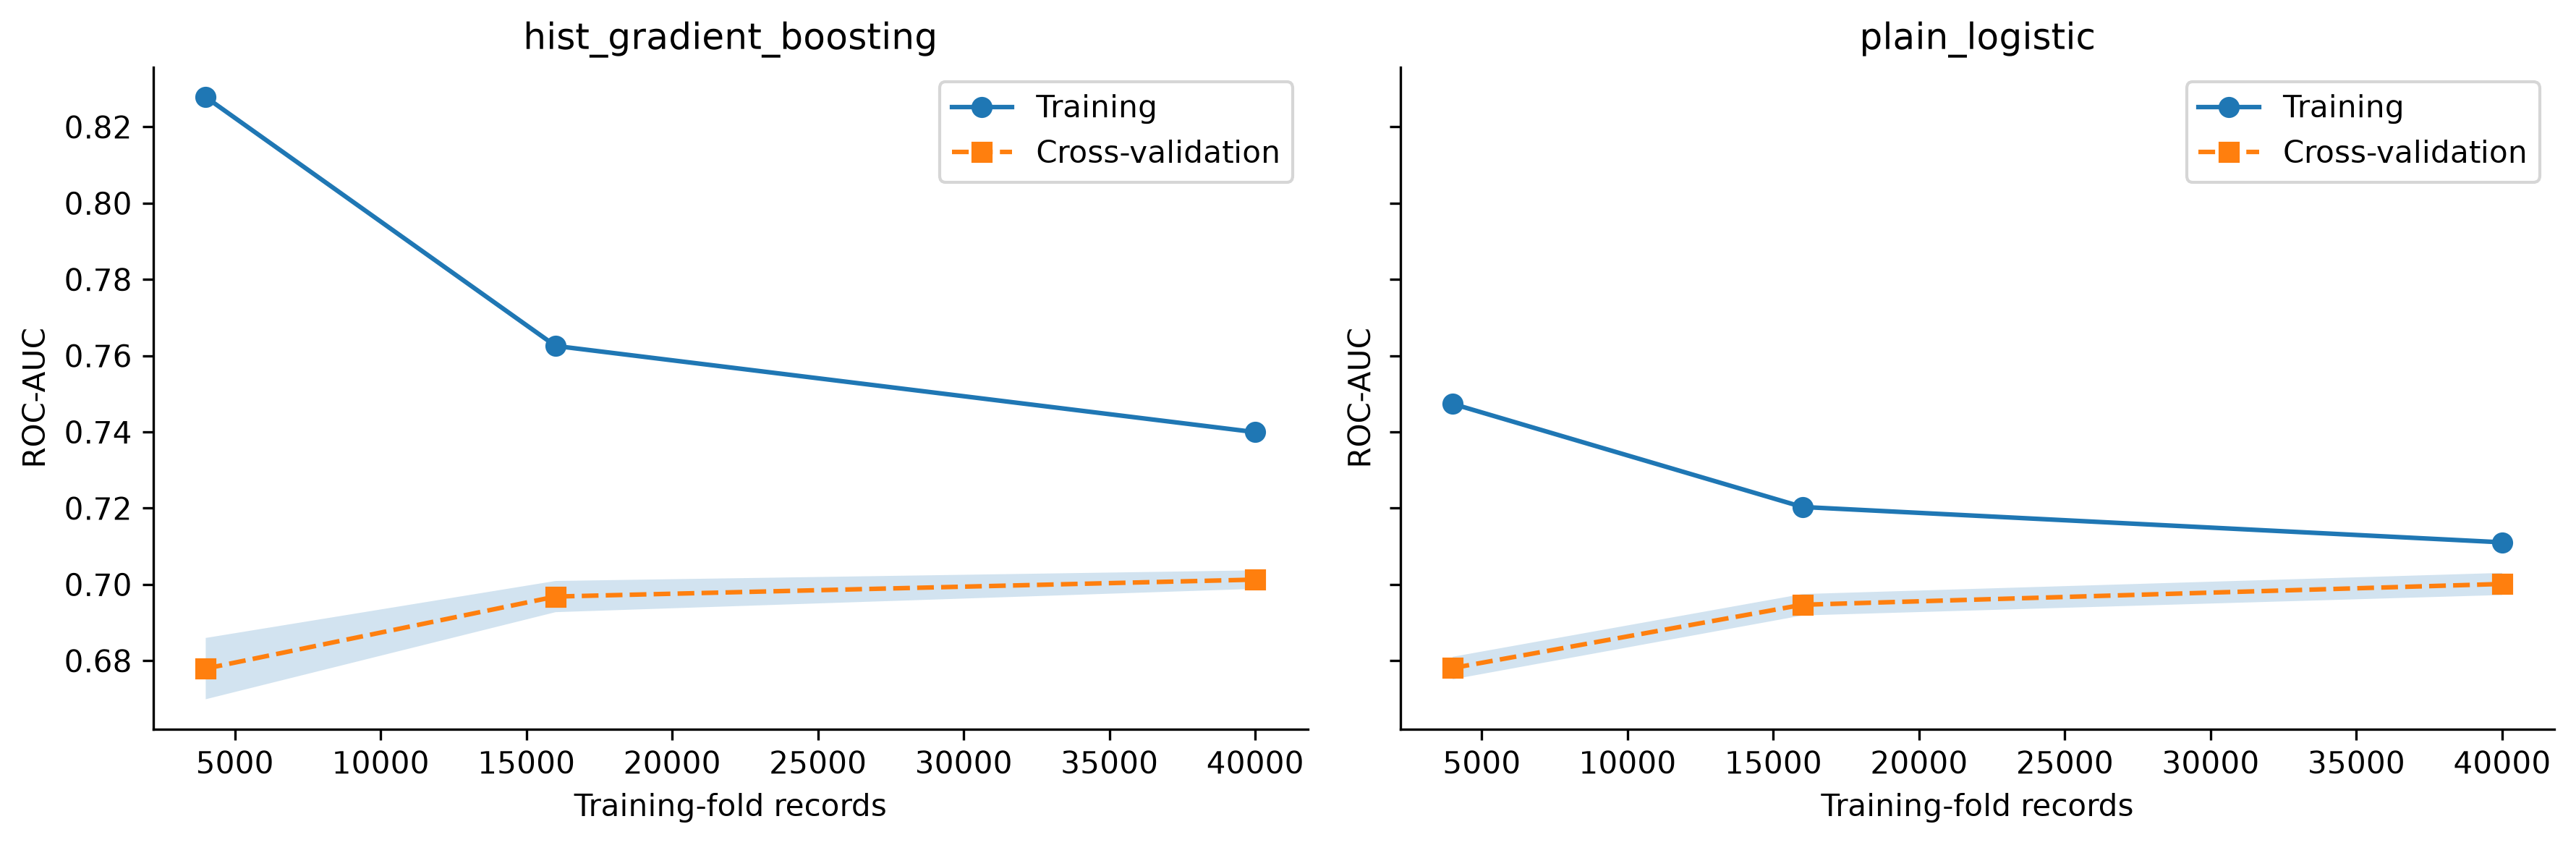

In [22]:
learning_results=pd.read_csv(TABLES/'stage5_learning_curves.csv')
curve_source='saved stage5_learning_curves.csv'
if RUN_TRAINING:
    curve_rows=[]
    for label,estimator in [('hist_gradient_boosting',hgb_pipeline),('plain_logistic',logistic_baseline)]:
        with run_log.operation('learning_curve_'+label), threadpool_limits(limits=4):
            sizes,training_scores,fold_scores=learning_curve(clone(estimator),
                X_train.iloc[tuning_ids],y_train.iloc[tuning_ids],train_sizes=[.1,.4,1.],
                cv=cv,scoring='roc_auc',n_jobs=N_JOBS,shuffle=True,random_state=SEED)
        for size,a,b in zip(sizes,training_scores,fold_scores):
            curve_rows.append(dict(model=label,training_rows=int(size),train_auc_mean=a.mean(),train_auc_std=a.std(),
                                   cv_auc_mean=b.mean(),cv_auc_std=b.std()))
    learning_results=pd.DataFrame(curve_rows)
    learning_results.to_csv(RESULT_TABLES/'learning_curves.csv',index=False)
    curve_source='new training-fold CV'
display(learning_results)
fig,axes=plt.subplots(1,learning_results.model.nunique(),figsize=(12,4),sharey=True)
for ax,(model,group) in zip(np.atleast_1d(axes),learning_results.groupby('model')):
    ax.plot(group.training_rows,group.train_auc_mean,'o-',label='Training')
    ax.plot(group.training_rows,group.cv_auc_mean,'s--',label='Cross-validation')
    ax.fill_between(group.training_rows,group.cv_auc_mean-group.cv_auc_std,group.cv_auc_mean+group.cv_auc_std,alpha=.2)
    ax.set(title=model,xlabel='Training-fold records',ylabel='ROC-AUC');ax.legend()
    run_log.learning_curve(model,group.training_rows.to_numpy(),group.train_auc_mean.to_numpy()[:,None],
                           group.cv_auc_mean.to_numpy()[:,None],curve_source)
save_figure('classical_learning_curves')

**Interpretation.** For HistGradientBoosting the training AUC falls from about 0.83 to 0.74 while the CV AUC rises from about 0.68 to 0.70 as the data grows: the gap shrinks, so variance is being controlled and more data still helps slightly. Logistic regression starts with a smaller gap and converges at a similar CV AUC (~0.70). Both curves flatten near 0.70, which points to limited predictive information in pre-delivery records rather than a lack of model capacity; a larger model alone would not fix this.

## Feature and timing checks

I test my feature decisions with matched HistGradientBoosting fits: raw core inputs vs my engineered inputs, adding later-pregnancy (time-dependent) fields, restricting to singleton births, and an alternative gestation definition. The time-dependent variant is a diagnostic only: those fields are recorded late in pregnancy, so I never allow them into model selection.

In [23]:
ablations=pd.read_csv(TABLES/'stage5_ablations.csv')
display(ablations)
if RUN_TRAINING:
    new_ablation_rows=[]
    for name,engineered,time_dependent,singleton in [
        ('baseline_features',False,False,False),('engineered_core',True,False,False),
        ('time_dependent_diagnostic',True,True,False),('singleton_only',True,False,True)]:
        tr=train.loc[train.DPLURAL.eq(1)] if singleton else train
        va=validation.loc[validation.DPLURAL.eq(1)] if singleton else validation
        a,nums,cats=engineer_features(tr,engineered,time_dependent)
        b,_,_=engineer_features(va,engineered,time_dependent)
        estimator=Pipeline([('preprocessing',make_preprocessor(nums,cats)),
            ('model',clone(hgb_pipeline.named_steps['model']))])
        estimator.fit(a,tr.target)
        p=estimator.predict_proba(b)[:,1]
        new_ablation_rows.append(dict(experiment=name,**score_binary(va.target,p,best_f1_threshold(va.target,p))))
    display(pd.DataFrame(new_ablation_rows))

,experiment,training_rows,validation_rows,training_seconds,roc_auc,average_precision,precision,recall,f1,accuracy,brier,threshold,delta_AP_vs_core
0,baseline_features,210000,45000,7.811796,0.712881,0.340928,0.375663,0.348291,0.361459,0.872022,0.081112,0.171054,-0.000231
1,engineered_core,210000,45000,9.273327,0.712484,0.341159,0.418177,0.315598,0.359717,0.883156,0.081128,0.200678,0.000000
2,time_dependent_added,210000,45000,15.871148,0.804076,0.461132,0.412231,0.455128,0.432619,0.875844,0.073284,0.193836,0.119973
3,singleton_only,203568,43600,9.597811,0.653130,0.177478,0.185666,0.331490,0.238019,0.815115,0.076632,0.114876,-0.163681
4,GESTREC3_sensitivity,210000,45000,9.502517,0.683098,0.313878,0.325819,0.334067,0.329891,0.835600,0.096313,0.163196,-0.027281


**Interpretation.** Feature engineering changed AP by only ≈0.0002, so my engineered features help interpretation more than prediction. Adding later-pregnancy fields raises AUC from 0.71 to 0.80, which shows how easily timing leakage could inflate a score, and is why I keep them out of the core model. The singleton-only model drops to AUC ≈0.65 and AP ≈0.18: a large part of the signal comes from multiple pregnancies (twins and more), which I examine in the error analysis below.

## Neural tuning evidence

I implemented both Keras APIs and tuned them with a seeded random search over depth, width, dropout, L2, learning rate, batch size and optimizer: three configurations per API on the 60,000-row tuning subset (≤16 epochs each), then a refit of the best configuration on all training rows (≤24 epochs). This is a bounded search on a CPU, not an exhaustive one.

In [24]:
display(pd.Series(json.loads((TABLES/'stage6_search_space.json').read_text())))
display(pd.read_csv(TABLES/'stage6_tuning.csv'))
display(recorded_deep)

space                   {'depth': [1, 2, 3], 'units': [32, 64, 96], 'd...
trials_per_api                                                          3
realized_trials         [{'depth': 1, 'units': 96, 'dropout': 0.3, 'le...
max_epochs_per_trial                                                   16
final_max_epochs                                                       24
tuning_training_rows                                                60000
final_training_rows                                                210000
class_weights           {'0': 0.5580416458508275, '1': 4.807252083142569}
selection               external sklearn validation average_precision ...
seed                                                                   42
dtype: object

,api,trial,phase,training_rows,epochs_run,training_seconds,parameters,roc_auc,average_precision,precision,recall,f1,accuracy,brier,threshold
0,sequential,0,tuning,60000,16,13.590462,"{""depth"": 1, ""units"": 96, ""dropout"": 0.3, ""lea...",0.705240,0.326508,0.365313,0.355556,0.360368,0.868733,0.198130,0.629656
1,sequential,1,tuning,60000,16,10.921084,"{""depth"": 3, ""units"": 32, ""dropout"": 0.15, ""le...",0.702605,0.323270,0.396926,0.320085,0.354388,0.878711,0.184606,0.627596
2,sequential,2,tuning,60000,16,17.363739,"{""depth"": 3, ""units"": 96, ""dropout"": 0.3, ""lea...",0.704026,0.324861,0.386190,0.334615,0.358558,0.875489,0.188416,0.623030
3,functional,0,tuning,60000,16,28.908229,"{""depth"": 1, ""units"": 96, ""dropout"": 0.3, ""lea...",0.706791,0.329350,0.428402,0.308761,0.358872,0.885267,0.197568,0.679170
4,functional,1,tuning,60000,16,29.618380,"{""depth"": 3, ""units"": 32, ""dropout"": 0.15, ""le...",0.701288,0.324219,0.390525,0.325855,0.355271,0.877000,0.193985,0.637645
5,functional,2,tuning,60000,16,30.369504,"{""depth"": 3, ""units"": 96, ""dropout"": 0.3, ""lea...",0.697053,0.321288,0.399142,0.317949,0.353949,0.879289,0.184606,0.611167


,model,api,training_rows,epochs_run,best_epoch,training_seconds,refit_seconds,best_parameters,roc_auc,average_precision,precision,recall,f1,accuracy,brier,threshold
0,dl_functional,functional,210000,23,19,182.520664,90.634282,"{""depth"": 1, ""units"": 96, ""dropout"": 0.3, ""lea...",0.712922,0.338774,0.374048,0.346154,0.359561,0.871756,0.199437,0.634973
1,dl_sequential,sequential,210000,23,19,96.704098,52.935663,"{""depth"": 1, ""units"": 96, ""dropout"": 0.3, ""lea...",0.713200,0.334237,0.375087,0.347436,0.360732,0.871933,0.201287,0.637516


## Numeric preprocessing and embedding vocabulary

For the Sequential network I reuse the one-hot pipeline. For the Functional network I fit a median imputer + scaler for numeric inputs and an ordinal encoder for categories on training rows only. Index 0 is reserved for unseen categories, so validation and test values never leak into the vocabulary.

In [25]:
if RUN_TRAINING and RUN_DEEP_LEARNING:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(SEED)
    tf.config.experimental.enable_op_determinism()
    try:
        tf.config.threading.set_intra_op_parallelism_threads(4)
        tf.config.threading.set_inter_op_parallelism_threads(2)
    except RuntimeError:
        pass  # TensorFlow already initialised (TensorBoard logging); TF_NUM_*_THREADS from setup apply
    numeric_dl=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
                         ('scale',StandardScaler())])
    numeric_dl.fit(X_train[numeric_features])
    ordinal_dl=OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1,dtype=np.int32)
    ordinal_dl.fit(X_train[categorical_features])
    vocab_sizes=[len(c)+1 for c in ordinal_dl.categories_]
    def embedding_inputs(frame):
        ids=ordinal_dl.transform(frame[categorical_features])+1
        result={'numeric':numeric_dl.transform(frame[numeric_features]).astype('float32')}
        result.update({f'category_{i}':ids[:,i:i+1].astype('int32') for i in range(len(categorical_features))})
        return result
    sequential_train=preprocessor.transform(X_train).astype('float32')
    sequential_validation=preprocessor.transform(X_validation).astype('float32')
    functional_train=embedding_inputs(X_train)
    functional_validation=embedding_inputs(X_validation)
else:
    print('TensorFlow training disabled; the actual model and dataset code is below.')

TensorFlow training disabled; the actual model and dataset code is below.


## tf.data input pipelines

All networks read data through `tf.data`: `from_tensor_slices` → `shuffle` (training only, seeded) → `batch` → `prefetch`. Validation and test pipelines are not shuffled, so predictions stay aligned with labels.

In [26]:
def make_tf_dataset(inputs,labels=None,training=False,batch_size=512):
    import tensorflow as tf
    payload=inputs if labels is None else (inputs,np.asarray(labels,dtype='float32'))
    ds=tf.data.Dataset.from_tensor_slices(payload)
    if training: ds=ds.shuffle(20000,seed=SEED,reshuffle_each_iteration=True)
    options=tf.data.Options()
    options.deterministic=True
    options.threading.private_threadpool_size=4
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE).with_options(options)

if RUN_TRAINING and RUN_DEEP_LEARNING:
    sequential_training_ds=make_tf_dataset(sequential_train,y_train,training=True)
    sequential_validation_ds=make_tf_dataset(sequential_validation,y_validation)
    functional_training_ds=make_tf_dataset(functional_train,y_train,training=True)
    functional_validation_ds=make_tf_dataset(functional_validation,y_validation)
    print(sequential_training_ds.element_spec)
    print(functional_training_ds.element_spec)

## Sequential MLP

Sequential API: one-hot/scaled features → Dense(ReLU) blocks with BatchNormalization, Dropout and L2 → sigmoid output.

In [27]:
def build_sequential(input_dim,depth=1,units=96,dropout=.3,l2=.0001,learning_rate=.0005,optimizer='rmsprop'):
    import tensorflow as tf
    model=tf.keras.Sequential([tf.keras.layers.Input(shape=(input_dim,))],name='sequential_mlp')
    for _ in range(depth):
        model.add(tf.keras.layers.Dense(units,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(l2)))
        model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(1,activation='sigmoid'))
    opt=(tf.keras.optimizers.Adam if optimizer=='adam' else tf.keras.optimizers.RMSprop)(learning_rate)
    model.compile(optimizer=opt,loss='binary_crossentropy',
        metrics=[tf.keras.metrics.AUC(name='roc_auc'),tf.keras.metrics.AUC(name='pr_auc',curve='PR')])
    return model

if RUN_TRAINING and RUN_DEEP_LEARNING:
    sequential_model=build_sequential(sequential_train.shape[1])
    sequential_model.summary()
else:
    display(Markdown((TABLES/'stage6_architecture_sequential.md').read_text()))

```text
Model: "sequential_mlp"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 96)             │        10,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96)             │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            97 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 21,892 (85.52 KB)
 Trainable params: 10,849 (42.38 KB)
 Non-trainable params: 192 (768.00 B)
 Optimizer params: 10,851 (42.39 KB)

```


## Functional model with embeddings

Functional API: a numeric input plus one integer input per categorical feature. Each category gets a learned embedding (dimension min(8, ⌈√vocabulary⌉)); the embeddings are concatenated with the numeric vector before the dense blocks.

In [28]:
def build_functional(numeric_dim,vocabulary_sizes,depth=1,units=96,dropout=.3,l2=.0001,learning_rate=.0005,optimizer='rmsprop'):
    import tensorflow as tf
    inputs={'numeric':tf.keras.Input(shape=(numeric_dim,),name='numeric')}
    encoded=[inputs['numeric']]
    for i,size in enumerate(vocabulary_sizes):
        name=f'category_{i}'
        inputs[name]=tf.keras.Input(shape=(1,),dtype='int32',name=name)
        dimension=min(8,max(2,int(np.ceil(np.sqrt(size)))))
        embedding=tf.keras.layers.Embedding(size,dimension)(inputs[name])
        encoded.append(tf.keras.layers.Flatten()(embedding))
    z=tf.keras.layers.Concatenate()(encoded)
    for _ in range(depth):
        z=tf.keras.layers.Dense(units,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(l2))(z)
        z=tf.keras.layers.BatchNormalization()(z)
        z=tf.keras.layers.Dropout(dropout)(z)
    outputs=tf.keras.layers.Dense(1,activation='sigmoid')(z)
    model=tf.keras.Model(inputs=inputs,outputs=outputs,name='functional_embeddings')
    opt=(tf.keras.optimizers.Adam if optimizer=='adam' else tf.keras.optimizers.RMSprop)(learning_rate)
    model.compile(optimizer=opt,loss='binary_crossentropy',
        metrics=[tf.keras.metrics.AUC(name='roc_auc'),tf.keras.metrics.AUC(name='pr_auc',curve='PR')])
    return model

if RUN_TRAINING and RUN_DEEP_LEARNING:
    functional_model=build_functional(functional_train['numeric'].shape[1],vocab_sizes)
    functional_model.summary()
else:
    display(Markdown((TABLES/'stage6_architecture_functional.md').read_text()))

```text
Model: "functional_embeddings"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ c_mracehisp         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_dmar (InputLayer) │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_meduc             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_lbo_rec           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_tbo_rec           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_rf_pdiab          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_rf_phype          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_rf_ppterm         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_rf_inftr          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_rf_fedrg          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_rf_artec          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_rf_cesar          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_dplural           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_age_band          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c_bmi_category      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_mracehisp │ (None, 1, 3)      │         27 │ c_mracehisp[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_dmar      │ (None, 1, 2)      │          8 │ c_dmar[0][0]      │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_meduc     │ (None, 1, 4)      │         40 │ c_meduc[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_lbo_rec   │ (None, 1, 4)      │         40 │ c_lbo_rec[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_tbo_rec   │ (None, 1, 4)      │         40 │ c_tbo_rec[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_rf_pdiab  │ (None, 1, 2)      │          8 │ c_rf_pdiab[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_rf_phype  │ (None, 1, 2)      │          8 │ c_rf_phype[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_rf_ppterm │ (None, 1, 2)      │          8 │ c_rf_ppterm[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_rf_inftr  │ (None, 1, 2)      │          8 │ c_rf_inftr[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_rf_fedrg  │ (None, 1, 3)      │         15 │ c_rf_fedrg[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_rf_artec  │ (None, 1, 3)      │         15 │ c_rf_artec[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_rf_cesar  │ (None, 1, 2)      │          8 │ c_rf_cesar[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_dplural   │ (None, 1, 3)      │         15 │ c_dplural[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_age_band  │ (None, 1, 3)      │         21 │ c_age_band[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_bmi_cate… │ (None, 1, 3)      │         24 │ c_bmi_category[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 3)         │          0 │ embedding_mraceh… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 2)         │          0 │ embedding_dmar[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 4)         │          0 │ embedding_meduc[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 4)         │          0 │ embedding_lbo_re… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_4 (Flatten) │ (None, 4)         │          0 │ embedding_tbo_re… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_5 (Flatten) │ (None, 2)         │          0 │ embedding_rf_pdi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_6 (Flatten) │ (None, 2)         │          0 │ embedding_rf_phy… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_7 (Flatten) │ (None, 2)         │          0 │ embedding_rf_ppt… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_8 (Flatten) │ (None, 2)         │          0 │ embedding_rf_inf… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_9 (Flatten) │ (None, 3)         │          0 │ embedding_rf_fed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_10          │ (None, 3)         │          0 │ embedding_rf_art… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_11          │ (None, 2)         │          0 │ embedding_rf_ces… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_12          │ (None, 3)         │          0 │ embedding_dplura… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_13          │ (None, 3)         │          0 │ embedding_age_ba… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_14          │ (None, 3)         │          0 │ embedding_bmi_ca… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 73)        │          0 │ numeric[0][0],    │
│ (Concatenate)       │                   │            │ flatten[0][0],    │
│                     │                   │            │ flatten_1[0][0],  │
│                     │                   │            │ flatten_2[0][0],  │
│                     │                   │            │ flatten_3[0][0],  │
│                     │                   │            │ flatten_4[0][0],  │
│                     │                   │            │ flatten_5[0][0],  │
│                     │                   │            │ flatten_6[0][0],  │
│                     │                   │            │ flatten_7[0][0],  │
│                     │                   │            │ flatten_8[0][0],  │
│                     │                   │            │ flatten_9[0][0],  │
│                     │                   │            │ flatten_10[0][0], │
│                     │                   │            │ flatten_11[0][0], │
│                     │                   │            │ flatten_12[0][0], │
│                     │                   │            │ flatten_13[0][0], │
│                     │                   │            │ flatten_14[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 96)        │      7,104 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 96)        │        384 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 96)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         97 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘
 Total params: 15,550 (60.75 KB)
 Trainable params: 7,678 (29.99 KB)
 Non-trainable params: 192 (768.00 B)
 Optimizer params: 7,680 (30.00 KB)

```


## Tune and optimize the neural models

Optimisation uses Dropout/L2, `EarlyStopping` (validation PR-AUC, patience 4, best weights restored), `ReduceLROnPlateau` and `ModelCheckpoint`, with class weights for the 10% minority class. During a training run every fit also gets live logging callbacks: Keras `TensorBoard` + `CSVLogger`, and my **scikit-learn validation callback**, which predicts the validation set after every epoch and writes scikit-learn ROC-AUC, AP, precision, recall, F1/F2, Brier and log loss to the same TensorBoard run (`sklearn_validation`) as Keras's own curves.

In [29]:
dl_space={'depth':[1,2,3],'units':[32,64,96],'dropout':[.15,.3],
          'learning_rate':[.0005,.001],'batch_size':[512,1024],
          'optimizer':['adam','rmsprop'],'l2':[.0001,.001]}
class_weights={c:len(y_train)/(2*int(y_train.eq(c).sum())) for c in (0,1)}
display(pd.Series(dl_space));print('Training class weights:',class_weights)
if RUN_TRAINING and RUN_DEEP_LEARNING:
    rng=np.random.default_rng(SEED)
    dl_rows=[]
    neural_finalists={}
    neural_refit_seconds={}
    for api in ['sequential','functional']:
        for trial in range(3):
            params={k:rng.choice(v).item() for k,v in dl_space.items()}
            batch_size=params.pop('batch_size')
            tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(SEED+trial)
            a,b=(sequential_train,sequential_validation) if api=='sequential' else (functional_train,functional_validation)
            model=(build_sequential(a.shape[1],**params) if api=='sequential' else
                   build_functional(a['numeric'].shape[1],vocab_sizes,**params))
            tuning_inputs={k:v[tuning_ids] for k,v in a.items()} if isinstance(a,dict) else a[tuning_ids]
            checkpoint=EXPERIMENTS/f'{api}_trial_{trial}.keras'
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_pr_auc',mode='max',patience=4,restore_best_weights=True),
                tf.keras.callbacks.ReduceLROnPlateau(monitor='val_pr_auc',mode='max',patience=2,factor=.5,min_lr=1e-6),
                tf.keras.callbacks.ModelCheckpoint(checkpoint,monitor='val_pr_auc',mode='max',save_best_only=True)]
            callbacks += run_log.keras_callbacks(f'{api}_trial_{trial}',validation=(b,y_validation))
            started=time.perf_counter()
            history=model.fit(make_tf_dataset(tuning_inputs,y_train.iloc[tuning_ids],True,batch_size),
                validation_data=make_tf_dataset(b,y_validation,batch_size=batch_size),
                epochs=16,class_weight=class_weights,callbacks=callbacks,verbose=2)
            p=model.predict(make_tf_dataset(b,batch_size=batch_size),verbose=0).ravel()
            dl_rows.append(dict(api=api,trial=trial,parameters=json.dumps(params),batch_size=batch_size,
                training_seconds=time.perf_counter()-started,
                **score_binary(y_validation,p,best_f1_threshold(y_validation,p))))
            pd.DataFrame(history.history).to_csv(EXPERIMENTS/f'{api}_trial_{trial}_history.csv',index=False)
    run_log.table('deep_learning_trials',pd.DataFrame(dl_rows))
    for trial_row in dl_rows:
        run_log.result(f"{trial_row['api']}_trial_{trial_row['trial']}",trial_row)
    pd.DataFrame(dl_rows).to_csv(EXPERIMENTS/'deep_learning_trials.csv',index=False)
    trial_results=pd.DataFrame(dl_rows)
    display(trial_results)
    for api in ['sequential','functional']:
        winner=trial_results.loc[trial_results.api.eq(api)].sort_values('average_precision',ascending=False).iloc[0]
        params=json.loads(winner.parameters)
        a,b=(sequential_train,sequential_validation) if api=='sequential' else (functional_train,functional_validation)
        batch_size=int(winner.batch_size)
        tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(SEED)
        final_model=(build_sequential(a.shape[1],**params) if api=='sequential' else
                     build_functional(a['numeric'].shape[1],vocab_sizes,**params))
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_pr_auc',mode='max',patience=4,restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_pr_auc',mode='max',patience=2,factor=.5),
            tf.keras.callbacks.ModelCheckpoint(EXPERIMENTS/f'best_{api}.keras',monitor='val_pr_auc',mode='max',save_best_only=True)]
        callbacks += run_log.keras_callbacks(f'{api}_final',validation=(b,y_validation))
        refit_start=time.perf_counter()
        history=final_model.fit(make_tf_dataset(a,y_train,True,batch_size),
            validation_data=make_tf_dataset(b,y_validation,batch_size=batch_size),
            epochs=24,class_weight=class_weights,callbacks=callbacks,verbose=2)
        pd.DataFrame(history.history).to_csv(EXPERIMENTS/f'best_{api}_history.csv',index=False)
        neural_refit_seconds[api]=time.perf_counter()-refit_start
        neural_finalists[api]=(final_model,a,b)
    print('Refitted the selected model from each API on the complete training partition.')
else:
    print('Displaying completed tuning evidence above; new neural trials are disabled.')

depth                  [1, 2, 3]
units               [32, 64, 96]
dropout              [0.15, 0.3]
learning_rate    [0.0005, 0.001]
batch_size           [512, 1024]
optimizer        [adam, rmsprop]
l2               [0.0001, 0.001]
dtype: object

Training class weights: {0: 0.5580416458508275, 1: 4.807252083142569}
Displaying completed tuning evidence above; new neural trials are disabled.


## Neural learning curves and results

Training vs validation loss, ROC-AUC and PR-AUC per epoch. In review mode I plot the epoch history saved by my completed training run and also write it to TensorBoard under `recorded_histories/` (labelled with its source file); a training run produces live curves under `runs/live/`.

,loss,pr_auc,roc_auc,val_loss,val_pr_auc,val_roc_auc,learning_rate,epoch
18,0.613375,0.322554,0.712391,0.603316,0.334218,0.713146,0.000125,19
19,0.613632,0.320981,0.711706,0.599058,0.334143,0.712954,0.000125,20
20,0.613193,0.321467,0.712304,0.596327,0.334145,0.712691,0.000125,21
21,0.613005,0.324214,0.712699,0.597923,0.333994,0.712796,0.000063,22
22,0.613115,0.323381,0.712358,0.598590,0.334051,0.712949,0.000063,23


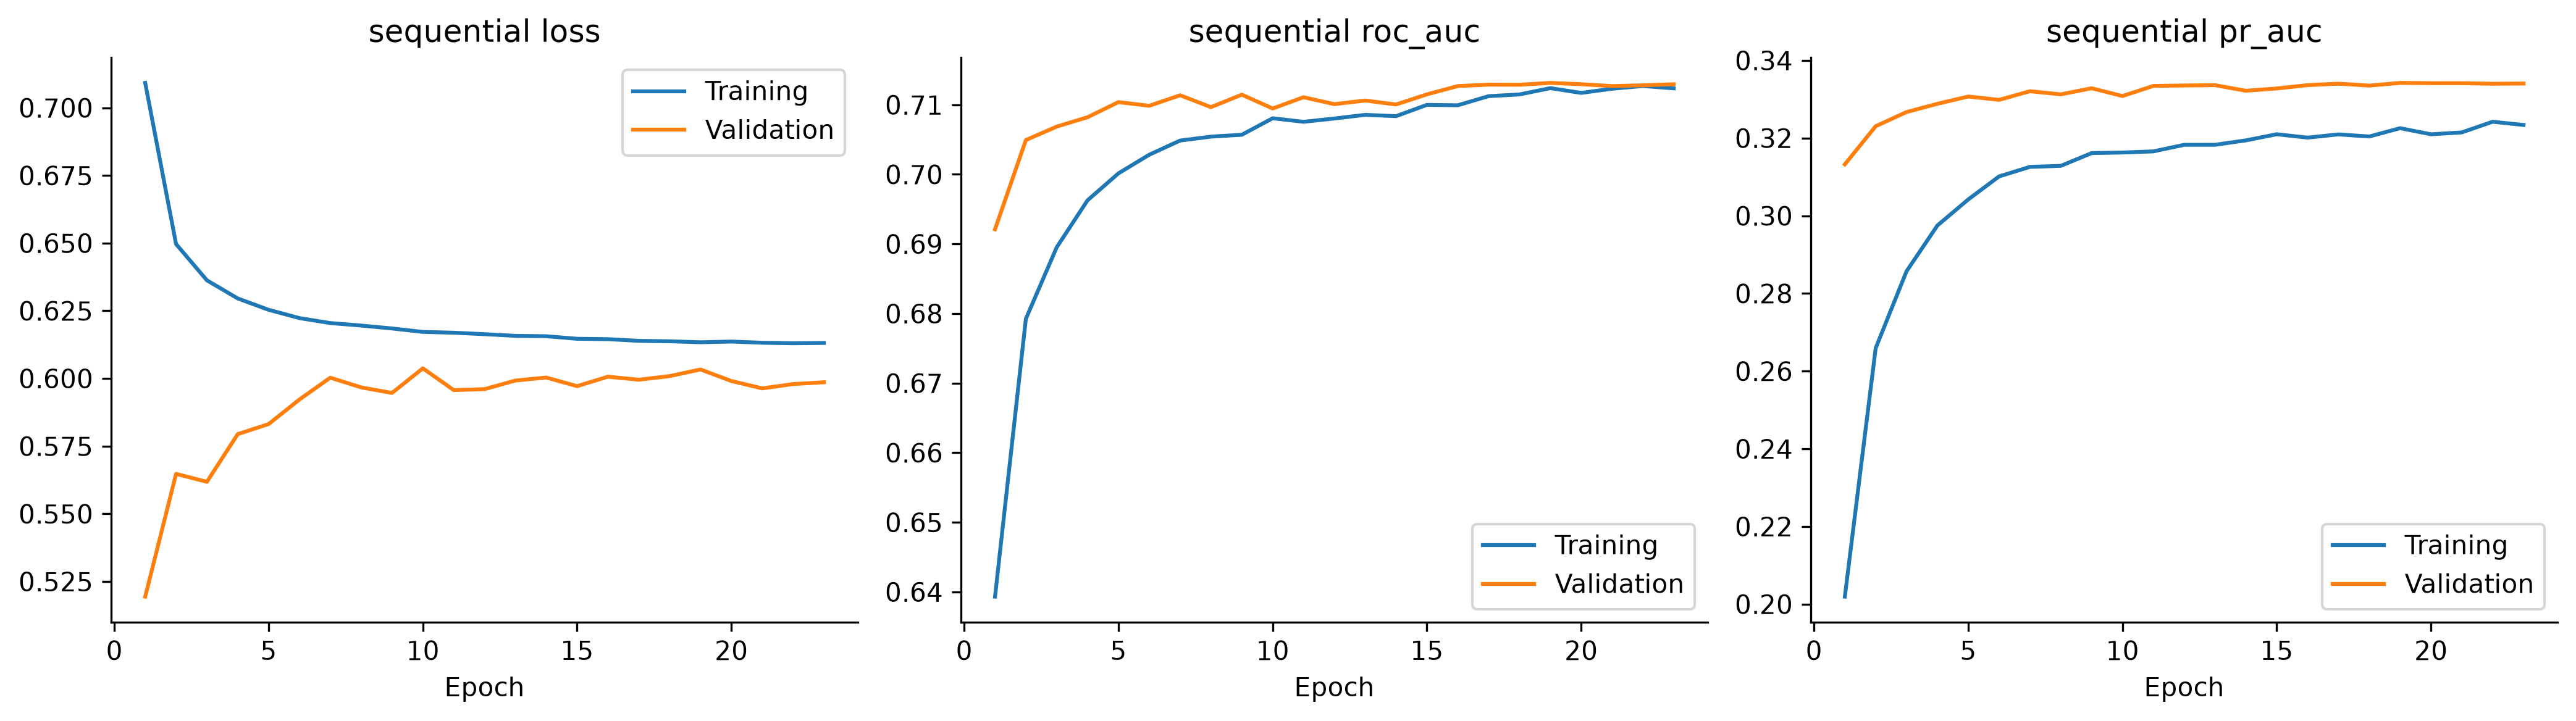

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,Deep sequential,dl_sequential,saved_completed_validation_predictions,96.704098,0.7132,0.334237,0.375087,0.347436,0.360732,0.352635,0.871933,0.640124,0.932813,0.924899,0.289949,0.201287,0.598377,0.096333,0.637516,37611,2709,3054,1626


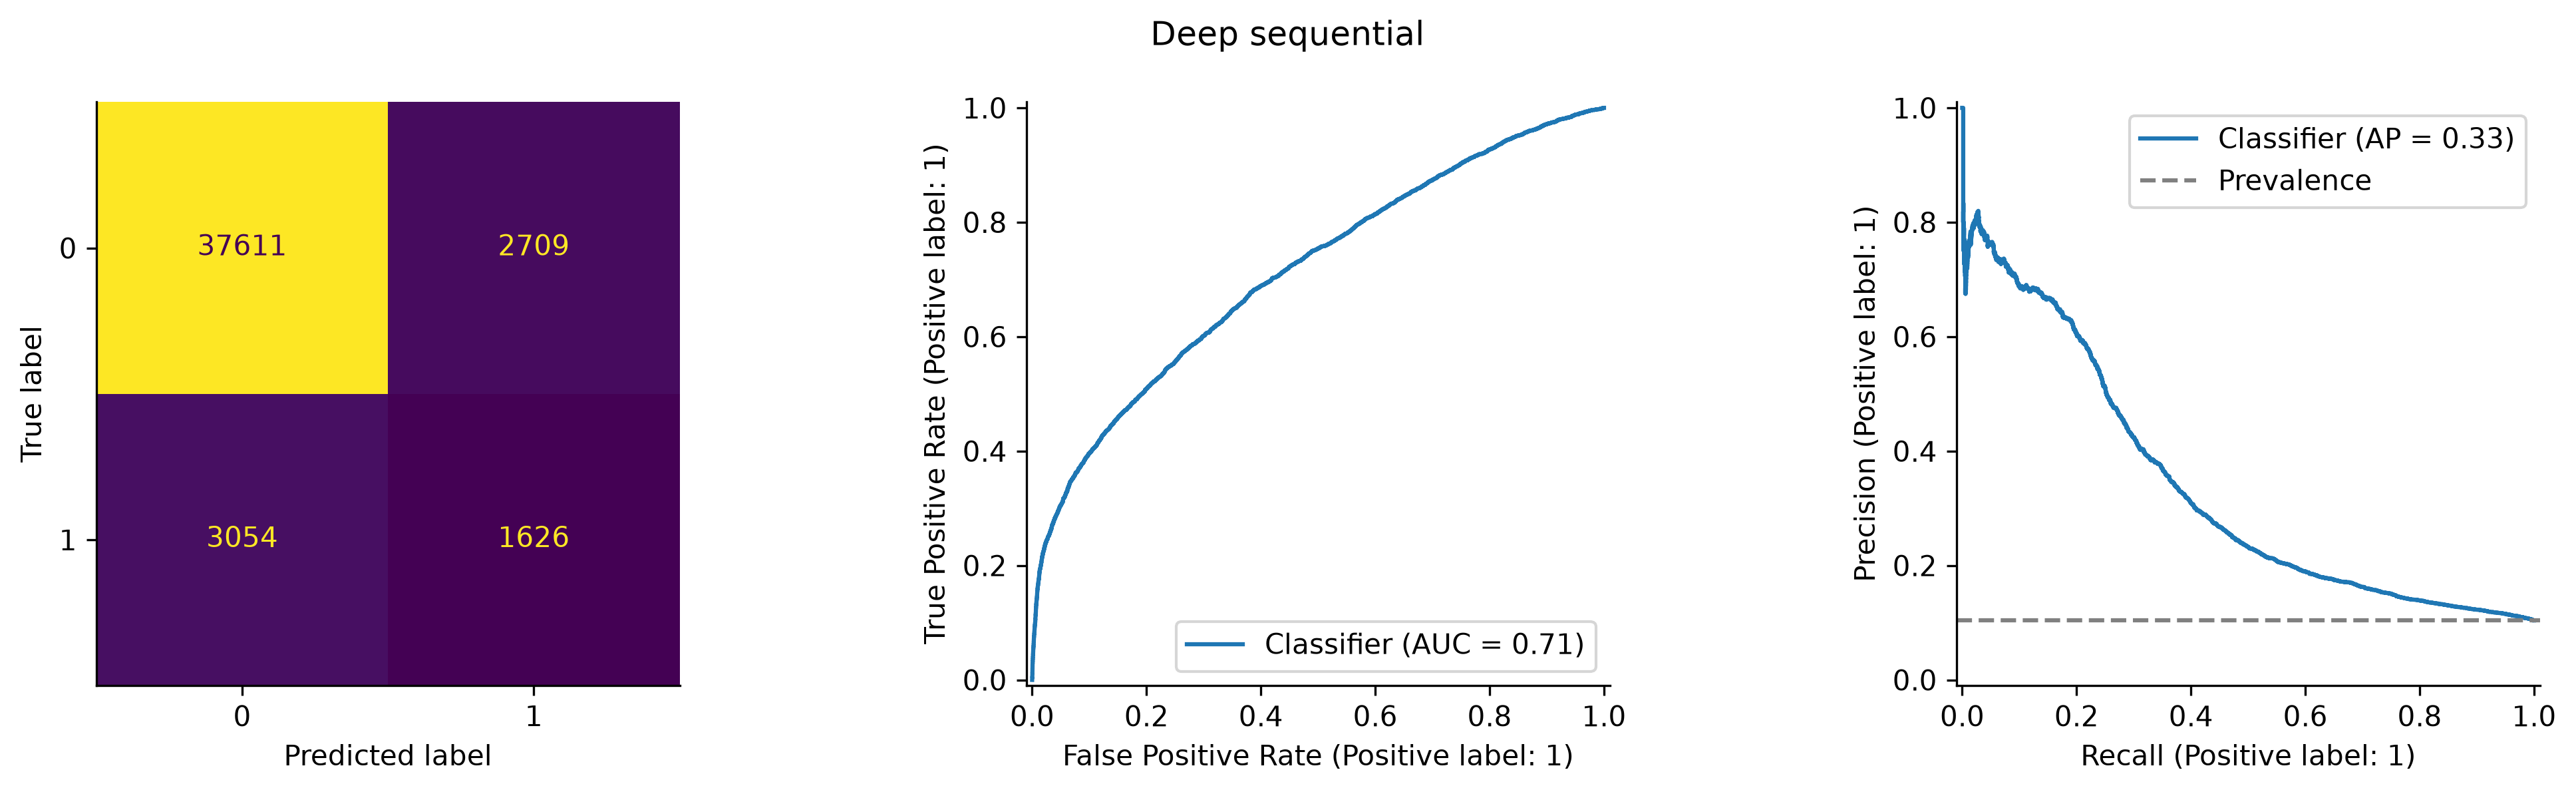

,loss,pr_auc,roc_auc,val_loss,val_pr_auc,val_roc_auc,learning_rate,epoch
18,0.612747,0.322078,0.709373,0.597161,0.338773,0.712952,0.000125,19
19,0.612157,0.322155,0.710261,0.596550,0.338589,0.712711,0.000125,20
20,0.611727,0.322944,0.711008,0.594763,0.338709,0.713009,0.000063,21
21,0.612161,0.322587,0.709996,0.595867,0.338693,0.713092,0.000063,22
22,0.611820,0.324195,0.710526,0.595620,0.338757,0.713082,0.000031,23


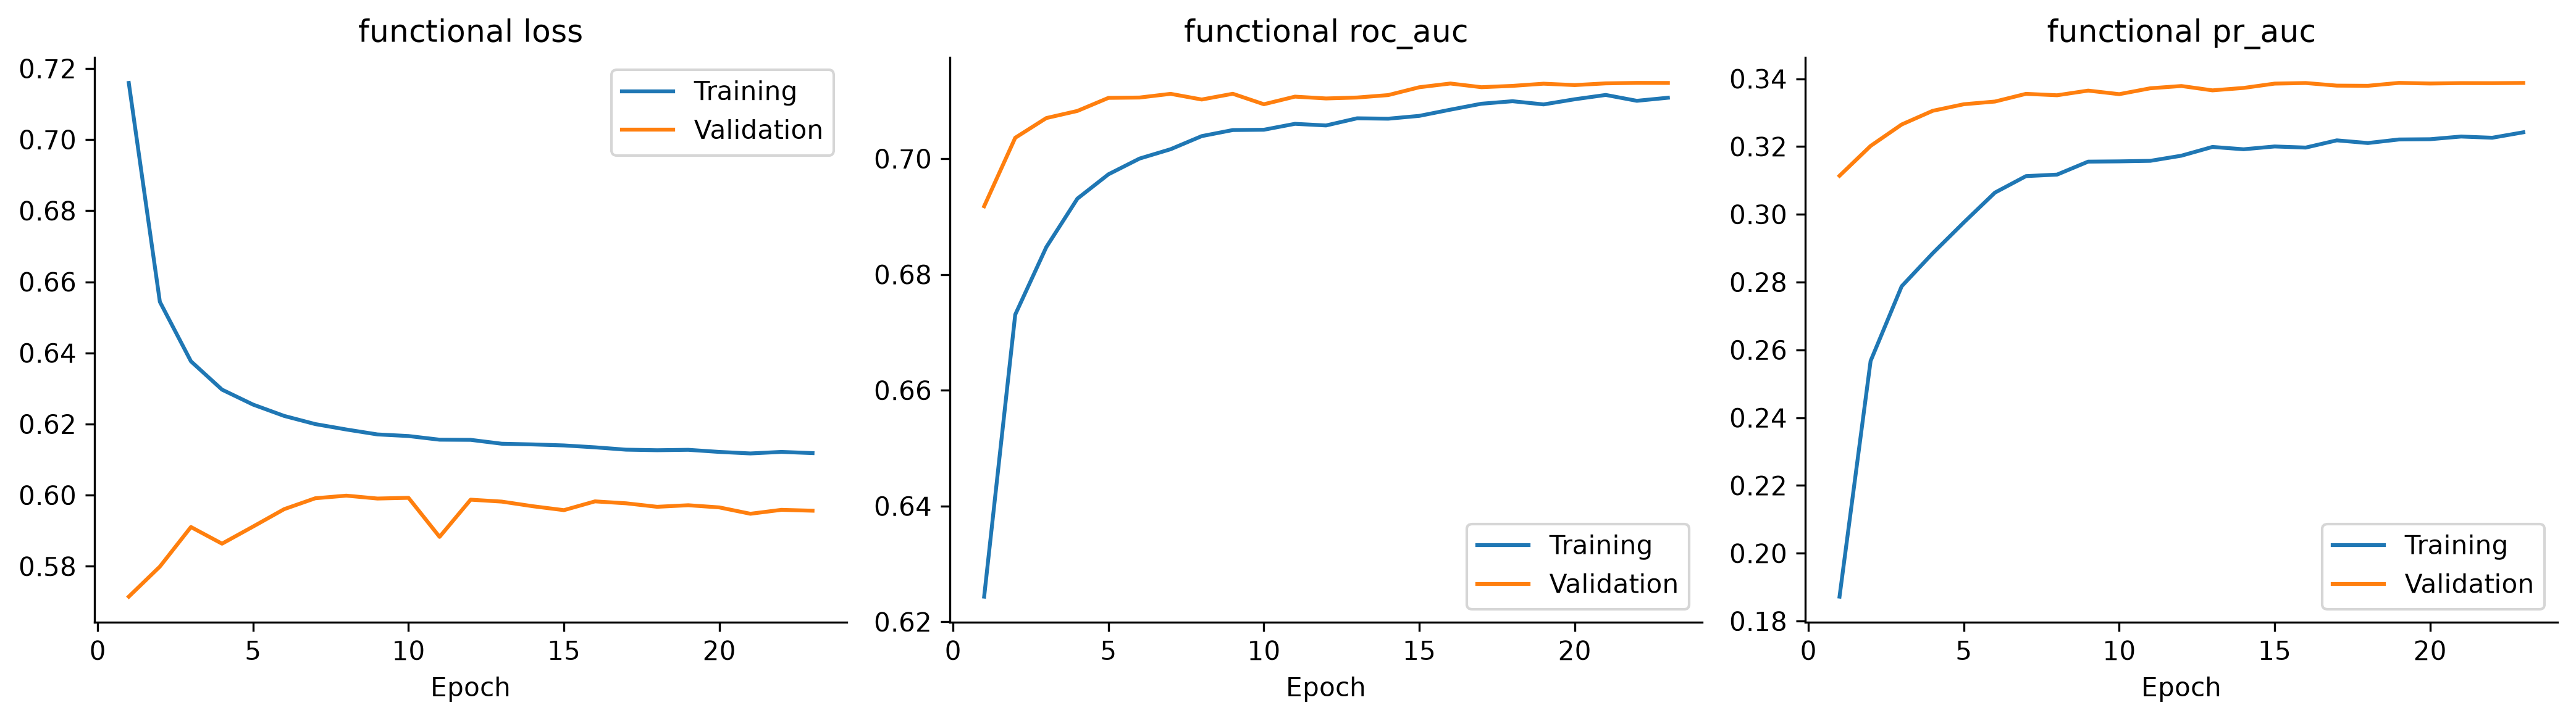

,model,cache_key,evidence,training_seconds,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,Deep functional,dl_functional,saved_completed_validation_predictions,182.520664,0.712922,0.338774,0.374048,0.346154,0.359561,0.351395,0.871756,0.639458,0.932763,0.924758,0.28869,0.199437,0.59449,0.096244,0.634973,37609,2711,3060,1620


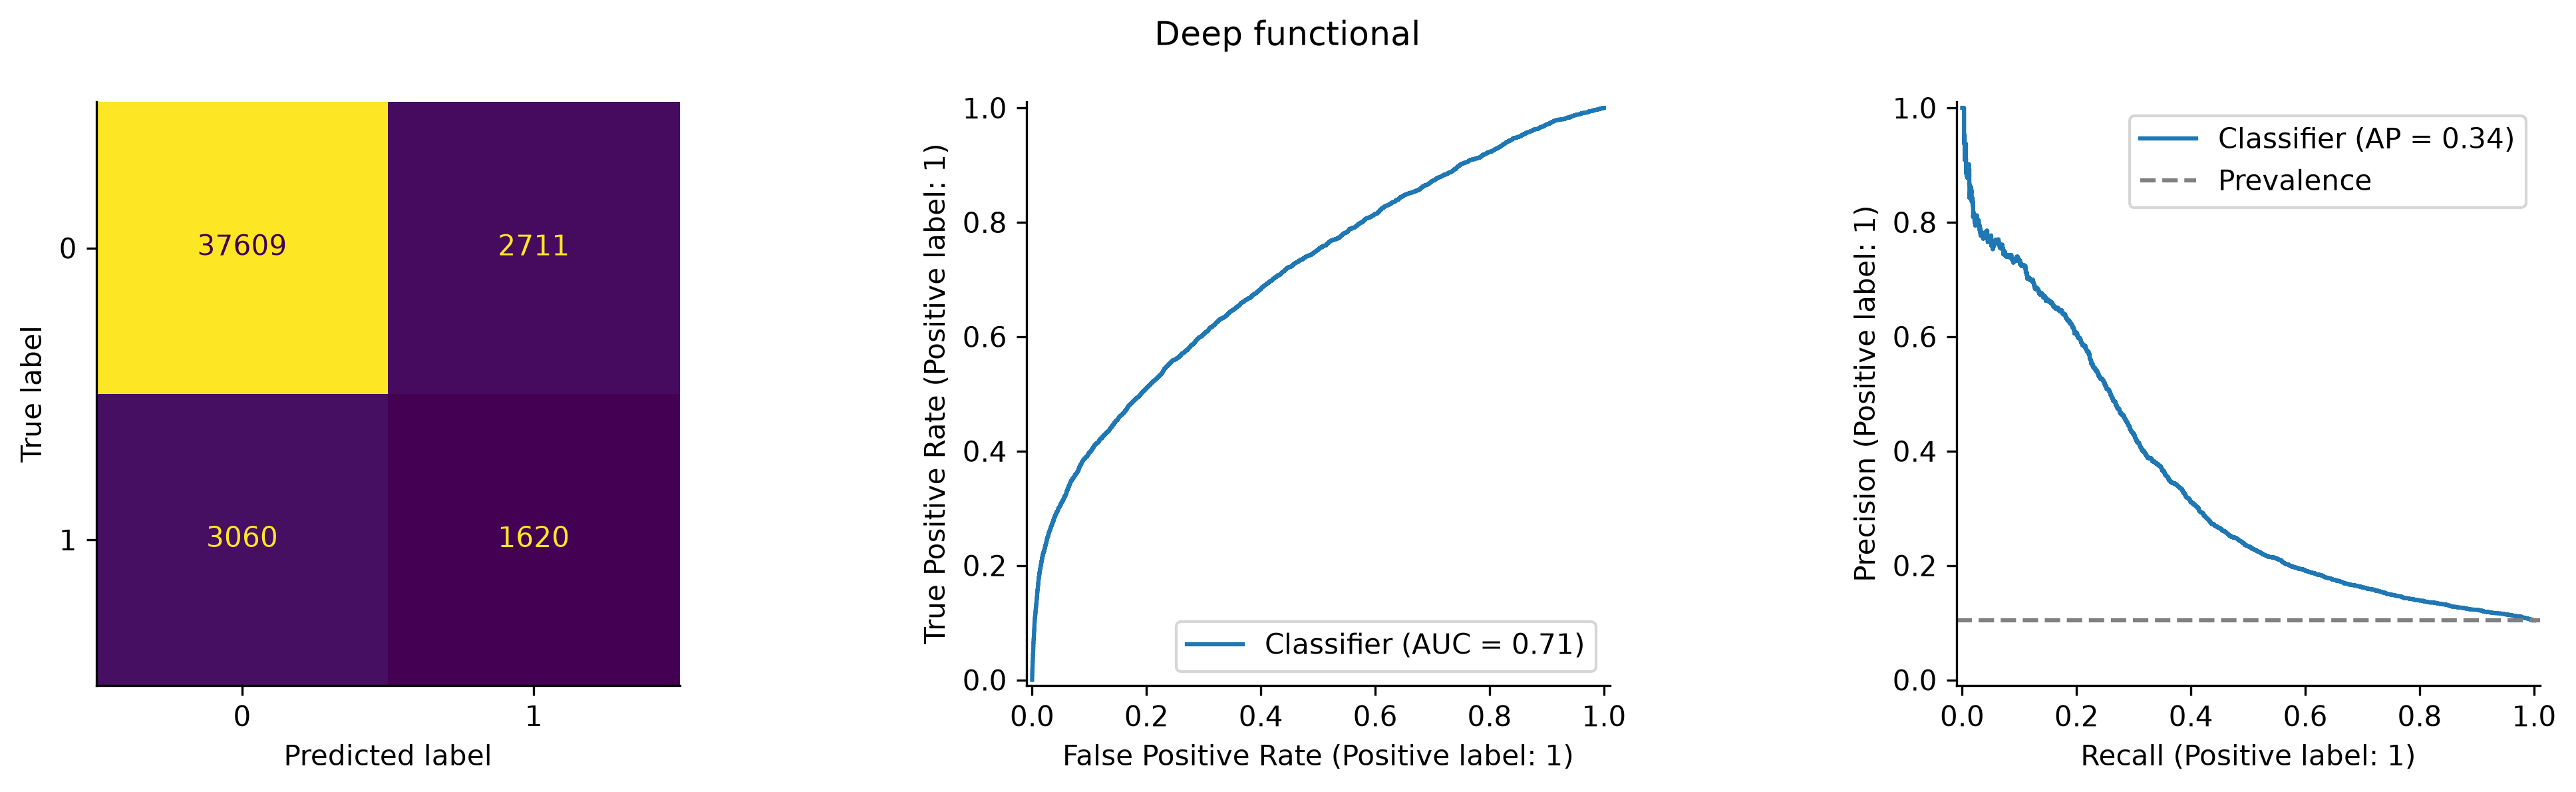

In [30]:
for api in ['sequential','functional']:
    history_path=EXPERIMENTS/f'best_{api}_history.csv' if RUN_TRAINING and RUN_DEEP_LEARNING else TABLES/f'stage6_history_{api}.csv'
    history=pd.read_csv(history_path)
    display(history.tail())
    fig,axes=plt.subplots(1,3,figsize=(14,4))
    for ax,metric in zip(axes,['loss','roc_auc','pr_auc']):
        ax.plot(np.arange(1,len(history)+1),history[metric],label='Training')
        ax.plot(np.arange(1,len(history)+1),history['val_'+metric],label='Validation')
        ax.set_xlabel('Epoch');ax.set_title(api+' '+metric);ax.legend()
    save_figure(api+'_learning_curves')
    if not (RUN_TRAINING and RUN_DEEP_LEARNING):
        run_log.recorded_history('dl_'+api,history,f'reports/tables/stage6_history_{api}.csv')
    if RUN_TRAINING and RUN_DEEP_LEARNING:
        model,_,inputs=neural_finalists[api]
        probabilities=model.predict(make_tf_dataset(inputs),verbose=0).ravel()
        threshold=best_f1_threshold(y_validation,probabilities)
        row=dict(model='Deep '+api,cache_key='dl_'+api,evidence='new_development_validation_only',training_seconds=neural_refit_seconds[api],
                 **score_binary(y_validation,probabilities,threshold))
        run_log.result('Deep '+api,row)
        run_log.evaluation('Deep '+api,y_validation,probabilities,threshold,source='new_development_validation_only',
                           params={'model':'Deep '+api,'paradigm':'deep_learning','evidence':'new_development_validation_only'})
        experiment_rows.append(row);development_predictions['Deep '+api]=probabilities
        display(pd.DataFrame([row]));plot_binary(y_validation,probabilities,threshold,'Deep '+api)
    else:
        log_experiment('Deep '+api,cached_name='dl_'+api,deep=True)

**Interpretation.** Both networks selected the same configuration: one hidden layer of 96 units, dropout 0.3, RMSprop, learning rate 0.0005. Their validation PR-AUC peaks around epoch 19, and early stopping restores those weights. The training and validation curves stay close, so the networks are not overfitting; like the tree models, they plateau near AUC 0.71. The training loss is higher than the validation loss only because it is class-weighted (preterm births count 4.8×), so the two losses are not directly comparable; the AUC curves are the fair comparison. Class weighting also inflates the predicted probabilities, which is why both networks have a Brier score of about 0.20 against 0.08 for the tree models. Their scores rank births well but are not calibrated risks.

## Main model comparison

All eight entries side by side on the same 45,000 validation records: majority baseline, plain and tuned logistic regression, Random Forest, HistGradientBoosting, calibrated SVM, and the Sequential and Functional networks. The same table is browsable in TensorBoard's HParams tab.

In [31]:
current_comparison=pd.DataFrame(experiment_rows)
columns=['model','evidence','roc_auc','average_precision','precision','recall','f1','f2','specificity','brier','threshold','training_seconds']
display(current_comparison[[c for c in columns if c in current_comparison]])
current_comparison.to_csv(RESULT_TABLES/'model_validation_comparison.csv',index=False)

,model,evidence,roc_auc,average_precision,precision,recall,f1,f2,specificity,brier,threshold,training_seconds
0,Majority class,saved_completed_validation_predictions,0.500000,0.104000,0.000000,0.000000,0.000000,0.000000,1.000000,0.104000,0.500000,1.811282
1,Plain logistic regression,saved_completed_validation_predictions,0.708295,0.335889,0.391513,0.331197,0.358838,0.341726,0.940253,0.081307,0.167787,5.815629
2,Tuned logistic regression,saved_completed_validation_predictions,0.708295,0.335889,0.391513,0.331197,0.358838,0.341726,0.940253,0.081307,0.167787,20.122348
3,Random Forest,saved_completed_validation_predictions,0.710725,0.335309,0.394320,0.335256,0.362398,0.345610,0.940228,0.081361,0.176575,95.349028
4,HistGradientBoosting,saved_completed_validation_predictions,0.712484,0.341159,0.418177,0.315598,0.359717,0.331880,0.949033,0.081128,0.200678,24.496821
5,Calibrated SVM,saved_completed_validation_predictions,0.644714,0.285950,0.409148,0.279060,0.331809,0.298010,0.953224,0.084969,0.120920,11.267252
6,Deep sequential,saved_completed_validation_predictions,0.713200,0.334237,0.375087,0.347436,0.360732,0.352635,0.932813,0.201287,0.637516,96.704098
7,Deep functional,saved_completed_validation_predictions,0.712922,0.338774,0.374048,0.346154,0.359561,0.351395,0.932763,0.199437,0.634973,182.520664


**Interpretation.** Average precision decides selection because it measures how well a model ranks preterm births above term births without fixing a threshold. HistGradientBoosting (AP ≈0.341) and the Functional network (AP ≈0.339) are the two finalists, one per paradigm. The spread among the six learned models (excluding the SVM) is under 0.01 AP, so the deep networks did not beat gradient boosting on this tabular data, matching what is commonly reported for structured clinical records. HistGradientBoosting also has the best probability quality (lowest Brier score).

## Screening thresholds — detection versus false alerts

A threshold turns a score into an alert. For screening, missing a preterm birth is usually worse than an extra assessment, so beyond the F1 threshold I compare the validation-F2 threshold (recall weighted 4× precision) and the highest thresholds that reach 70% and 80% recall. For each policy I report missed births, false alerts and alerts per 1,000 births. These policies are chosen on validation data only and were never applied to the test set.

,model,policy,threshold,precision,recall,f2,specificity,negative_predictive_value,detected_preterm,missed_preterm,false_alerts,true_negatives,alert_fraction,alerts_per_1000,missed_preterm_per_1000,false_alerts_per_1000,scope
0,Plain logistic regression,Recorded validation-F1 threshold,0.167787,0.391513,0.331197,0.341726,0.940253,0.923735,1550,3130,2409,37911,0.087978,87.977778,69.555556,53.533333,post-hoc development validation; not independe...
1,Plain logistic regression,Exploratory maximum validation F2,0.078970,0.161457,0.686538,0.415976,0.586136,0.941554,3213,1467,16687,23633,0.442222,442.222222,32.600000,370.822222,post-hoc development validation; not independe...
2,Plain logistic regression,Exploratory recall at least 70%,0.077623,0.157432,0.700000,0.414379,0.565154,0.941962,3276,1404,17533,22787,0.462422,462.422222,31.200000,389.622222,post-hoc development validation; not independe...
3,Plain logistic regression,Exploratory recall at least 80%,0.068943,0.138924,0.800000,0.409897,0.424454,0.948144,3744,936,23206,17114,0.598889,598.888889,20.800000,515.688889,post-hoc development validation; not independe...
4,Tuned logistic regression,Recorded validation-F1 threshold,0.167787,0.391513,0.331197,0.341726,0.940253,0.923735,1550,3130,2409,37911,0.087978,87.977778,69.555556,53.533333,post-hoc development validation; not independe...
5,Tuned logistic regression,Exploratory maximum validation F2,0.078970,0.161457,0.686538,0.415976,0.586136,0.941554,3213,1467,16687,23633,0.442222,442.222222,32.600000,370.822222,post-hoc development validation; not independe...
6,Tuned logistic regression,Exploratory recall at least 70%,0.077623,0.157432,0.700000,0.414379,0.565154,0.941962,3276,1404,17533,22787,0.462422,462.422222,31.200000,389.622222,post-hoc development validation; not independe...
7,Tuned logistic regression,Exploratory recall at least 80%,0.068943,0.138924,0.800000,0.409897,0.424454,0.948144,3744,936,23206,17114,0.598889,598.888889,20.800000,515.688889,post-hoc development validation; not independe...
8,Random Forest,Recorded validation-F1 threshold,0.176575,0.394320,0.335256,0.345610,0.940228,0.924161,1569,3111,2410,37910,0.088422,88.422222,69.133333,53.555556,post-hoc development validation; not independe...
9,Random Forest,Exploratory maximum validation F2,0.086350,0.184638,0.616880,0.420160,0.683805,0.938939,2887,1793,12749,27571,0.347467,347.466667,39.844444,283.311111,post-hoc development validation; not independe...


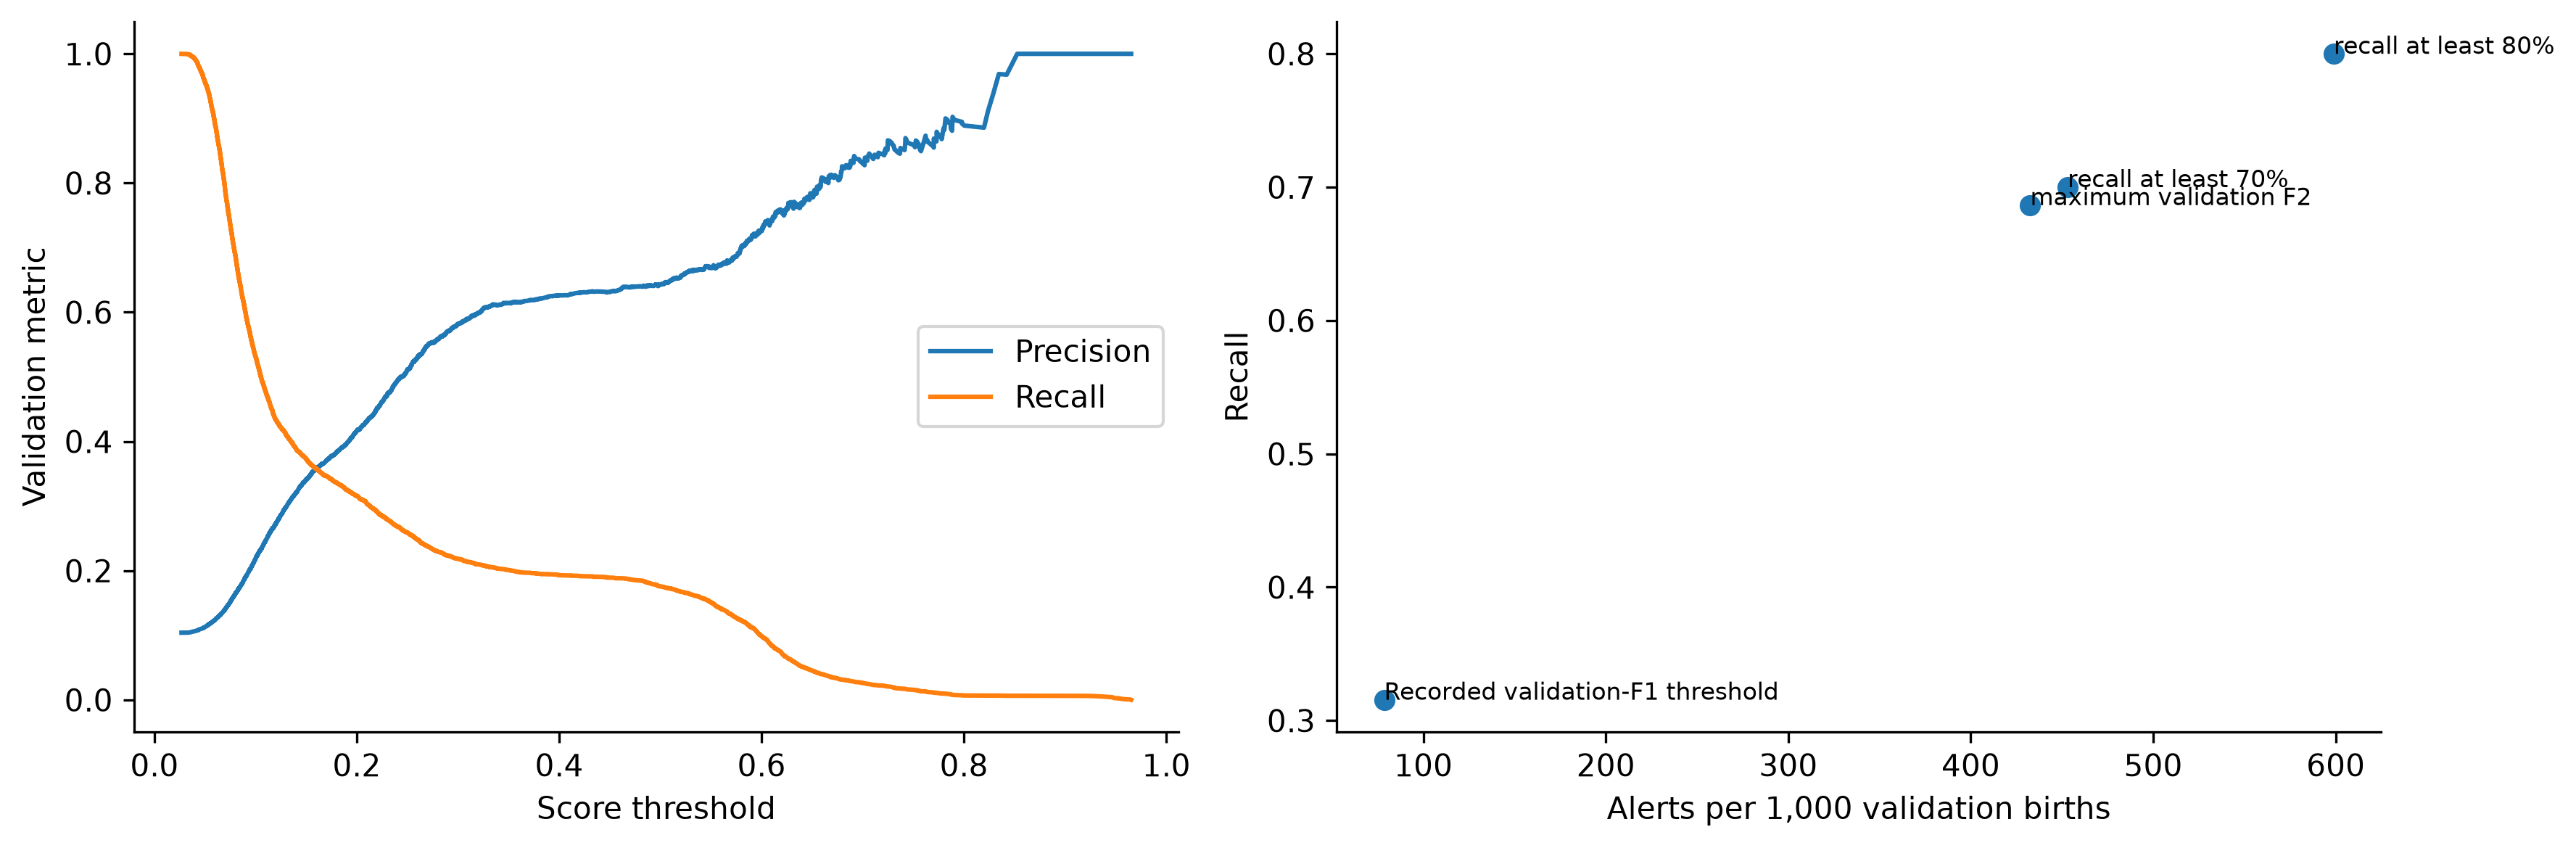

Illustrative HGB validation-F2 operating point — requires independent validation:


,value
model,HistGradientBoosting
policy,Exploratory maximum validation F2
threshold,0.080212
precision,0.165049
recall,0.686538
f2,0.420693
specificity,0.596875
negative_predictive_value,0.942545
detected_preterm,3213
missed_preterm,1467


F2 weights recall more heavily; these are research operating points, not approved clinical cutoffs.
The binary label does not identify every pregnancy complication or establish an intermediate at-risk diagnosis.


In [32]:
threshold_rows=[]
for record in experiment_rows:
    name=record['model']
    if name=='Majority class':continue
    p=development_predictions[name]
    policies=operating_points(y_validation,p,record['threshold'],RECALL_TARGETS)
    # Both saved and new runs use the validation-F1 rule; label which run the threshold came from.
    if record['evidence']=='new_development_validation_only':
        policies.loc[0,'policy']='Current-run validation-F1 threshold'
    policies.insert(0,'model',name)
    policies['scope']='post-hoc development validation; not independent evaluation'
    threshold_rows.append(policies)
threshold_comparison=pd.concat(threshold_rows,ignore_index=True)
display(threshold_comparison)
threshold_comparison.to_csv(RESULT_TABLES/'validation_threshold_tradeoffs.csv',index=False)
# HGB was the recorded classical finalist. Do not pick a new model using test results.
hgb_name='HistGradientBoosting'
hgb_p=development_predictions[hgb_name]
precision,recall,thresholds=precision_recall_curve(y_validation,hgb_p)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(thresholds,precision[:-1],label='Precision')
axes[0].plot(thresholds,recall[:-1],label='Recall')
axes[0].set(xlabel='Score threshold',ylabel='Validation metric');axes[0].legend()
tradeoff=threshold_comparison.loc[threshold_comparison.model.eq(hgb_name)]
axes[1].scatter(tradeoff.alerts_per_1000,tradeoff.recall)
for row in tradeoff.itertuples():axes[1].annotate(row.policy.replace('Exploratory ','')[:34],
    (row.alerts_per_1000,row.recall),fontsize=8)
axes[1].set(xlabel='Alerts per 1,000 validation births',ylabel='Recall')
save_figure('validation_threshold_tradeoffs')
research_choice=tradeoff.loc[tradeoff.policy.eq('Exploratory maximum validation F2')].iloc[0]
print('Illustrative HGB validation-F2 operating point — requires independent validation:')
display(research_choice.to_frame('value'))
print('F2 weights recall more heavily; these are research operating points, not approved clinical cutoffs.')
print('The binary label does not identify every pregnancy complication or establish an intermediate at-risk diagnosis.')

**Interpretation.** For HistGradientBoosting, moving from the F1 threshold (≈0.20) to the F2 threshold (≈0.08) more than doubles recall (0.32 → 0.69), but alerts rise from about 78 to 433 per 1,000 births, and precision falls from 0.42 to 0.17. Reaching 80% recall would flag about 60% of all pregnancies. A threshold only moves along the same ROC curve; it cannot add information. The right cutoff depends on what follow-up is offered and how many assessments a service can afford, so I treat these points as illustrations rather than clinical recommendations.

## Top predictive inputs

Permutation importance for the selected HistGradientBoosting model: the drop in validation AP when one input is shuffled.

In [33]:
from readable_features import readable_feature_label
importance=pd.read_csv(TABLES/'stage7_permutation_importance.csv')
importance['feature']=importance.feature.map(readable_feature_label)
display(importance.head(10))

,feature,importance,std
0,pregnancy_plurality,0.132069,0.011412
1,previous_preterm_birth_indicator,0.033038,0.005723
2,previous_births_now_living,0.012842,0.001861
3,prepregnancy_hypertension,0.009879,0.001142
4,maternal_age_years,0.009249,0.001766
5,maternal_race_ethnicity,0.008233,0.001779
6,maternal_height_inches,0.007546,0.002588
7,prepregnancy_body_mass_index,0.006345,0.002942
8,paternal_age_years,0.006002,0.002416
9,previous_cesarean_count,0.005366,0.001013


**Interpretation.** Plurality dominates (AP drop ≈0.13), followed by a previous preterm birth (≈0.03), number of previous live births, chronic hypertension and maternal age. These match established clinical risk factors. They describe predictive association, not cause; race/ethnicity in particular reflects social and structural factors, not biology.

## Subgroup detection

Recall, precision and AUC by age band, race/ethnicity, delivery payment source and plurality at each finalist's frozen validation threshold. Groups whose recall differs from the overall value by more than 0.10 are flagged.

In [34]:
subgroups=pd.read_csv(TABLES/'stage7_subgroups.csv')
display(subgroups[['model','variable','group','rows','positive_rows','precision','recall','roc_auc','disparity_flag']])

,model,variable,group,rows,positive_rows,precision,recall,roc_auc,disparity_flag
0,hist_gradient_boosting,age_band,"(-inf, 19.0]",1684,185,0.520000,0.140541,0.594403,True
1,hist_gradient_boosting,age_band,"(19.0, 24.0]",7473,731,0.464103,0.247606,0.665687,False
2,hist_gradient_boosting,age_band,"(24.0, 29.0]",12279,1203,0.431015,0.314214,0.706638,False
3,hist_gradient_boosting,age_band,"(29.0, 34.0]",13880,1391,0.414069,0.334292,0.731254,False
4,hist_gradient_boosting,age_band,"(34.0, 39.0]",7743,912,0.400474,0.370614,0.736778,False
5,hist_gradient_boosting,age_band,"(39.0, inf]",1941,258,0.358871,0.344961,0.682975,False
6,hist_gradient_boosting,race_ethnicity,-1.0,445,49,0.351852,0.387755,0.745156,False
7,hist_gradient_boosting,race_ethnicity,1.0,22077,2080,0.417462,0.294231,0.715017,False
8,hist_gradient_boosting,race_ethnicity,2.0,5786,863,0.431960,0.400927,0.721992,False
9,hist_gradient_boosting,race_ethnicity,3.0,314,38,0.313725,0.421053,0.720728,True


## Error analysis — who is detected and who is missed

The overall metrics hide where the errors are. I recompute performance for singleton vs multiple pregnancies and for women with and without a previous birth, and I profile detected cases (TP), missed cases (FN) and false alerts (FP). Singleton results are also written to TensorBoard (`sklearn_metrics/singletons`).

,model,variable,group,births,preterm,preterm_rate,roc_auc,average_precision,recall,precision,alert_fraction,tp,fn,fp
0,HistGradientBoosting,plurality,multiple,1400,882,0.630,0.627,0.744,1.000,0.630,1.000,882,0,518
1,HistGradientBoosting,plurality,singleton,43600,3798,0.087,0.655,0.180,0.157,0.279,0.049,595,3203,1537
2,HistGradientBoosting,parity,no previous birth,17771,1748,0.098,0.653,0.247,0.152,0.477,0.031,266,1482,292
3,HistGradientBoosting,parity,parity unknown,190,30,0.158,0.754,0.462,0.467,0.452,0.163,14,16,17
4,HistGradientBoosting,parity,previous birth,27039,2902,0.107,0.744,0.392,0.412,0.407,0.109,1197,1705,1746
5,Deep functional,plurality,multiple,1400,882,0.630,0.618,0.735,0.993,0.628,0.996,876,6,518
6,Deep functional,plurality,singleton,43600,3798,0.087,0.656,0.179,0.196,0.253,0.067,744,3054,2193
7,Deep functional,parity,no previous birth,17771,1748,0.098,0.655,0.252,0.197,0.355,0.055,345,1403,628
8,Deep functional,parity,parity unknown,190,30,0.158,0.767,0.454,0.433,0.542,0.126,13,17,11
9,Deep functional,parity,previous birth,27039,2902,0.107,0.744,0.386,0.435,0.379,0.123,1262,1640,2072


,model,outcome,births,share_multiple,share_previous_preterm,share_no_previous_birth,mean_maternal_age
0,HistGradientBoosting,detected preterm (TP),1477,0.597,0.347,0.180,31.035
1,HistGradientBoosting,missed preterm (FN),3203,0.000,0.009,0.463,29.674
2,HistGradientBoosting,false alert (FP),2055,0.252,0.530,0.142,31.636
3,Deep functional,detected preterm (TP),1620,0.541,0.327,0.213,31.200
4,Deep functional,missed preterm (FN),3060,0.002,0.003,0.458,29.523
5,Deep functional,false alert (FP),2711,0.191,0.436,0.232,31.911


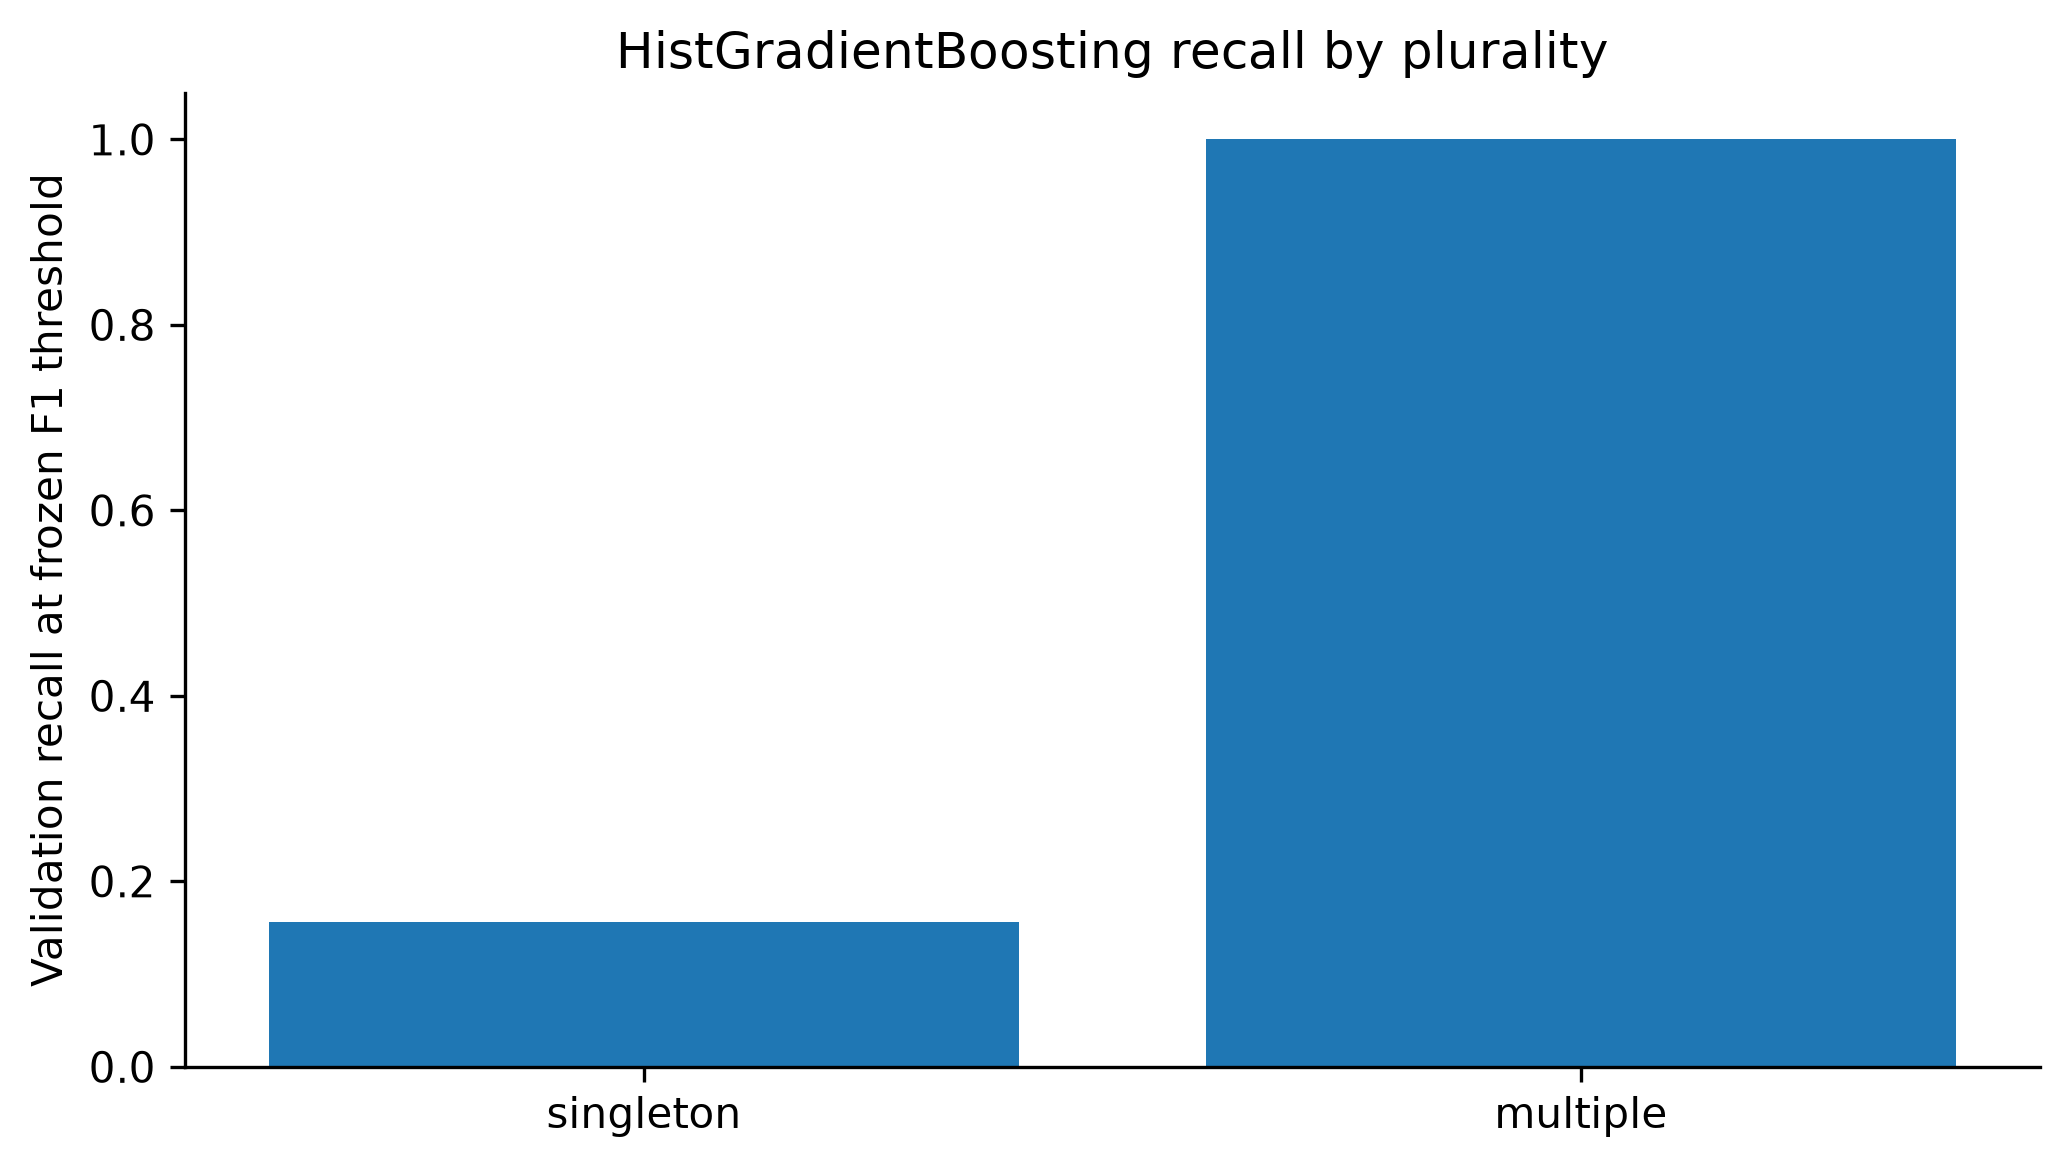

In [35]:
# Error analysis on validation predictions: where do the two finalists succeed and fail?
finalists={'HistGradientBoosting':'hist_gradient_boosting','Deep functional':'dl_functional'}
y_val=y_validation.to_numpy()
plurality=np.where(validation.DPLURAL.eq(1),'singleton','multiple').astype(object)
parity=np.where(validation.PRIORLIVE.isna()|validation.PRIORDEAD.isna(),'parity unknown',
         np.where(validation.PRIORLIVE.eq(0)&validation.PRIORDEAD.eq(0),'no previous birth','previous birth')).astype(object)
error_rows,profile_rows=[],[]
for label in finalists:
    record=next(r for r in experiment_rows if r['model']==label)
    p,threshold=development_predictions[label],record['threshold']
    alert=p>=threshold
    for variable,groups in [('plurality',plurality),('parity',parity)]:
        for group in sorted(set(groups)):
            mask=groups==group
            if len(np.unique(y_val[mask]))<2:continue
            scores=score_binary(y_val[mask],p[mask],threshold)
            error_rows.append(dict(model=label,variable=variable,group=group,births=int(mask.sum()),
                preterm=int(y_val[mask].sum()),preterm_rate=y_val[mask].mean(),**{k:scores[k] for k in
                ['roc_auc','average_precision','recall','precision','alert_fraction','tp','fn','fp']}))
    singleton=plurality=='singleton'
    run_log.evaluation(label+' singletons',y_val[singleton],p[singleton],threshold,source=record['evidence'],group='singletons')
    for outcome,mask in [('detected preterm (TP)',(y_val==1)&alert),('missed preterm (FN)',(y_val==1)&~alert),('false alert (FP)',(y_val==0)&alert)]:
        rows=validation.loc[mask]
        profile_rows.append(dict(model=label,outcome=outcome,births=int(mask.sum()),
            share_multiple=float((plurality[mask]=='multiple').mean()),
            share_previous_preterm=float(rows.RF_PPTERM.eq('Y').mean()),
            share_no_previous_birth=float((parity[mask]=='no previous birth').mean()),
            mean_maternal_age=float(rows.MAGER.mean())))
error_table=pd.DataFrame(error_rows);error_profile=pd.DataFrame(profile_rows)
display(error_table.round(3));display(error_profile.round(3))
error_table.to_csv(RESULT_TABLES/'error_analysis_subgroups.csv',index=False)
error_profile.to_csv(RESULT_TABLES/'error_analysis_profiles.csv',index=False)
hgb_errors=error_table.loc[error_table.model.eq('HistGradientBoosting')&error_table.variable.eq('plurality')].set_index('group')
plt.figure(figsize=(7,4))
plt.bar(['singleton','multiple'],hgb_errors.loc[['singleton','multiple'],'recall'])
plt.ylabel('Validation recall at frozen F1 threshold');plt.title('HistGradientBoosting recall by plurality')
save_figure('error_analysis_recall_by_plurality')

**Interpretation.** This is the most important finding of my error analysis. Multiple pregnancies are only about 3% of births, but 63% of them are preterm and the finalists flag almost all of them (recall ≈1.0). In my completed run they make up roughly 60% of HistGradientBoosting's correct detections. For singletons, about 97% of births, recall falls to about 0.16 (HistGradientBoosting) and 0.20 (Functional network), with AUC ≈0.66. Almost every missed preterm birth is a singleton without a recorded previous preterm birth. Women with no previous birth have no obstetric history for the model to use, and their recall is also low (≈0.15–0.20). The headline AUC of 0.71 therefore overstates how well the model separates ordinary singleton pregnancies. Improving them needs information these records do not contain, such as cervical length, biomarkers or a symptom history.

## Frozen final test

My completed study evaluated the two finalists once on 45,000 held-out test births, using the thresholds frozen on validation. Here I recompute every test metric from those saved test predictions, check them against the recorded table, and write them to TensorBoard (`sklearn_metrics/test`). I do not retrain, re-select or re-threshold anything on the test set.

,model,split,rows,roc_auc,average_precision,precision,recall,f1,accuracy,brier,threshold,auc_ci_lower,auc_ci_upper,bootstrap_reps
0,hist_gradient_boosting,test,45000,0.706275,0.331385,0.409983,0.303632,0.348883,0.882133,0.081585,0.200678,0.698363,0.714657,500
1,dl_functional,test,45000,0.707848,0.332176,0.368843,0.334402,0.350779,0.871267,0.199597,0.634973,0.699443,0.716155,500


,model,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,hist_gradient_boosting,0.706275,0.331385,0.409983,0.303632,0.348883,0.320247,0.882133,0.626457,0.949281,0.921534,0.28956,0.081585,0.293989,0.077022,0.200678,38275,2045,3259,1421


,precision,recall,f1-score,support
0,0.921534,0.949281,0.935202,40320.000000
1,0.409983,0.303632,0.348883,4680.000000
accuracy,0.882133,0.882133,0.882133,0.882133
macro avg,0.665758,0.626457,0.642042,45000.000000
weighted avg,0.868333,0.882133,0.874225,45000.000000


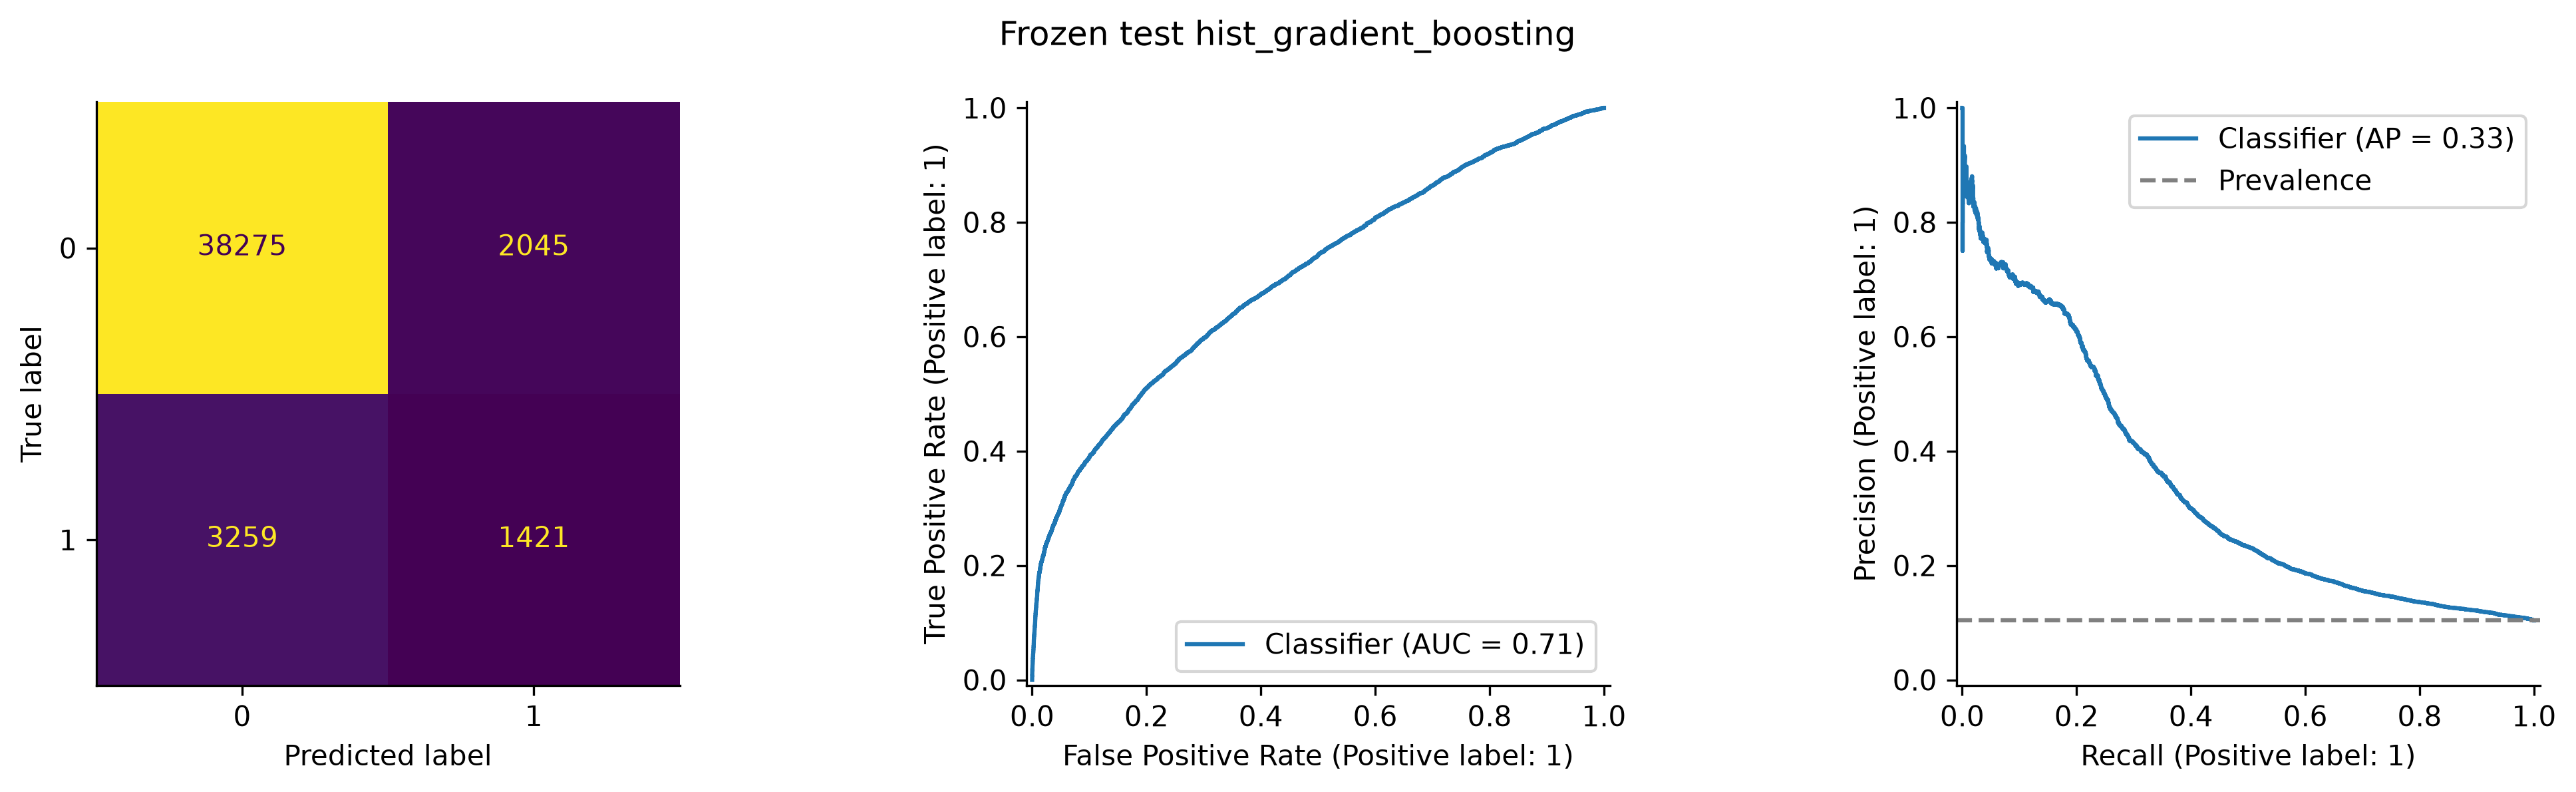

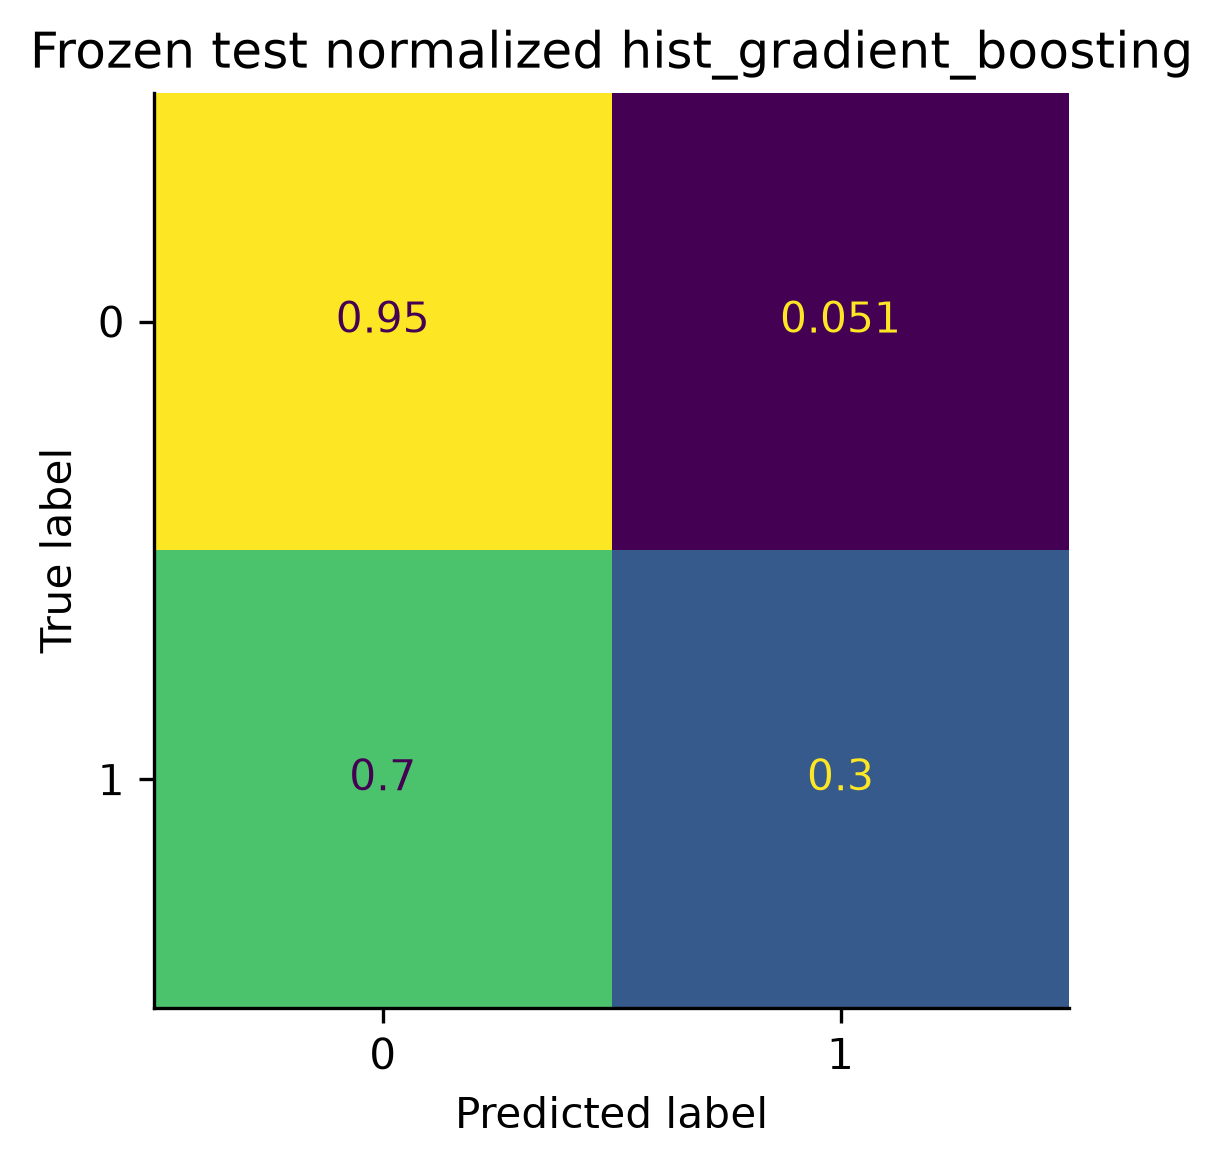

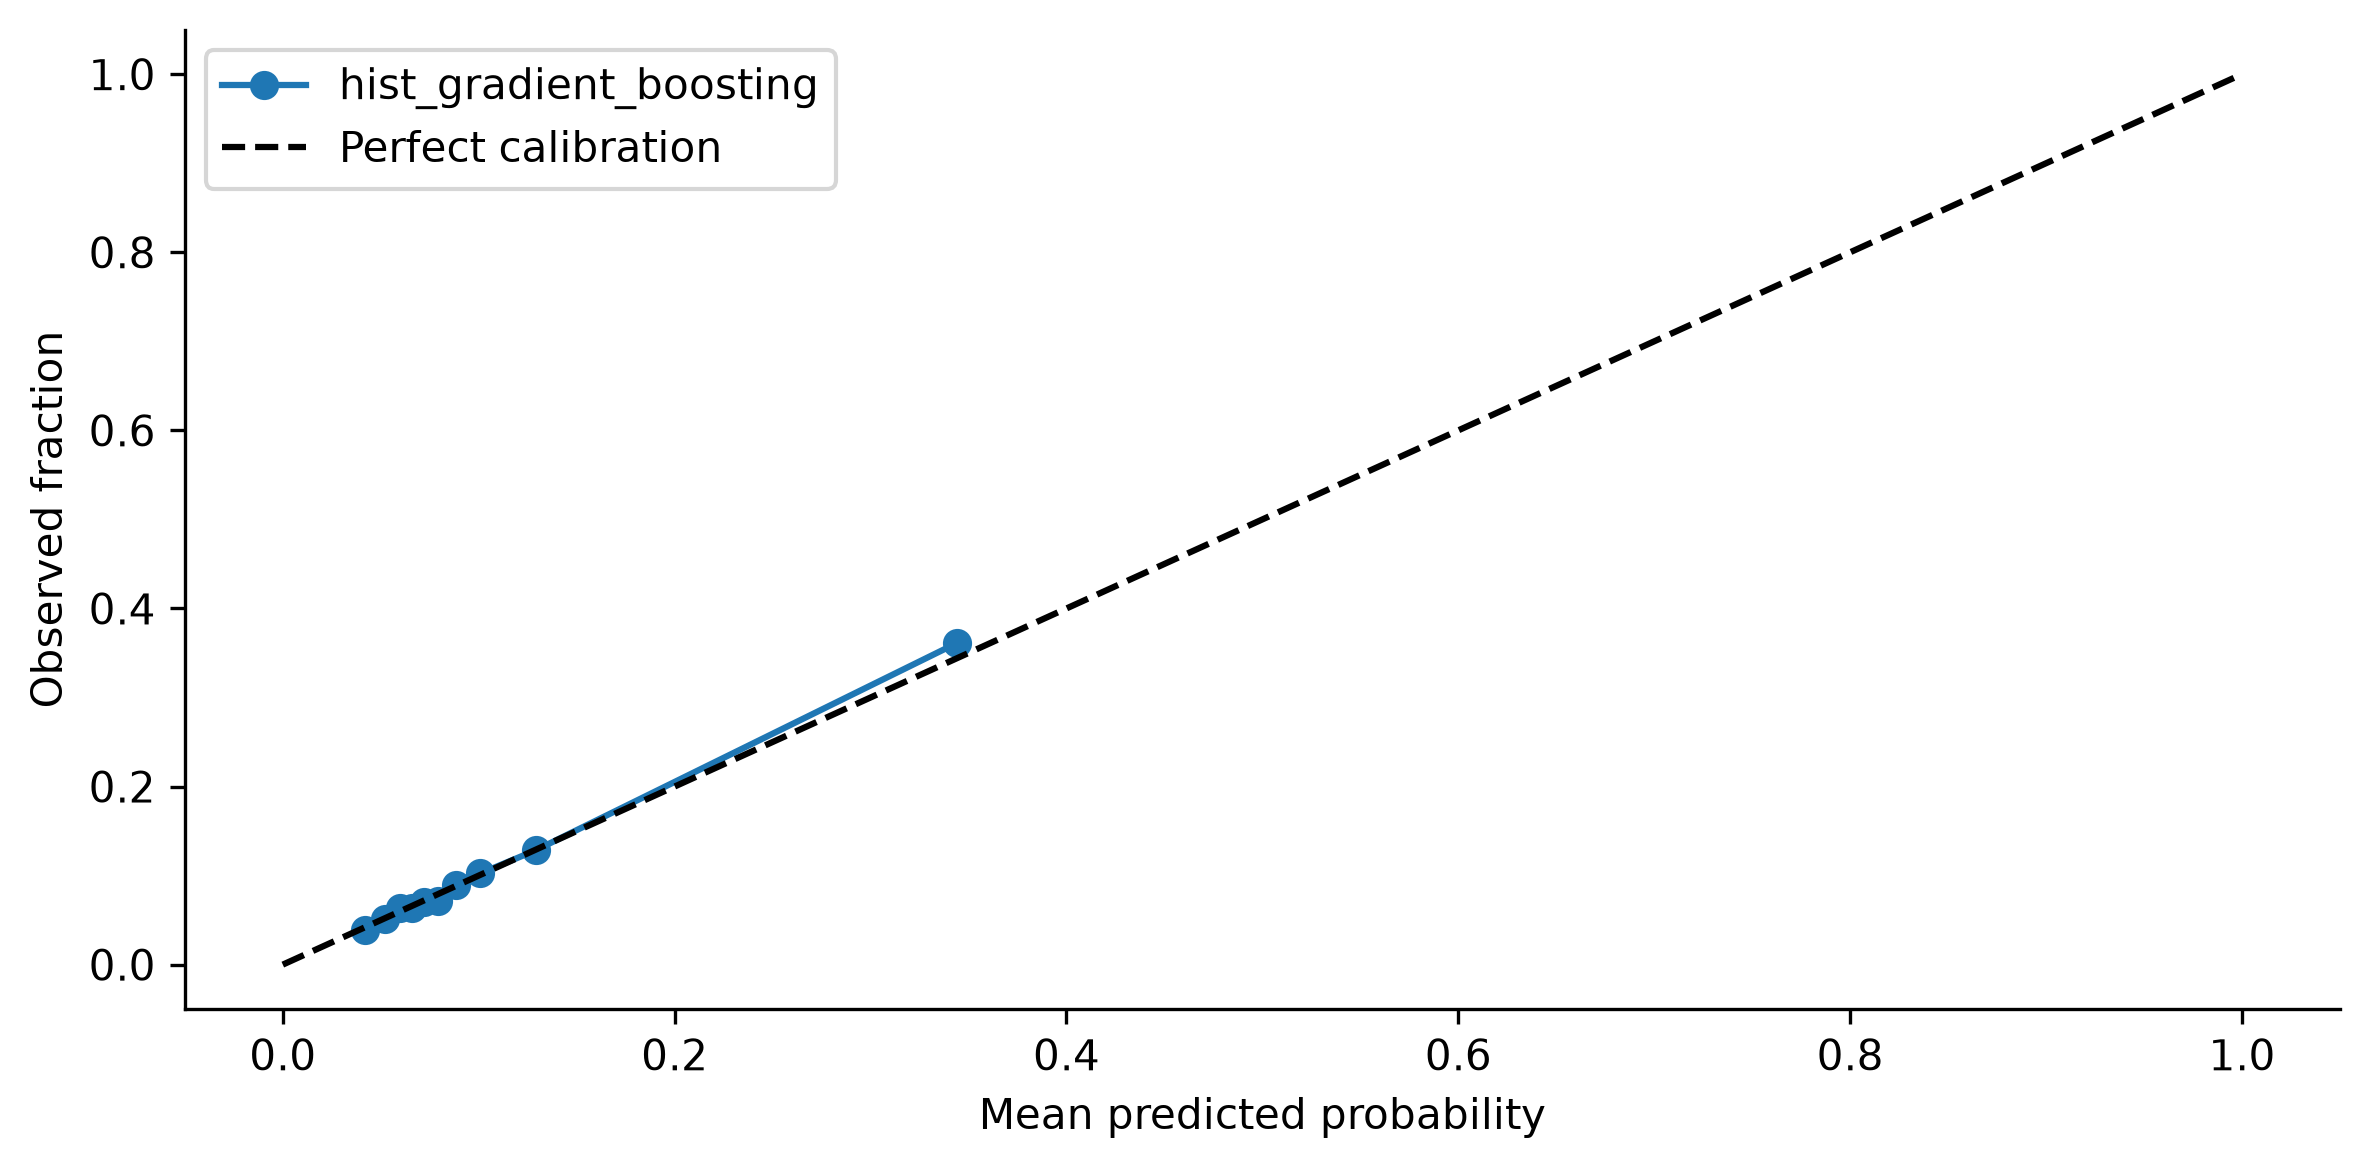

,model,roc_auc,average_precision,precision,recall,f1,f2,accuracy,balanced_accuracy,specificity,negative_predictive_value,mcc,brier,log_loss,alert_fraction,threshold,tn,fp,fn,tp
0,dl_functional,0.707848,0.332176,0.368843,0.334402,0.350779,0.340766,0.871267,0.633992,0.933581,0.923571,0.279932,0.199597,0.594767,0.094289,0.634973,37642,2678,3115,1565


,precision,recall,f1-score,support
0,0.923571,0.933581,0.928549,40320.000000
1,0.368843,0.334402,0.350779,4680.000000
accuracy,0.871267,0.871267,0.871267,0.871267
macro avg,0.646207,0.633992,0.639664,45000.000000
weighted avg,0.865880,0.871267,0.868461,45000.000000


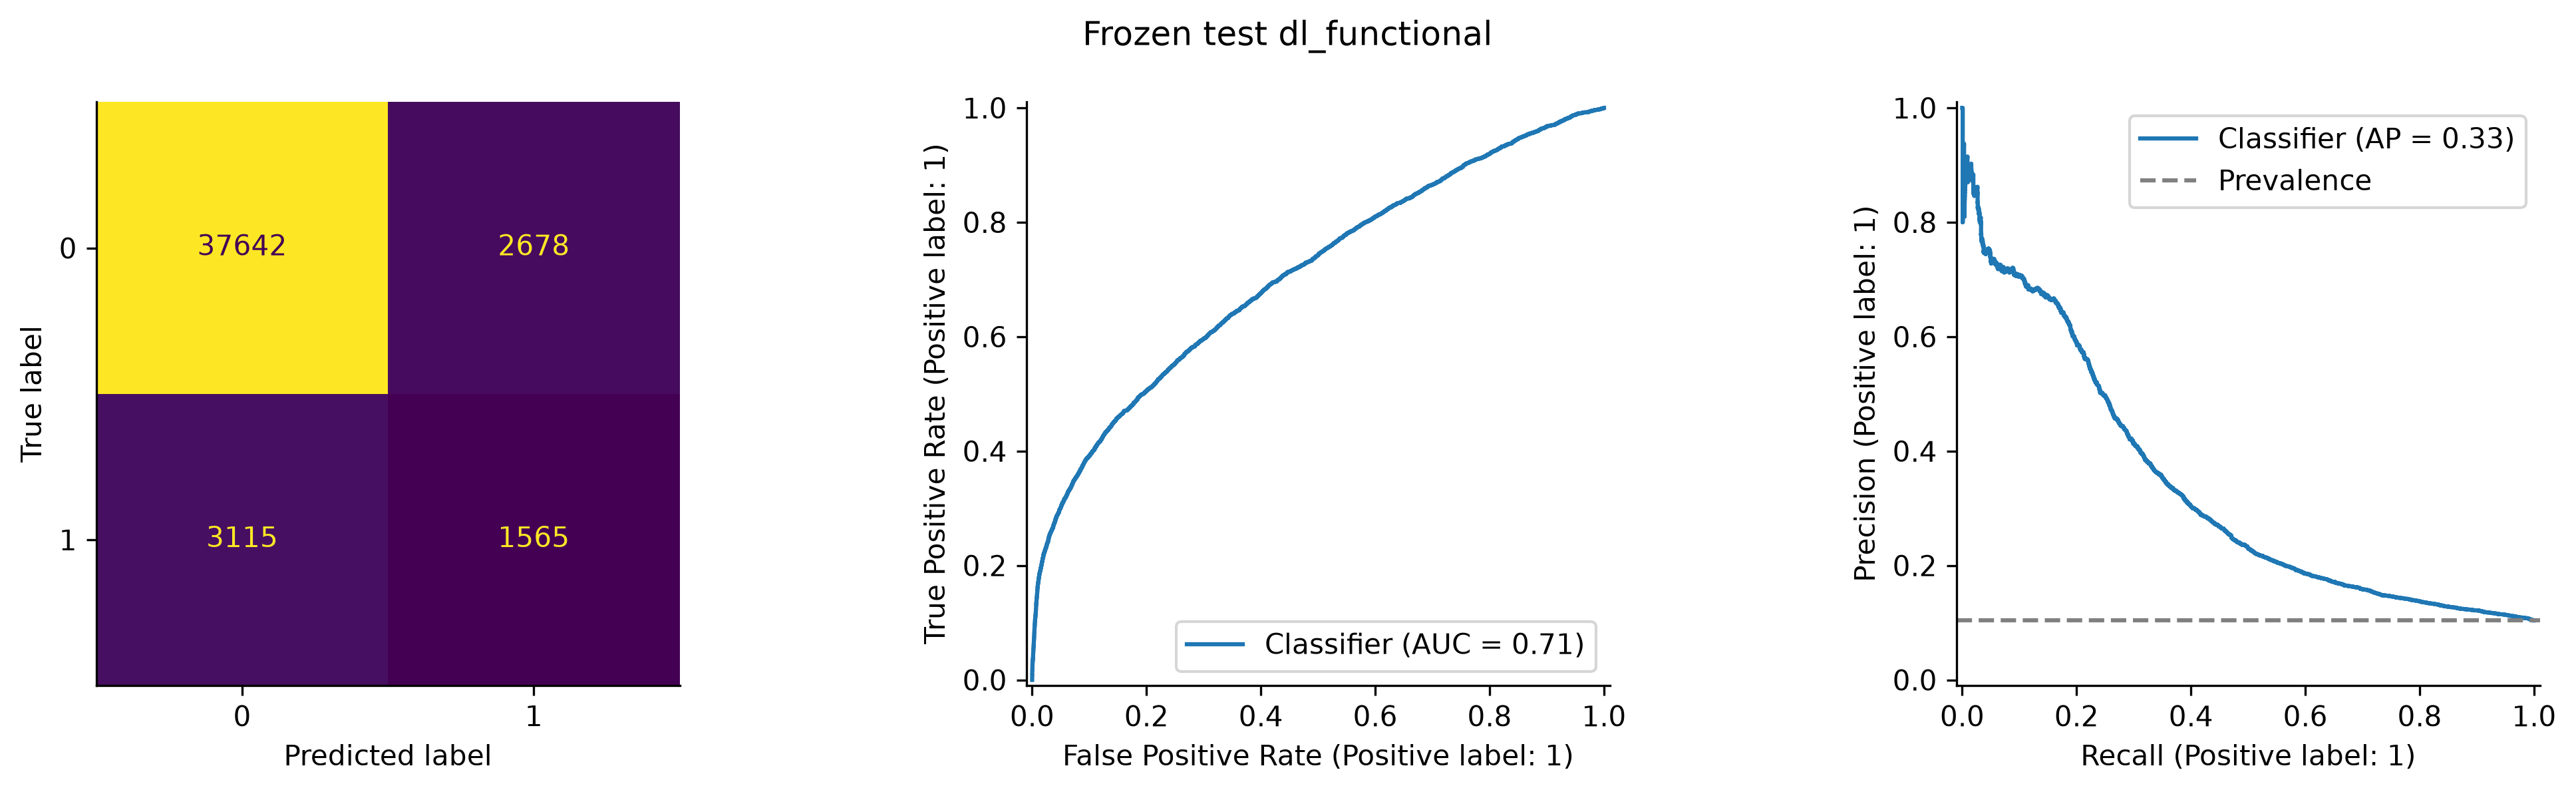

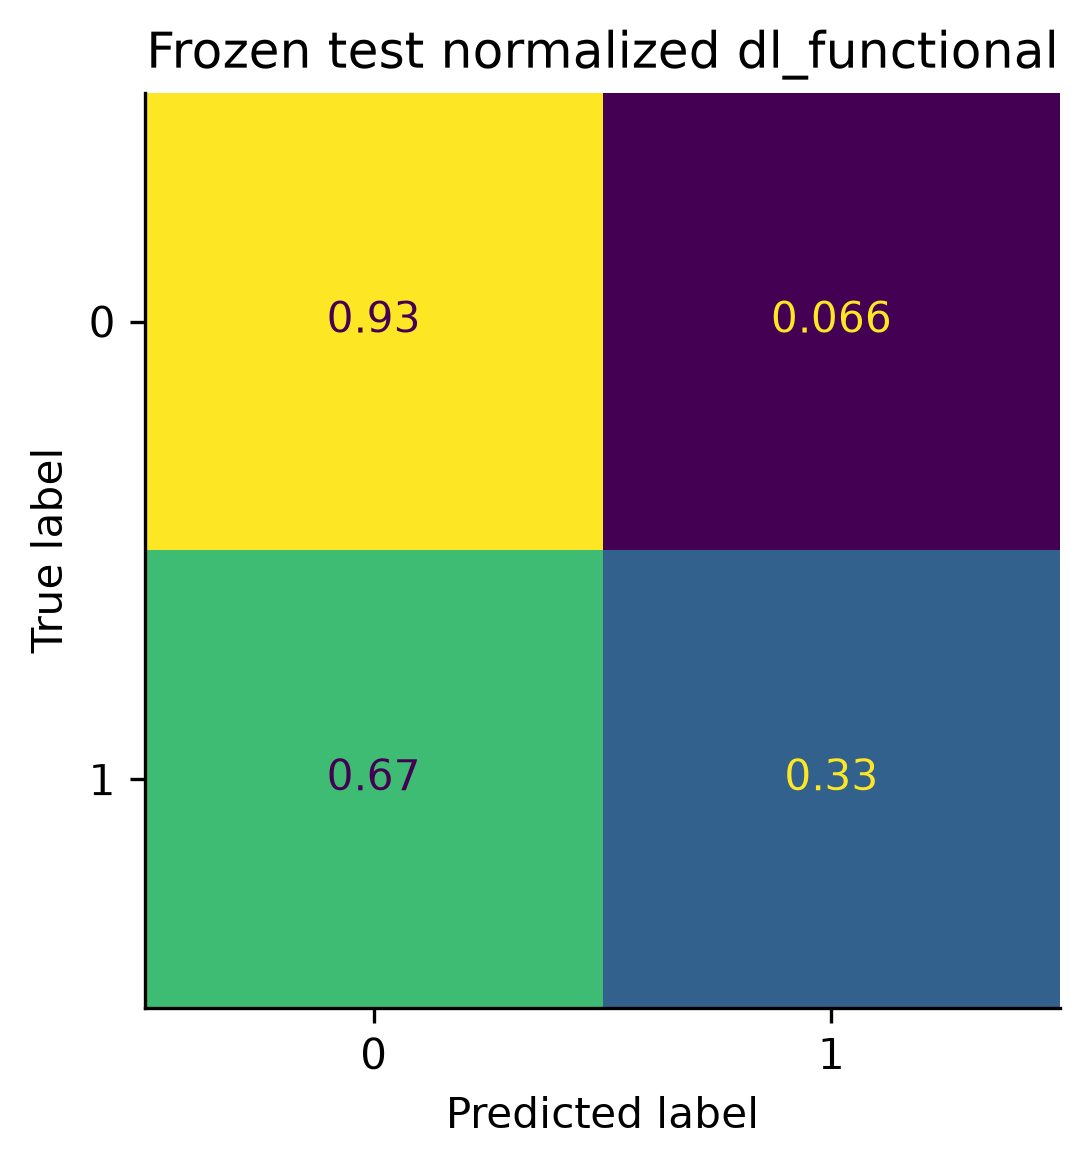

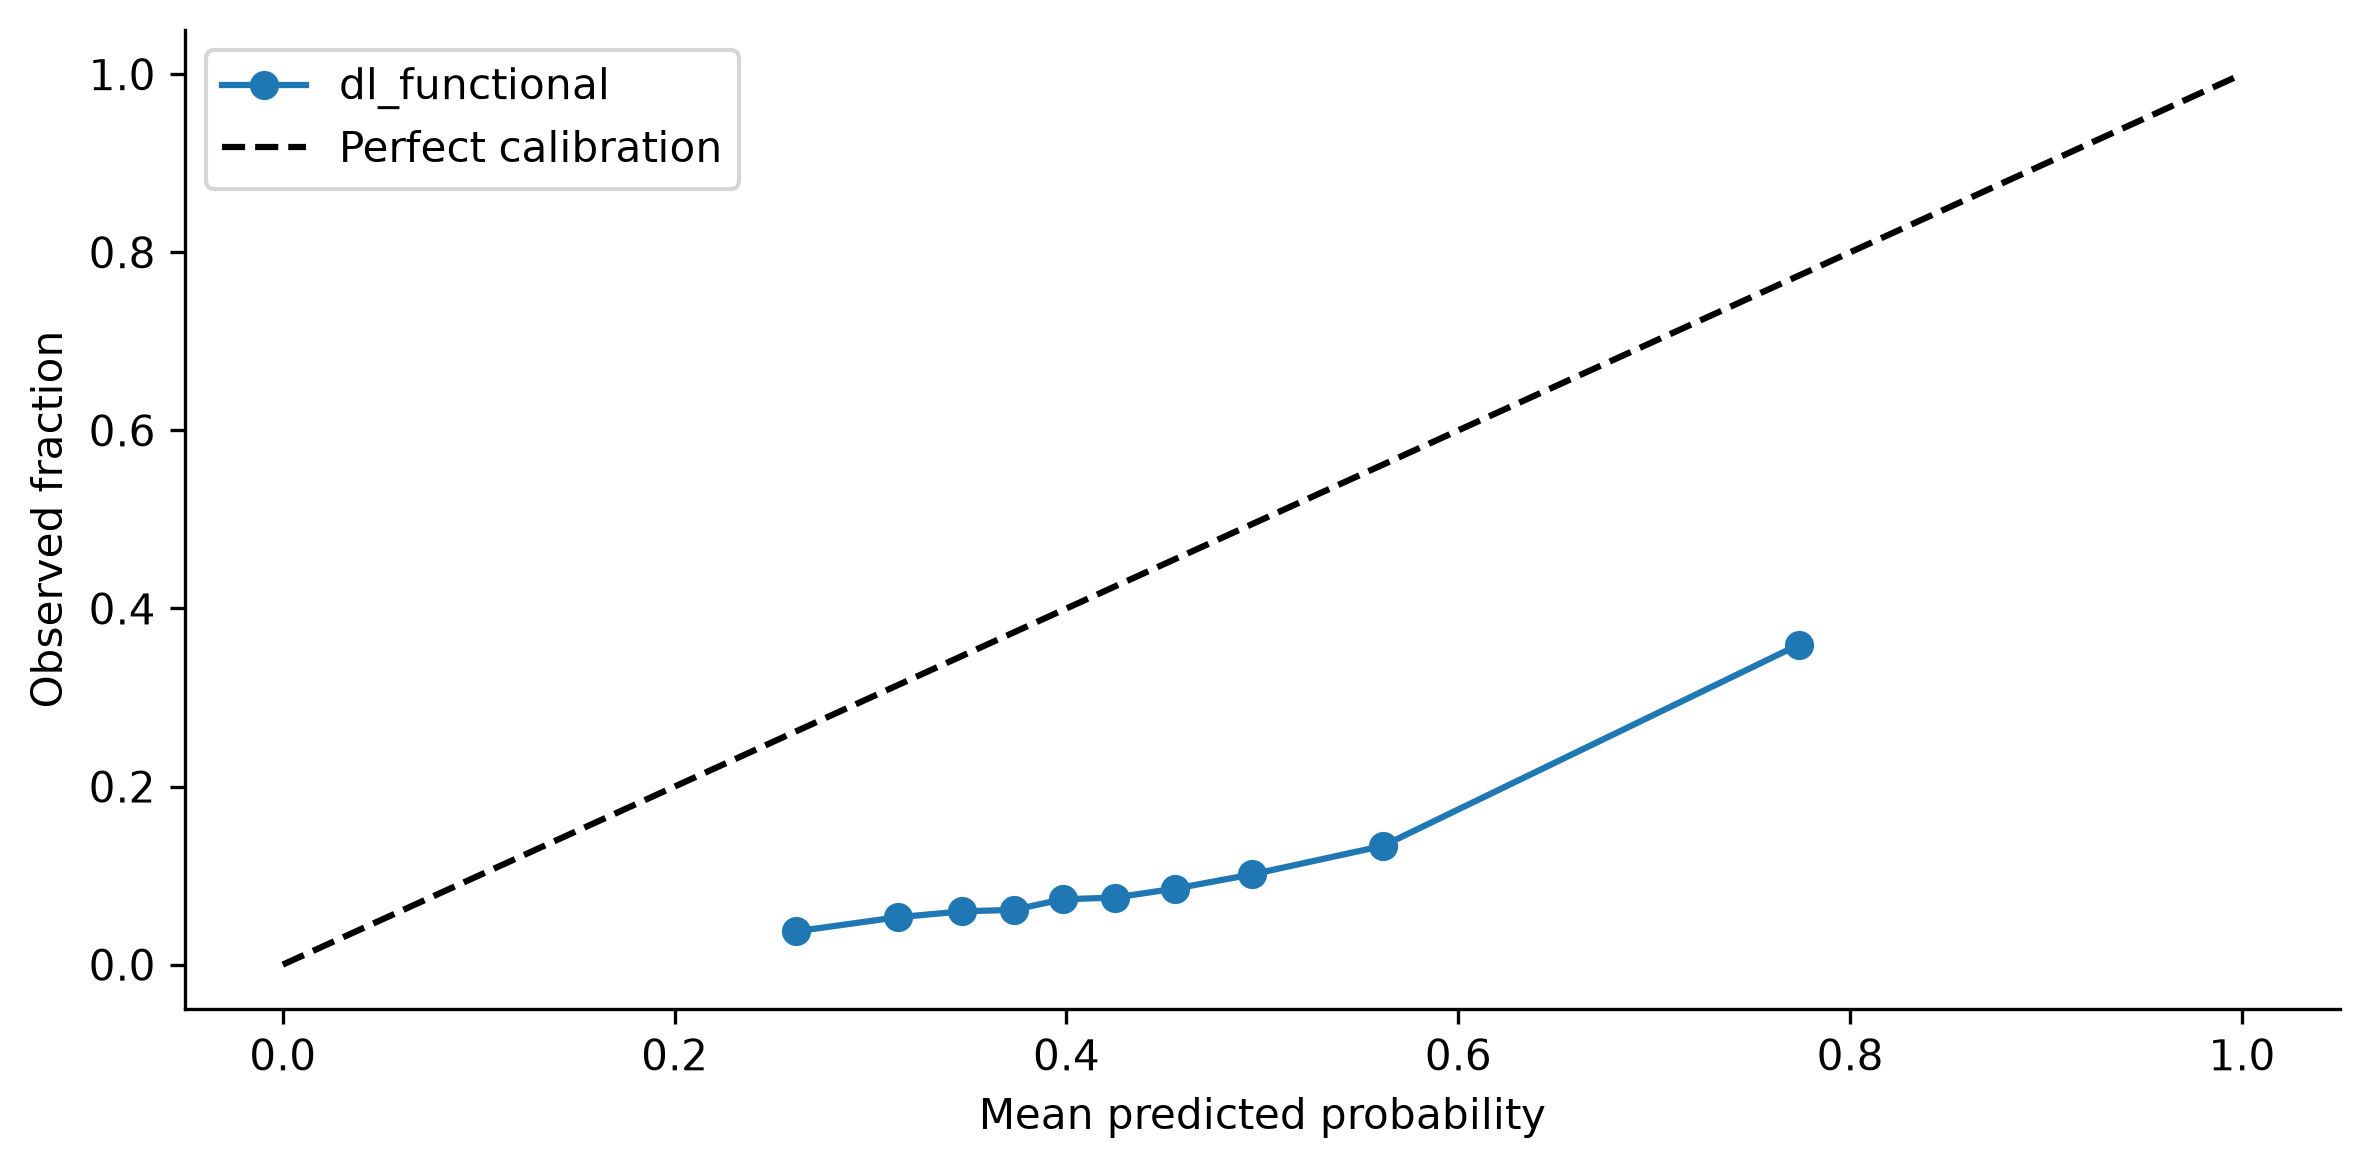

The original guard is unchanged; all values above use cached final-test predictions.


In [36]:
guard_before=(STATE/'test_evaluation_guard.json').read_bytes()
frozen_test_metrics=pd.read_csv(TABLES/'stage8_final_test_metrics.csv')
display(frozen_test_metrics)
for label,filename in [('hist_gradient_boosting','test_traditional_predictions.npz'),
                       ('dl_functional','test_deep_predictions.npz')]:
    cached=np.load(STATE/filename)
    y,p=cached['y'],cached['p']
    row=frozen_test_metrics.loc[frozen_test_metrics.model.eq(label)].iloc[0]
    threshold=float(row.threshold)
    measured=score_binary(y,p,threshold)
    for metric in ['roc_auc','average_precision','precision','recall','f1','accuracy','brier']:
        assert np.isclose(measured[metric],float(row[metric]),rtol=1e-10,atol=1e-10)
    display(pd.DataFrame([dict(model=label,**measured)]))
    run_log.evaluation(label,y,p,threshold,source='saved_frozen_test_predictions',split='test',
                       params={'model':label,'evidence':'saved_frozen_test_predictions','split':'test'})
    display(pd.DataFrame(classification_report(y,p>=threshold,output_dict=True,zero_division=0)).T)
    plot_binary(y,p,threshold,'Frozen test '+label)
    ConfusionMatrixDisplay.from_predictions(y,p>=threshold,normalize='true',colorbar=False)
    plt.title('Frozen test normalized '+label);save_figure('frozen_test_normalized_'+label)
    fraction,mean_probability=calibration_curve(y,p,n_bins=10,strategy='quantile')
    plt.plot(mean_probability,fraction,'o-',label=label)
    plt.plot([0,1],[0,1],'k--',label='Perfect calibration')
    plt.xlabel('Mean predicted probability');plt.ylabel('Observed fraction');plt.legend()
    save_figure('frozen_test_calibration_'+label)
assert (STATE/'test_evaluation_guard.json').read_bytes()==guard_before
print('The original guard is unchanged; all values above use cached final-test predictions.')

**Interpretation.** Test results match validation closely: AUC 0.706 for HistGradientBoosting and 0.708 for the Functional network (validation ≈0.712–0.713), with overlapping 95% bootstrap intervals (≈0.70–0.72). So my validation-based selection did not overfit. At the frozen thresholds HistGradientBoosting detects 1,421 of 4,680 preterm births (recall 0.30) with 2,045 false alerts. The Functional network detects 1,565 (recall 0.33) with 2,678 false alerts. The calibration plot shows the difference in probability quality: the tree model's probabilities follow the diagonal, while the class-weighted network overestimates risk (test Brier 0.200 vs 0.082).

## Final comparison and uncertainty

Test ROC-AUC with 500 stratified bootstrap resamples of the saved test predictions, alongside each model's validation results and training time.

In [37]:
def bootstrap_auc(y,p,repetitions=500,seed=SEED):
    y,p=np.asarray(y),np.asarray(p)
    positive,negative=np.flatnonzero(y==1),np.flatnonzero(y==0)
    rng=np.random.default_rng(seed)
    draws=[]
    for _ in range(repetitions):
        ids=np.concatenate([rng.choice(positive,len(positive),replace=True),
                            rng.choice(negative,len(negative),replace=True)])
        draws.append(roc_auc_score(y[ids],p[ids]))
    return np.quantile(draws,[.025,.975]),np.asarray(draws)

bootstrap_draws=pd.read_csv(TABLES/'stage8_bootstrap_auc_draws.csv')
display(bootstrap_draws.groupby('model').agg(['count','mean','std']) if 'model' in bootstrap_draws else bootstrap_draws.describe())
display(pd.read_csv(TABLES/'stage8_all_models.csv'))
print('No threshold or model is selected from these test diagnostics.')

,hist_gradient_boosting,dl_functional
count,500.000000,500.000000
mean,0.706374,0.707895
std,0.004300,0.004426
min,0.693670,0.695198
25%,0.703548,0.704618
50%,0.706463,0.707949
75%,0.709175,0.710896
max,0.719004,0.720770


,model,training_seconds,fit_rows,best_parameters,roc_auc_validation,average_precision_validation,precision_validation,recall_validation,f1_validation,accuracy_validation,brier_validation,threshold,api,training_rows,epochs_run,best_epoch,refit_seconds,roc_auc_test,average_precision_test,precision_test,recall_test,f1_test,accuracy_test,brier_test,auc_ci_lower,auc_ci_upper,bootstrap_reps,test_status
0,hist_gradient_boosting,24.496821,210000.0,"{""model__max_leaf_nodes"": 15, ""model__learning...",0.712484,0.341159,0.418177,0.315598,0.359717,0.883156,0.081128,0.200678,NaN,NaN,NaN,NaN,NaN,0.706275,0.331385,0.409983,0.303632,0.348883,0.882133,0.081585,0.698363,0.714657,500.0,evaluated_once
1,dl_functional,182.520664,NaN,"{""depth"": 1, ""units"": 96, ""dropout"": 0.3, ""lea...",0.712922,0.338774,0.374048,0.346154,0.359561,0.871756,0.199437,0.634973,functional,210000.0,23.0,19.0,90.634282,0.707848,0.332176,0.368843,0.334402,0.350779,0.871267,0.199597,0.699443,0.716155,500.0,evaluated_once
2,logistic,20.122348,210000.0,"{""model__class_weight"": null, ""model__C"": 1}",0.708295,0.335889,0.391513,0.331197,0.358838,0.876911,0.081307,0.167787,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_selected_not_evaluated
3,plain_logistic,5.815629,210000.0,"{""C"": 1.0, ""class_weight"": null, ""dual"": false...",0.708295,0.335889,0.391513,0.331197,0.358838,0.876911,0.081307,0.167787,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_selected_not_evaluated
4,random_forest,95.349028,210000.0,"{""model__min_samples_leaf"": 10, ""model__max_fe...",0.710725,0.335309,0.394320,0.335256,0.362398,0.877311,0.081361,0.176575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_selected_not_evaluated
5,dl_sequential,96.704098,NaN,"{""depth"": 1, ""units"": 96, ""dropout"": 0.3, ""lea...",0.713200,0.334237,0.375087,0.347436,0.360732,0.871933,0.201287,0.637516,sequential,210000.0,23.0,19.0,52.935663,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_selected_not_evaluated
6,svm,11.267252,6000.0,"{""model__gamma"": ""scale"", ""model__class_weight...",0.644714,0.285950,0.409148,0.279060,0.331809,0.883111,0.084969,0.120920,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_selected_not_evaluated
7,dummy,1.811282,210000.0,"{""constant"": null, ""random_state"": null, ""stra...",0.500000,0.104000,0.000000,0.000000,0.000000,0.896000,0.104000,0.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not_selected_not_evaluated


No threshold or model is selected from these test diagnostics.


## Save preprocessing and models; verify reload

My best traditional model is saved as a single joblib pipeline (preprocessing + classifier). My best deep model is saved in native Keras (`.keras`), legacy HDF5 (`.h5`) and TensorFlow SavedModel formats, with its preprocessing object. I reload each file and confirm that it reproduces the original predictions.

In [38]:
display(pd.read_csv(TABLES/'stage9_reload_proof.csv'))
if RUN_TRAINING and fitted_experiments:
    for name,model in fitted_experiments.items():
        safe=name.lower().replace(' ','_')
        path=EXPERIMENTS/f'{safe}.joblib'
        joblib.dump(model,path,compress=3)
        reloaded=joblib.load(path)
        before=model.predict_proba(X_train.head(5))
        after=reloaded.predict_proba(X_train.head(5))
        assert np.allclose(before,after)
        print(name,'training-example reload maximum difference:',float(np.max(np.abs(before-after))))
if RUN_TRAINING and RUN_DEEP_LEARNING:
    final_api_results=[]
    for api,(saved_model,training_inputs,validation_inputs) in neural_finalists.items():
        saved_model.save(EXPERIMENTS/f'best_{api}.keras')
        saved_model.export(EXPERIMENTS/f'best_{api}_savedmodel')
        saved_model.save(EXPERIMENTS/f'best_{api}.h5')
        check=tf.keras.models.load_model(EXPERIMENTS/f'best_{api}.keras')
        probe={k:v[:5] for k,v in training_inputs.items()} if isinstance(training_inputs,dict) else training_inputs[:5]
        before=saved_model.predict(make_tf_dataset(probe),verbose=0)
        after=check.predict(make_tf_dataset(probe),verbose=0)
        assert np.allclose(before,after,atol=1e-6)
        validation_probability=saved_model.predict(make_tf_dataset(validation_inputs),verbose=0).ravel()
        final_api_results.append(dict(api=api,**score_binary(y_validation,validation_probability,
                                    best_f1_threshold(y_validation,validation_probability))))
    joblib.dump({'numeric':numeric_dl,'ordinal':ordinal_dl,
                 'numeric_features':numeric_features,'categorical_features':categorical_features},
                EXPERIMENTS/'embedding_preprocessing.joblib')
    joblib.dump(preprocessor,EXPERIMENTS/'sequential_preprocessing.joblib')
    display(pd.DataFrame(final_api_results))
    pd.DataFrame(final_api_results).to_csv(EXPERIMENTS/'refitted_neural_finalists.csv',index=False)
# New-run best artifacts stay separate from the completed study's models/ directory.
if RUN_TRAINING:
    eligible=pd.DataFrame(experiment_rows)
    eligible=eligible.loc[eligible.cache_key.isin(['logistic','random_forest','hist_gradient_boosting','svm'])]
    winner=eligible.sort_values('average_precision',ascending=False).iloc[0]
    joblib.dump(fitted_experiments[winner.model],EXPERIMENTS/'best_traditional.joblib',compress=3)
    metadata={'traditional_model':winner.model,'traditional_threshold':float(winner.threshold),
        'threshold_scope':'development validation only; no independent test result',
        'input_columns':X_train.columns.tolist(),'raw_to_inputs':'readable_features.readable_features',
        'traditional_preprocessing':'Included inside best_traditional.joblib',
        'clinical_use_validated':False}
    if RUN_DEEP_LEARNING:
        best_api=pd.DataFrame(final_api_results).sort_values('average_precision',ascending=False).iloc[0]
        api=best_api.api
        best_network=neural_finalists[api][0]
        best_network.save(EXPERIMENTS/'best_deep.keras')
        best_network.save(EXPERIMENTS/'best_deep.h5')
        best_network.export(EXPERIMENTS/'best_deep_savedmodel')
        inputs_prep=preprocessor if api=='sequential' else {
            'numeric':numeric_dl,'ordinal':ordinal_dl,
            'numeric_features':numeric_features,'categorical_features':categorical_features}
        joblib.dump(inputs_prep,EXPERIMENTS/'best_deep_preprocessing.joblib')
        metadata.update(deep_api=api,deep_threshold=float(best_api.threshold))
    (EXPERIMENTS/'inference_metadata.json').write_text(json.dumps(metadata,indent=2))


,artifact,max_absolute_difference,passed,sample_rows
0,best_traditional.joblib,0.0,True,10
1,best_deep.keras,0.0,True,10
2,best_deep_savedmodel,0.0,True,10
3,best_deep.h5,0.0,True,10


## Saved files and report

The model files listed below are the ones I share in the Google Drive folder. Methodology, results and discussion are in the report.

In [39]:
print('Report:',shown(INPUT_ROOT/'reports/REPORT.pdf'))
print('Source guide:',shown(GUIDE))
display(pd.read_csv(TABLES/'stage9_artifact_manifest.csv'))
run_log.finish()
print('Run logged to:',shown(run_log.path))

Report: reports/REPORT.pdf
Source guide: Data/UserGuide2024.pdf


,path,bytes,sha256
0,models/best_deep.h5,213024,3cccc7cc9b22908d4f044a3d751a87d1acb70b20950b21...
1,models/best_deep.keras,222956,6cc0fcbdce556d917229cafe1c791372a7740879613eef...
2,models/best_deep_preprocessing.joblib,7968,863c0751f6a0f4d1bbbc3539eecb158a830500ad84bebc...
3,models/best_deep_savedmodel/fingerprint.pb,95,d26c08deb6448acd0e312b6be5caad09dfa881061cc740...
4,models/best_deep_savedmodel/saved_model.pb,219860,5e3cbdafc042b351589206b68ca50c713083699b8e652c...
5,models/best_deep_savedmodel/variables/variable...,68221,cac05929ce7f8a586e955a6d20d9eb2ab60f3eeef37be5...
6,models/best_deep_savedmodel/variables/variable...,2711,ba1fc9e03f1da2a8b6a9bd9107bae8a93d3b02141276fe...
7,models/best_traditional.joblib,118014,4435938c1c03197d098bce177fe7f243656b402c3979c7...
8,models/best_traditional_preprocessing.joblib,9811,d892c0a1f2a164e561a1c1115e2412f64b8197a8e0f28d...
9,models/core_preprocessing.joblib,9135,ca78d872abfb398f7c4a7f4deedf4deebdc7eed5ce81af...


Run logged to: runs/review/20261020T200618Z_02_models_and_evaluation_d5e48f83


## TensorBoard — Keras training curves and scikit-learn metrics together

Every execution of this notebook writes TensorBoard logs under `runs/`:

| TensorBoard location | Contents |
|---|---|
| `runs/live/<run>/neural/<model>/tensorboard/train`, `/validation` | Keras loss, ROC-AUC and PR-AUC per epoch (training runs only) |
| `runs/live/<run>/neural/<model>/tensorboard/sklearn_validation` | scikit-learn ROC-AUC, AP, precision, recall, F1/F2, Brier, log loss after every epoch |
| `runs/*/<run>/sklearn_metrics/validation/<model>` | scikit-learn scalars, PR curve, confusion matrix and ROC/PR/calibration images, classification report, threshold sweep, HParams |
| `runs/*/<run>/sklearn_metrics/test/<model>` | the same for the frozen test predictions of the two finalists |
| `runs/*/<run>/sklearn_metrics/singletons/<model>` | the finalists restricted to singleton births |
| `runs/*/<run>/sklearn_search/<family>`, `learning_curves/<model>` | randomized-search candidates (step = candidate) and learning curves (step = training records) |
| `runs/review/<run>/recorded_histories/<model>` | the epoch history saved by my completed training run, labelled with its source file |

Useful tabs: **Scalars** (filter `sklearn_` or `epoch_`), **PR Curves**, **Images** (confusion matrices, ROC/PR/calibration), **Text** (classification reports, provenance) and **HParams** (all models ranked by the same scikit-learn metrics). From a terminal: `tensorboard --logdir runs`. Set `SHOW_TENSORBOARD=True` to open it inside the notebook.

In [40]:
print('TensorBoard log directory:',shown(OUTPUT_ROOT/'runs'))
print('Terminal command: tensorboard --logdir',shown(OUTPUT_ROOT/'runs'))
if SHOW_TENSORBOARD:
    %load_ext tensorboard
    %tensorboard --logdir {str(OUTPUT_ROOT/'runs')}

TensorBoard log directory: runs
Terminal command: tensorboard --logdir runs


## Conclusion

My classical and deep-learning models reach the same modest ceiling on pre-delivery information: ROC-AUC ≈0.71 and AP ≈0.33 on the untouched test set, about three times the 10.4% prevalence. HistGradientBoosting matches the Functional network's ranking performance and gives far better-calibrated probabilities, at a fraction of the training time. The error analysis shows that much of the detection comes from multiple pregnancies, while most preterm singletons, especially in first pregnancies, are missed. This is a retrospective research benchmark, not a clinical screening tool. Making it useful would need inputs recorded at a defined point in pregnancy, temporal validation on a later birth year, and calibrated probabilities. [Report](../reports/REPORT.md) · [CDC user guide](../Data/UserGuide2024.pdf).